Deconvolução de picos de XPS (réplica da Parte 5 do notebook da aula)
=====================================================================

Este notebook repete, passo a passo, a **Parte 5 – Deconvolução de picos (exemplo com dados de XPS)** do notebook *ATP-201 – Regressão não-linear* (autor: Daniel R. Cassar), agora com os meus dados.

A receita é a mesma da aula: picos Lorentzianos, uma sigmoide por pico, linha de base constante, palpite pela altura, o algoritmo de ajuste padrão do `lmfit` e, no fim, a estratégia avançada com picos Voigt.

O que **precisou** mudar, porque os meus dados são diferentes:

1. **Leitura:** os dados estão em arquivos `.avg` (texto), e não em Excel. Por isso existe a função de suporte `le_arquivo_avg`. Ela também converte a energia cinética em energia de ligação.
2. **Valores numéricos:** limiar de corte, centros, larguras, alturas e constante foram escolhidos olhando para os **meus** gráficos, como a aula faz com os dados dela.
3. **Número de picos:** O 1s com 2 picos (como na aula), C 1s com 4 e Si 2p com 1.
4. **Nome da coluna:** `Counts` em vez de `Counts / s`, porque o meu arquivo traz contagens e não contagens por segundo.

## Importações e funções de suporte

As importações são as mesmas do notebook da aula.

In [1]:
import io
import urllib.request

import numpy as np
import pandas as pd
import seaborn as sns

from lmfit import Model
from lmfit.models import (
    ConstantModel,
    ExponentialModel,
    GaussianModel,
    LorentzianModel,
    StepModel,
    VoigtModel,
)

from matplotlib import pyplot as plt
from scipy import stats
from scipy.stats import linregress
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

### Função nova: leitura do arquivo `.avg`

Esta é a única função que não existe no notebook da aula. Ela substitui o `pd.read_excel`:

- `open(...)` e `readlines()`: abrem o arquivo e guardam cada linha em uma lista.
- `linha.startswith("...")`: procura as linhas que interessam.
- Linha `DS_SOPROPID_ENERGY`: energia do raio X (1486,68 eV).
- Linha **seguinte** a `$SPACEAXES`: início, passo e número de pontos do eixo de energia cinética.
- Linhas `LIST@`: as contagens, 4 por linha. `split("=")[1]` descarta o `LIST@ 12`, que é só a posição do primeiro valor da linha.
- **Energia de ligação = energia do raio X − energia cinética.**
- O resultado é um `DataFrame` com as colunas `eV` e `Counts`, no mesmo formato que a aula usa.

In [2]:
def le_arquivo_avg(caminho):
    """Lê um arquivo .avg exportado pelo Avantage.

    Args:
      caminho: string
        Nome (ou caminho) do arquivo .avg.

    Return:
      DataFrame com as colunas `eV` (energia de ligação) e `Counts`.
    """

    with open(caminho, encoding="latin-1") as arquivo:
        linhas = arquivo.readlines()

    contagens = []

    for i, linha in enumerate(linhas):
        if linha.startswith("DS_SOPROPID_ENERGY"):
            energia_foton = float(linha.split("=")[-1])

        elif linha.startswith("$SPACEAXES"):
            numeros = linhas[i + 1].split("=")[1].split(",")
            inicio = float(numeros[0])
            passo = float(numeros[1])
            n_pontos = int(numeros[2])

        elif linha.startswith("LIST@"):
            valores = linha.split("=")[1].split(",")
            contagens += [float(v) for v in valores if v.strip()]

    energia_cinetica = inicio + passo * np.arange(n_pontos)
    energia_ligacao = energia_foton - energia_cinetica

    df = pd.DataFrame({"eV": energia_ligacao, "Counts": contagens})

    return df

### Análise de resíduos (cópia idêntica da aula)

Função copiada sem nenhuma alteração da seção *Análise de resíduos* (Parte 1) do notebook da aula.

**Atenção:** como é uma cópia idêntica, o primeiro painel continua com o rótulo `Temperatura (K)`, que vem do exemplo de viscosidade da aula. Nos gráficos deste notebook, esse eixo é a energia de ligação (eV).

In [3]:
def analise_residuos(x_real, y_real, y_predito):
    residuos = y_real - y_predito

    figura, eixos = plt.subplots(1, 3, figsize=(14, 4))

    # resíduos contra a variável independente
    eixos[0].axhline(0, color="k", lw=1)
    eixos[0].plot(x_real, residuos, "o", markersize=3)
    eixos[0].set(xlabel="Temperatura (K)", ylabel="Resíduo", title="Resíduos vs. x")

    # histograma
    eixos[1].hist(residuos, bins=20)
    eixos[1].axvline(residuos.mean(), ls="--", c="red", label="Média")
    eixos[1].set(xlabel="Resíduo", ylabel="Contagem", title="Distribuição")
    eixos[1].legend()

    # gráfico Q-Q contra a distribuição normal
    stats.probplot(residuos, dist="norm", plot=eixos[2])
    eixos[2].set_title("Gráfico Q-Q")
    eixos[2].set(
        xlabel="Quantis teóricos (normal)", ylabel="Valores ordenados", title="Gráfico Q-Q"
    )

    figura.tight_layout()

    print(f"p-valor de Shapiro-Wilk dos resíduos: {stats.shapiro(residuos).pvalue:.3g}")

## Survey

A aula não tem survey. Aqui ele aparece só como gráfico, do mesmo jeito que a aula plota os dados brutos (`df.plot`), para mostrar quais elementos existem na amostra.

In [4]:
df_survey = le_arquivo_avg("XPS_Survey.avg")

df_survey.plot("eV", "Counts");

FileNotFoundError: [Errno 2] No such file or directory: 'XPS_Survey.avg'

## O 1s – deconvolução de picos

Esta seção mostra uma forma de tratar os dados de XPS da região O 1s usando o `lmfit`, seguindo a aula.

### Carregando os dados

Os dados de XPS estão no arquivo `O1s_Scan.avg`. A função `le_arquivo_avg` (definida no início) faz o papel do `pd.read_excel` da aula.

In [ ]:
ARQUIVO_XPS = "O1s_Scan.avg"

df = le_arquivo_avg(ARQUIVO_XPS)

df = df.dropna()

Vamos ver os dados que temos.

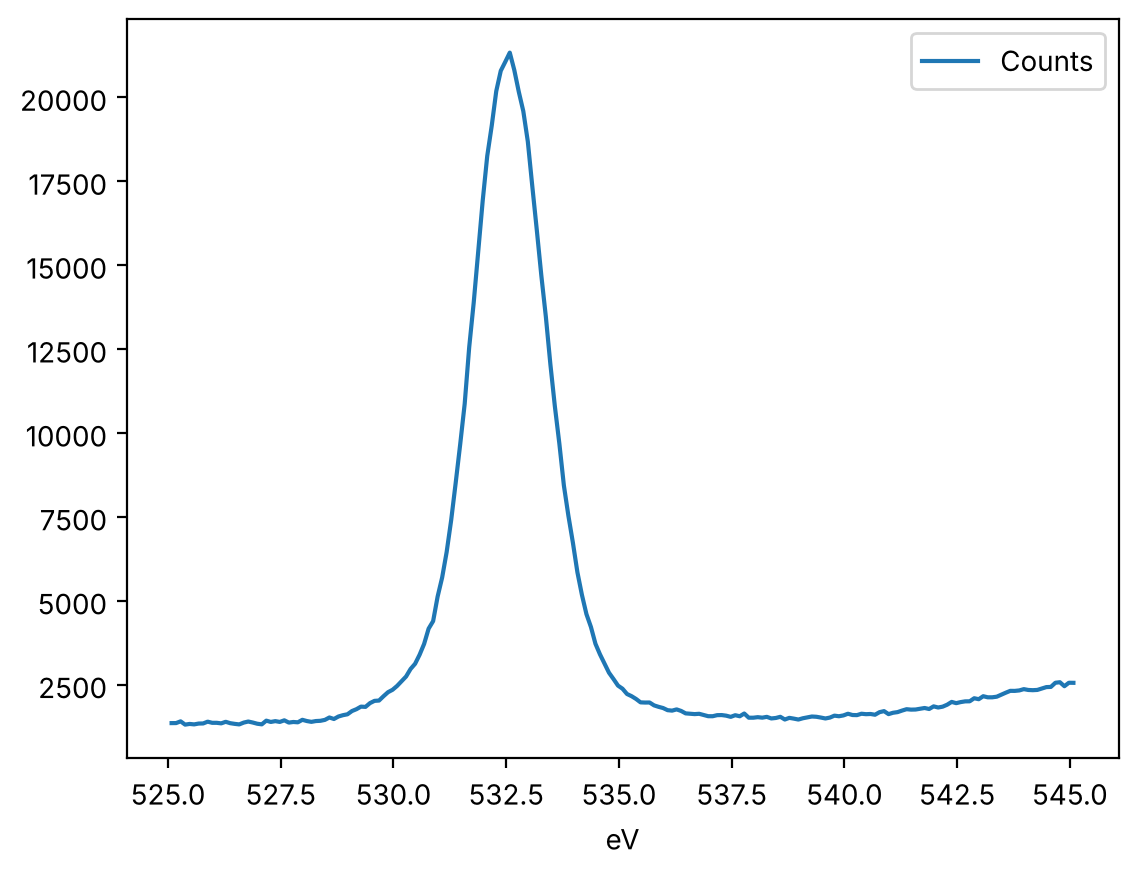

In [ ]:
df.plot("eV", "Counts");

Para este estudo em particular, não queremos dados com Binding Energy acima de 540 eV. Acima disso o fundo volta a subir e não traz informação sobre os picos.

In [ ]:
logic = df["eV"] <= 540
df = df.loc[logic]

Vamos checar os dados novamente.

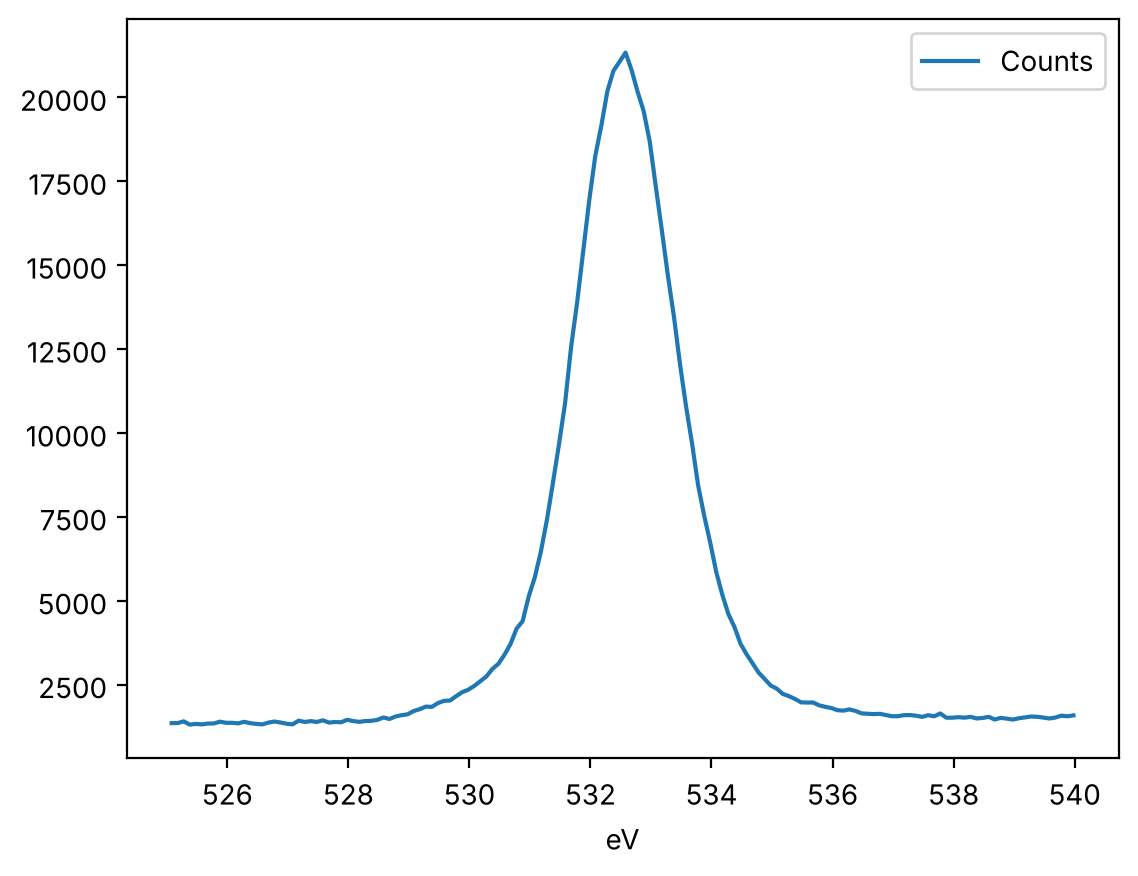

In [ ]:
df.plot("eV", "Counts");

Deste gráfico observamos um pico principal perto de 532,6 eV, com um leve ombro do lado de maior energia, e uma linha de base: o sinal não chega a zero e é um pouco mais alto do lado esquerdo (maior energia) do que do direito.

### Comentário sobre picos com base direita e esquerda com diferentes valores

Igual à aula: muitas vezes, picos obtidos por espectroscopia têm valores diferentes para as bases que estão à direita e à esquerda do pico. Apenas uma função de pico junto com uma linha de base constante *não* são capazes de descrever essa situação. A estratégia é adicionar uma curva sigmoidal.

### Definição do modelo

Assim como na aula, vamos modelar os picos como Lorentzianas.

In [ ]:
modelo_pico1 = LorentzianModel(prefix="p1_")
modelo_pico2 = LorentzianModel(prefix="p2_")

Vamos agora associar uma **linha de base sigmoidal** para cada pico, usando a função degrau (`StepModel`) com `form="logistic"` e `independent_vars=["x"]`, exatamente como na aula. Como temos 2 picos, criamos 2 sigmoides.

In [ ]:
modelo_sigmoid1 = StepModel(
    prefix="sigmoid1_", form="logistic", independent_vars=["x"]
)
modelo_sigmoid2 = StepModel(
    prefix="sigmoid2_", form="logistic", independent_vars=["x"]
)

A linha de base será um modelo constante.

In [ ]:
modelo_constante = ConstantModel(prefix="const_")

Finalmente, construímos o modelo composto pela combinação linear dos modelos individuais.

In [ ]:
modelo_composto = (
    modelo_pico1
    + modelo_sigmoid1
    + modelo_pico2
    + modelo_sigmoid2
    + modelo_constante
)

### Palpite inicial dos parâmetros

Vamos criar os parâmetros do modelo composto.

In [ ]:
params_pico1 = modelo_pico1.make_params()
params_pico2 = modelo_pico2.make_params()
params_sigmoid1 = modelo_sigmoid1.make_params()
params_sigmoid2 = modelo_sigmoid2.make_params()
params_constante = modelo_constante.make_params()

params = (
    params_pico1
    + params_sigmoid1
    + params_pico2
    + params_sigmoid2
    + params_constante
)

params

name,value,initial value,min,max,vary,expression
p1_amplitude,1.00000000,None,-inf,inf,True,
p1_center,0.00000000,None,-inf,inf,True,
p1_sigma,1.00000000,None,0.00000000,inf,True,
p1_fwhm,2.00000000,None,-inf,inf,False,2.0000000*p1_sigma
p1_height,0.31830990,None,-inf,inf,False,"0.3183099*p1_amplitude/max(1e-15, p1_sigma)"
sigmoid1_amplitude,1.00000000,None,-inf,inf,True,
sigmoid1_center,0.00000000,None,-inf,inf,True,
sigmoid1_sigma,1.00000000,None,-inf,inf,True,
p2_amplitude,1.00000000,None,-inf,inf,True,
p2_center,0.00000000,None,-inf,inf,True,


Agora iremos restringir os parâmetros. Assim como na aula, os valores abaixo foram obtidos olhando para os gráficos dos dados.

O pico principal parece estar próximo de 532,6 eV. Vamos deixar um espaço de manobra para ele controlando os valores mínimo e máximo do centro. Chamaremos este de pico `p1`. A altura parece estar perto de 21.000.

**Nota:** como na aula, usaremos uma altura menor (17.000) porque os dados não começam do 0. Também como na aula, "destravamos" a altura (`expr=""`) e calculamos a amplitude a partir dela.

In [ ]:
params["p1_center"].set(value=532.6, min=531.9, max=533.2)
params["p1_sigma"].set(value=0.9)

params["p1_height"].set(vary=True, value=17000, min=0, expr="")
params["p1_amplitude"].set(vary=False, expr="pi * p1_sigma * p1_height")

O segundo pico seria o ombro do lado de maior energia, perto de 533,6 eV. Chamaremos este de pico `p2`. Sua altura parece estar perto de 2.000.

In [ ]:
params["p2_center"].set(value=533.6, min=533.0, max=534.4)
params["p2_sigma"].set(value=1.0)

params["p2_height"].set(vary=True, value=2000, min=0, expr="")
params["p2_amplitude"].set(vary=False, expr="pi * p2_sigma * p2_height")

Como na aula, vamos fixar o centro e o desvio padrão de cada sigmoide como iguais ao centro e ao desvio padrão do seu pico.

In [ ]:
params["sigmoid1_center"].set(vary=False, expr="p1_center")
params["sigmoid1_sigma"].set(vary=False, expr="p1_sigma")

params["sigmoid2_center"].set(vary=False, expr="p2_center")
params["sigmoid2_sigma"].set(vary=False, expr="p2_sigma")

Por fim, olhando para o gráfico podemos dar um palpite para a constante da linha de base.

In [ ]:
params["const_c"].set(value=1400)

### Ajuste do modelo

O ajuste e a análise dos resultados seguem da mesma maneira.

In [ ]:
dados_x = df["eV"].values
dados_y = df["Counts"].values

resultado_fit = modelo_composto.fit(dados_y, params, x=dados_x)

print(resultado_fit.fit_report())

[[Model]]
    ((((Model(lorentzian, prefix='p1_') + Model(step, prefix='sigmoid1_', form='logistic')) + Model(lorentzian, prefix='p2_')) + Model(step, prefix='sigmoid2_', form='logistic')) + Model(constant, prefix='const_'))
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 2787
    # data points      = 150
    # variables        = 9
    chi-square         = 1380321.67
    reduced chi-square = 9789.51540
    Akaike info crit   = 1387.07877
    Bayesian info crit = 1414.17449
    R-squared          = 0.99969028
[[Variables]]
    p1_amplitude:        5190.50987 +/- 552.105172 (10.64%) == 'pi * p1_sigma * p1_height'
    p1_center:           532.218597 +/- 0.01134448 (0.00%) (init = 532.6)
    p1_sigma:            0.53650253 +/- 0.00405264 (0.76%) (init = 0.9)
    p1_fwhm:             1.07300506 +/- 0.00810528 (0.76%) == '2.0000000*p1_sigma'
    p1_height:           3079.55789 +/- 312.737670 (10.16%) (init = 17000)
    sigmoid1_amplitude:  47379.5148 +/- 1522.771

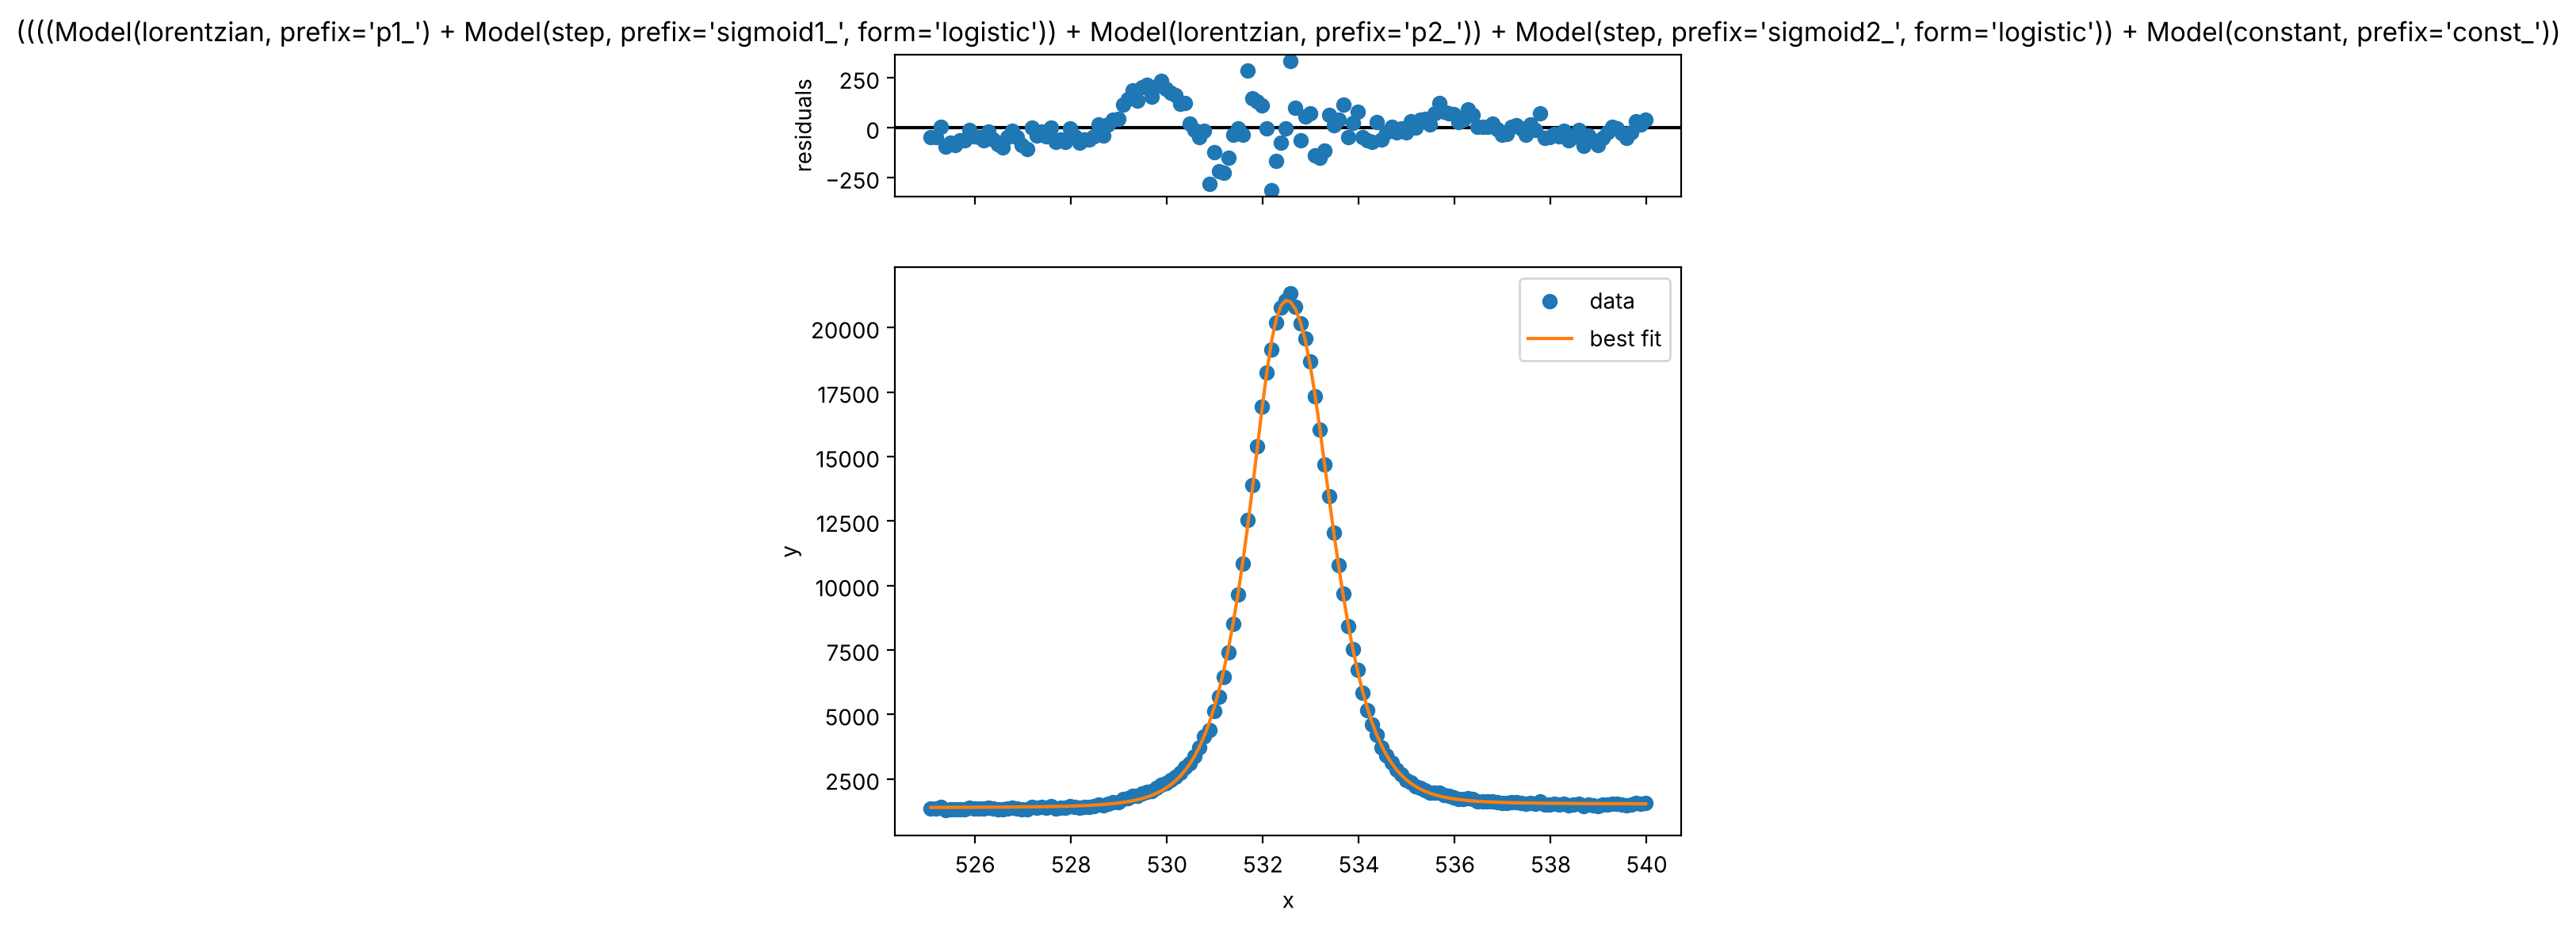

In [ ]:
resultado_fit.plot();

Vamos observar a análise dos resíduos.

p-valor de Shapiro-Wilk dos resíduos: 2.82e-05


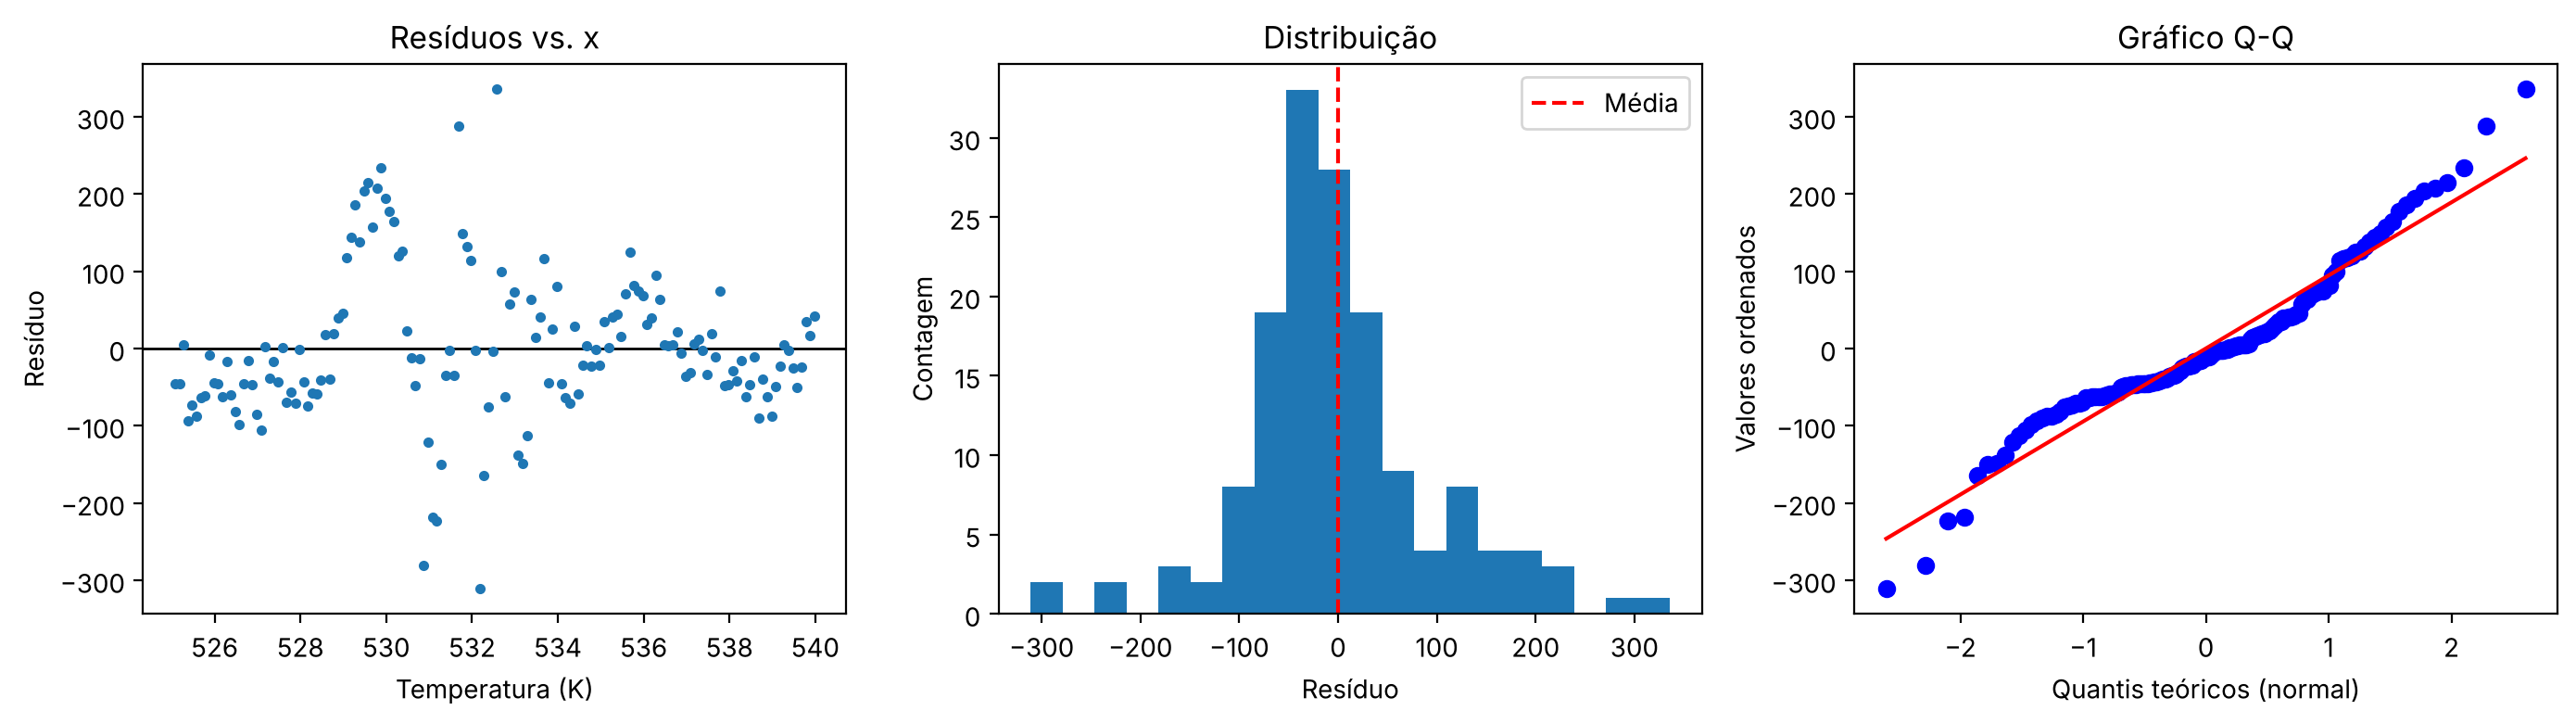

In [ ]:
analise_residuos(dados_x, dados_y, resultado_fit.best_fit)

### A contribuição de cada componente

Novamente, podemos investigar a contribuição de cada componente.

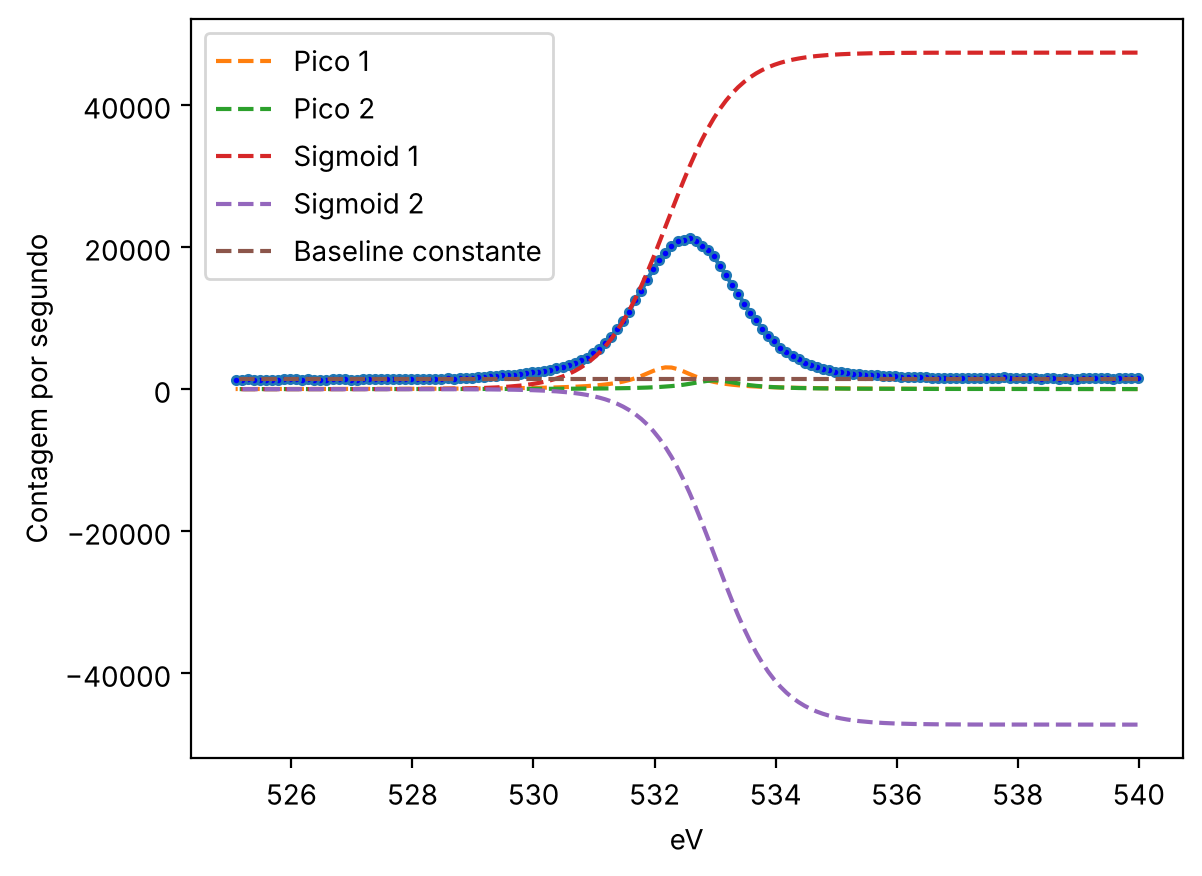

In [ ]:
componentes = resultado_fit.eval_components(x=dados_x)

fig, eixo = plt.subplots()
eixo.plot(dados_x, dados_y, marker="o", markerfacecolor="blue", markersize=3)
eixo.plot(dados_x, componentes["p1_"], "--", label="Pico 1")
eixo.plot(dados_x, componentes["p2_"], "--", label="Pico 2")
eixo.plot(dados_x, componentes["sigmoid1_"], "--", label="Sigmoid 1")
eixo.plot(dados_x, componentes["sigmoid2_"], "--", label="Sigmoid 2")
eixo.plot(
    dados_x,
    np.ones(len(dados_x)) * componentes["const_"],
    "--",
    label="Baseline constante",
)
eixo.set(xlabel="eV", ylabel="Contagem por segundo")
eixo.legend();

> ⚠️ **O que aconteceu aqui com os meus dados** (teste feito com lmfit 1.3.4; em outra versão os números podem mudar um pouco)
>
> O R² ficou alto (0,9997), mas o ajuste **não faz sentido físico**. Quem forma o "morro" do pico são as duas sigmoides: a Sigmoid 1 sobe cerca de +47.000 e a Sigmoid 2 desce cerca de −47.000. Os picos Lorentzianos ficaram pequenos: o pico 1 tem altura de ~3.000, enquanto o pico real tem ~20.000. Além disso, o centro do pico 2 parou no limite mínimo (533,0 eV).
>
> Isso acontece porque, sem um limite na amplitude das sigmoides, elas podem crescer e se cancelar.

### Perguntas frequentes e como resolvê-las

#### Como fixar a posição de um pico?

Igual à aula: escolha qual dos picos será fixo, configure o seu valor e configure o parâmetro `vary` para `False`. Por exemplo, para fixar o pico 2 em 533.6:

In [ ]:
params["p2_center"].set(value=533.6, vary=False)

#### Como fixar a variância dos picos para que sejam iguais?

Igual à aula: mantemos a variância do pico 2 como parâmetro de ajuste e fixamos a do pico 1 para ser igual a ela.

In [ ]:
params["p1_sigma"].set(vary=False, expr="p2_sigma")

#### Como alterar a linha de base logística para outra sigmoide?

Igual à aula: o parâmetro `form` controla isso. Abaixo, uma linha de base arcotangente.

In [ ]:
modelo_sigmoid1 = StepModel(
    prefix="sigmoid1_", form="atan", independent_vars=["x"]
)

**Nota:** assim como na aula, estas três células só mostram como fazer. O modelo e os parâmetros são criados de novo na estratégia avançada abaixo.

### Estratégia avançada: estudando os picos isoladamente

Como na aula, vamos testar picos **Voigt** no lugar dos Lorentzianos. A Voigt tem um parâmetro a mais (`gamma`), o que dificulta o ajuste. Por isso, usamos o ajuste que já temos para conseguir os palpites iniciais: eliminamos as contribuições de tudo que não for o pico estudado.

#### Investigando o pico 1 isoladamente

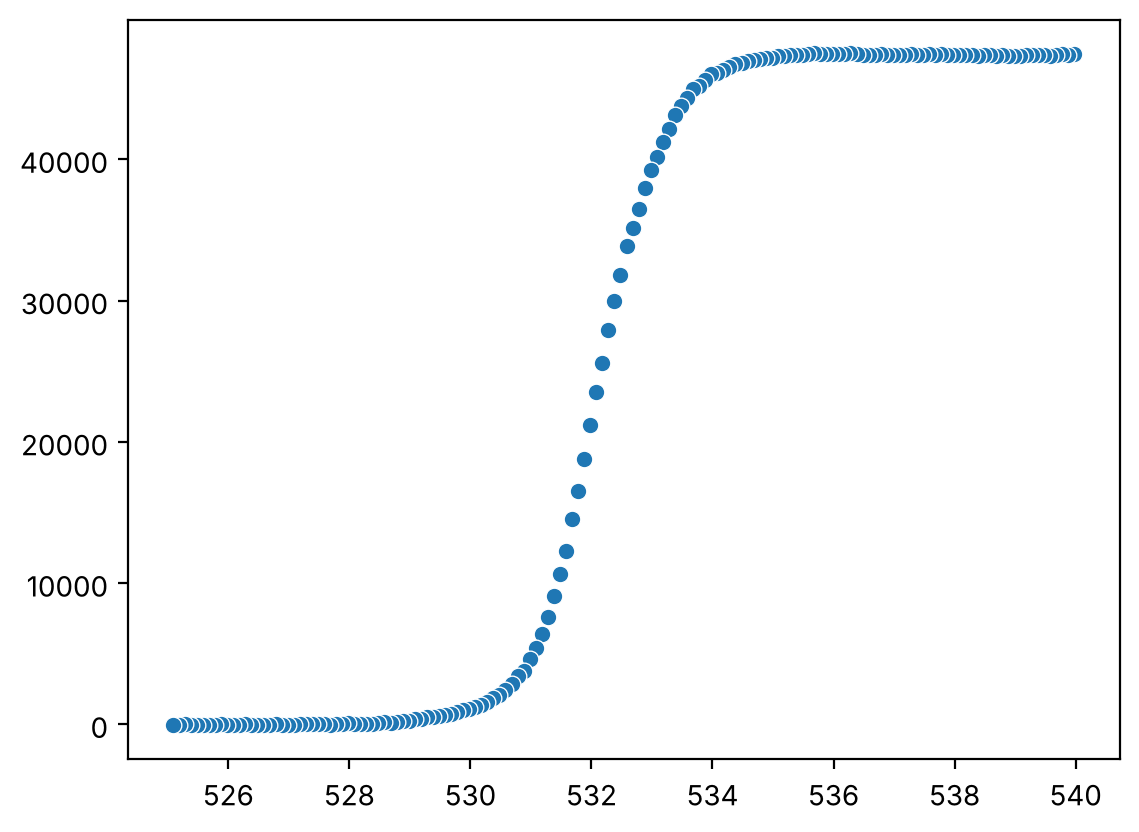

In [ ]:
eliminar = ["p2_", "sigmoid2_", "const_"]

y_mod = np.copy(dados_y)

for nome in eliminar:
   y_mod -= componentes[nome]

sns.scatterplot(x=dados_x, y=y_mod);

Vamos criar um modelo apenas com um pico Voigtiano, sua sigmoide e uma linha de base constante.

In [ ]:
modelo_pico1 = VoigtModel(prefix="p1_")

modelo_sigmoid1 = StepModel(
    prefix="sigmoid1_", form="logistic", independent_vars=["x"]
)

modelo_constante = ConstantModel(prefix="const_")

modelo_composto = (
    modelo_pico1
    + modelo_sigmoid1
    + modelo_constante
)

Precisamos dos parâmetros. Como na aula, usamos o `guess` para a Voigtiana e deixamos o `gamma` livre.

In [ ]:
params_pico1 = modelo_pico1.guess(y_mod, x=dados_x)
params_sigmoid1 = modelo_sigmoid1.make_params()
params_constante = modelo_constante.make_params()

params = (
    params_pico1
    + params_sigmoid1
    + params_constante
)

params["p1_gamma"].set(vary=True)

params["sigmoid1_center"].set(vary=False, expr="p1_center")
params["sigmoid1_sigma"].set(vary=False, expr="p1_sigma")

params["const_c"].set(value=min(y_mod))

params

name,value,initial value,min,max,vary,expression
p1_amplitude,834965.975,834965.9752436484,-inf,inf,True,
p1_center,536.080054,536.0800539999999,-inf,inf,True,
p1_sigma,2.53500000,2.5349999999999855,0.00000000,inf,True,
p1_gamma,2.53500000,None,-inf,inf,True,
p1_fwhm,9.12927177,None,-inf,inf,False,1.0692*p1_gamma+sqrt(0.8664*p1_gamma**2+5.545083*p1_sigma**2)
p1_height,68743.6481,None,-inf,inf,False,"(p1_amplitude/(max(1e-15, p1_sigma*sqrt(2*pi))))*real(wofz((1j*p1_gamma)/(max(1e-15, p1_sigma*sqrt(2)))))"
sigmoid1_amplitude,1.00000000,None,-inf,inf,True,
sigmoid1_center,536.080054,None,-inf,inf,False,p1_center
sigmoid1_sigma,2.53500000,None,-inf,inf,False,p1_sigma
const_c,-74.1529663,-74.1529662760122,-inf,inf,True,


Vejamos o resultado.

[[Model]]
    ((Model(voigt, prefix='p1_') + Model(step, prefix='sigmoid1_', form='logistic')) + Model(constant, prefix='const_'))
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 180
    # data points      = 150
    # variables        = 6
    chi-square         = 1554231.42
    reduced chi-square = 10793.2738
    Akaike info crit   = 1398.87846
    Bayesian info crit = 1416.94228
    R-squared          = 0.99997840
[[Variables]]
    p1_amplitude:        611.642037 +/- 115.434708 (18.87%) (init = 834966)
    p1_center:           532.145341 +/- 0.00384270 (0.00%) (init = 536.0801)
    p1_sigma:            0.53093545 +/- 0.00121805 (0.23%) (init = 2.535)
    p1_gamma:           -0.52494427 +/- 0.05850282 (11.14%) (init = 2.535)
    p1_fwhm:             0.78106630 +/- 0.04290483 (5.49%) == '1.0692*p1_gamma+sqrt(0.8664*p1_gamma**2+5.545083*p1_sigma**2)'
    p1_height:           1256.67847 +/- 79.7334057 (6.34%) == '(p1_amplitude/(max(1e-15, p1_sigma*sqrt(2*pi)))

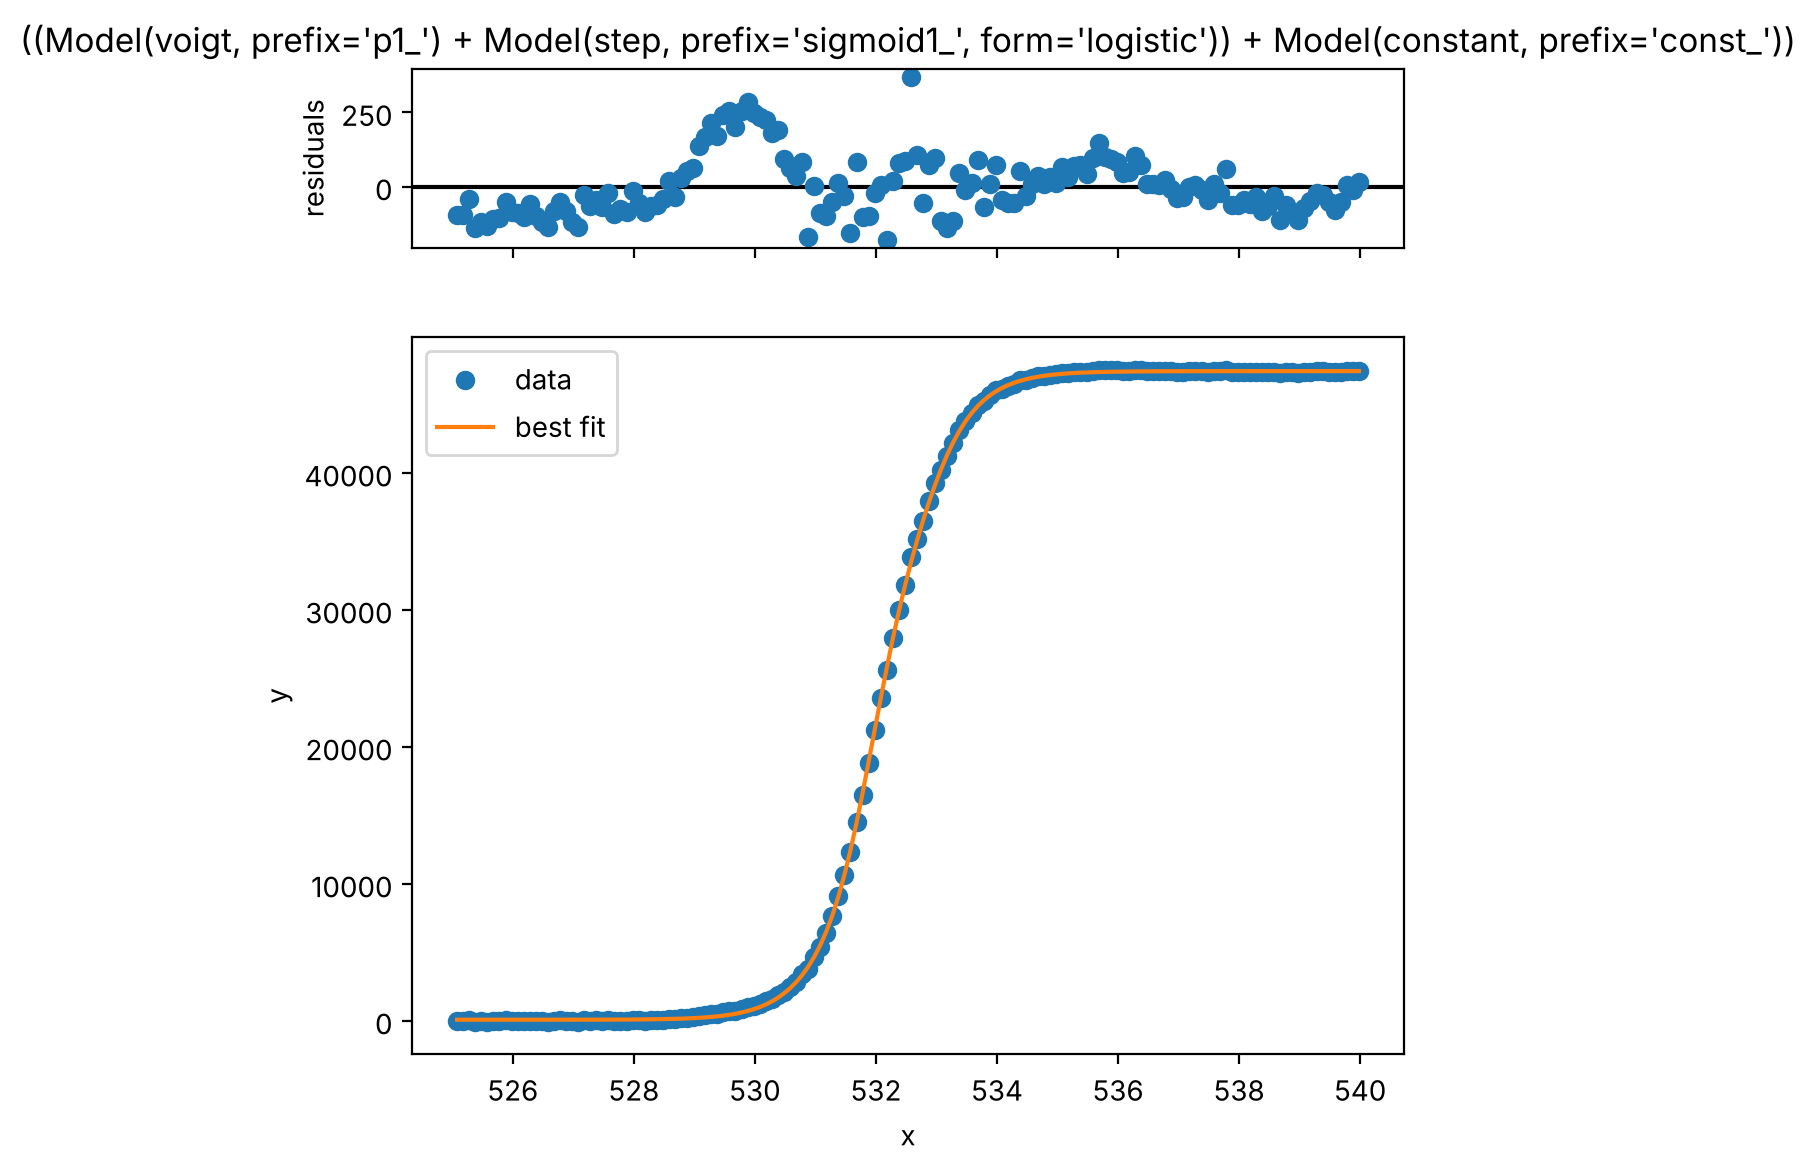

In [ ]:
resultado_fit = modelo_composto.fit(y_mod, params, x=dados_x)

print(resultado_fit.fit_report())

resultado_fit.plot();

Vejamos as componentes obtidas.

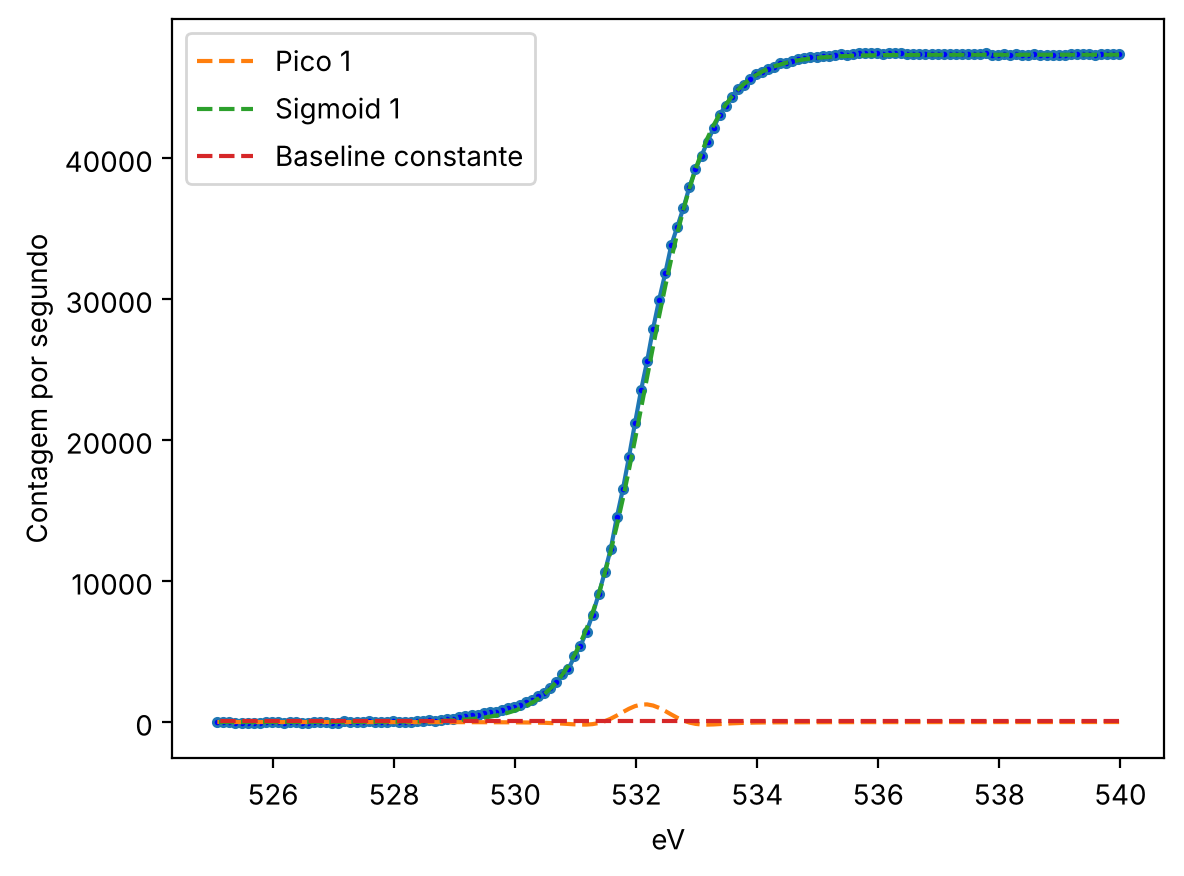

In [ ]:
componentes = resultado_fit.eval_components(x=dados_x)

fig, eixo = plt.subplots()
eixo.plot(dados_x, y_mod, marker="o", markerfacecolor="blue", markersize=3)
eixo.plot(dados_x, componentes["p1_"], "--", label="Pico 1")
eixo.plot(dados_x, componentes["sigmoid1_"], "--", label="Sigmoid 1")
eixo.plot(
    dados_x,
    np.ones(len(dados_x)) * componentes["const_"],
    "--",
    label="Baseline constante",
)
eixo.set(xlabel="eV", ylabel="Contagem por segundo")
eixo.legend();

> ⚠️ **O que aconteceu aqui com os meus dados** (teste feito com lmfit 1.3.4; em outra versão os números podem mudar um pouco)
>
> Como as componentes do ajuste anterior estavam erradas, o `y_mod` também ficou estranho. O `guess` começou com o centro em ~536 eV, longe do pico real. O ajuste terminou com `gamma` **negativo** (−0,52), o que não tem significado físico, porque o `gamma` é uma largura.

Vamos guardar o objeto de parâmetros que obtivemos.

In [ ]:
params_pico1 = resultado_fit.params.copy()

#### Investigando o pico 2 isoladamente

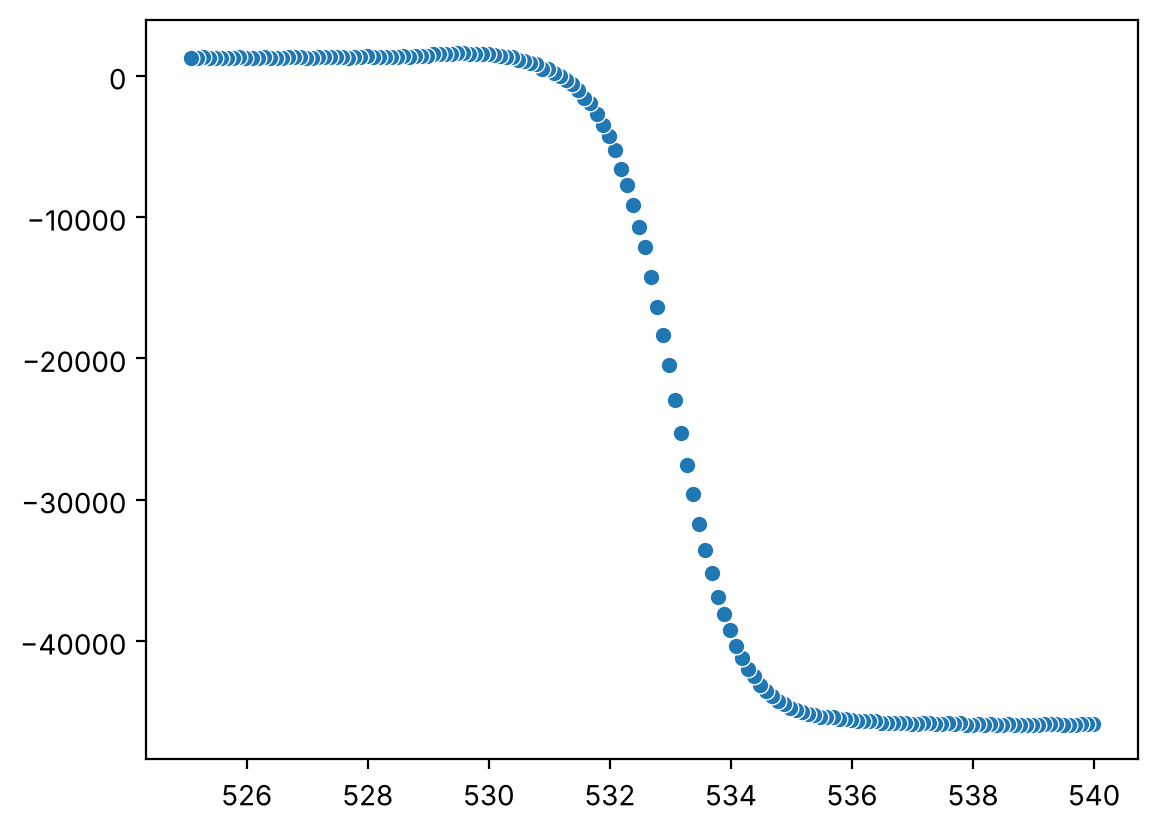

In [ ]:
eliminar = ["p1_", "sigmoid1_", "const_"]

y_mod = np.copy(dados_y)

for nome in eliminar:
   y_mod -= componentes[nome]

sns.scatterplot(x=dados_x, y=y_mod);

Vamos criar um modelo apenas com um pico Voigtiano, sua sigmoide e uma linha de base constante.

In [ ]:
modelo_pico2 = VoigtModel(prefix="p2_")

modelo_sigmoid2 = StepModel(
    prefix="sigmoid2_", form="logistic", independent_vars=["x"]
)

modelo_constante = ConstantModel(prefix="const_")

modelo_composto = (
    modelo_pico2
    + modelo_sigmoid2
    + modelo_constante
)

Precisamos dos parâmetros. Como na aula, usamos o `guess` para a Voigtiana e deixamos o `gamma` livre.

In [ ]:
params_pico2 = modelo_pico2.guess(y_mod, x=dados_x)
params_sigmoid2 = modelo_sigmoid2.make_params()
params_constante = modelo_constante.make_params()

params = (
    params_pico2
    + params_sigmoid2
    + params_constante
)

params["p2_gamma"].set(vary=True)

params["sigmoid2_center"].set(vary=False, expr="p2_center")
params["sigmoid2_sigma"].set(vary=False, expr="p2_sigma")

params["const_c"].set(value=min(y_mod))

params

name,value,initial value,min,max,vary,expression
p2_amplitude,845244.744,845244.7444532684,-inf,inf,True,
p2_center,529.030054,529.0300539999998,-inf,inf,True,
p2_sigma,2.56750000,2.567499999999993,0.00000000,inf,True,
p2_gamma,2.56750000,None,-inf,inf,True,
p2_fwhm,9.24631371,None,-inf,inf,False,1.0692*p2_gamma+sqrt(0.8664*p2_gamma**2+5.545083*p2_sigma**2)
p2_height,68709.0253,None,-inf,inf,False,"(p2_amplitude/(max(1e-15, p2_sigma*sqrt(2*pi))))*real(wofz((1j*p2_gamma)/(max(1e-15, p2_sigma*sqrt(2)))))"
sigmoid2_amplitude,1.00000000,None,-inf,inf,True,
sigmoid2_center,529.030054,None,-inf,inf,False,p2_center
sigmoid2_sigma,2.56750000,None,-inf,inf,False,p2_sigma
const_c,-45963.3506,-45963.35058654349,-inf,inf,True,


Vejamos o resultado.

[[Model]]
    ((Model(voigt, prefix='p2_') + Model(step, prefix='sigmoid2_', form='logistic')) + Model(constant, prefix='const_'))
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 180
    # data points      = 150
    # variables        = 6
    chi-square         = 2365469.76
    reduced chi-square = 16426.8733
    Akaike info crit   = 1461.87778
    Bayesian info crit = 1479.94160
    R-squared          = 0.99996697
[[Variables]]
    p2_amplitude:       -699.648130 +/- 6727.36940 (961.54%) (init = 845244.7)
    p2_center:           533.050177 +/- 0.13899711 (0.03%) (init = 529.0301)
    p2_sigma:            0.52266345 +/- 0.00153572 (0.29%) (init = 2.5675)
    p2_gamma:            0.94639635 +/- 8.65083281 (914.08%) (init = 2.5675)
    p2_fwhm:             2.52542412 +/- 13.9353169 (551.80%) == '1.0692*p2_gamma+sqrt(0.8664*p2_gamma**2+5.545083*p2_sigma**2)'
    p2_height:          -193.094288 +/- 3118.71036 (1615.12%) == '(p2_amplitude/(max(1e-15, p2_sigma*s

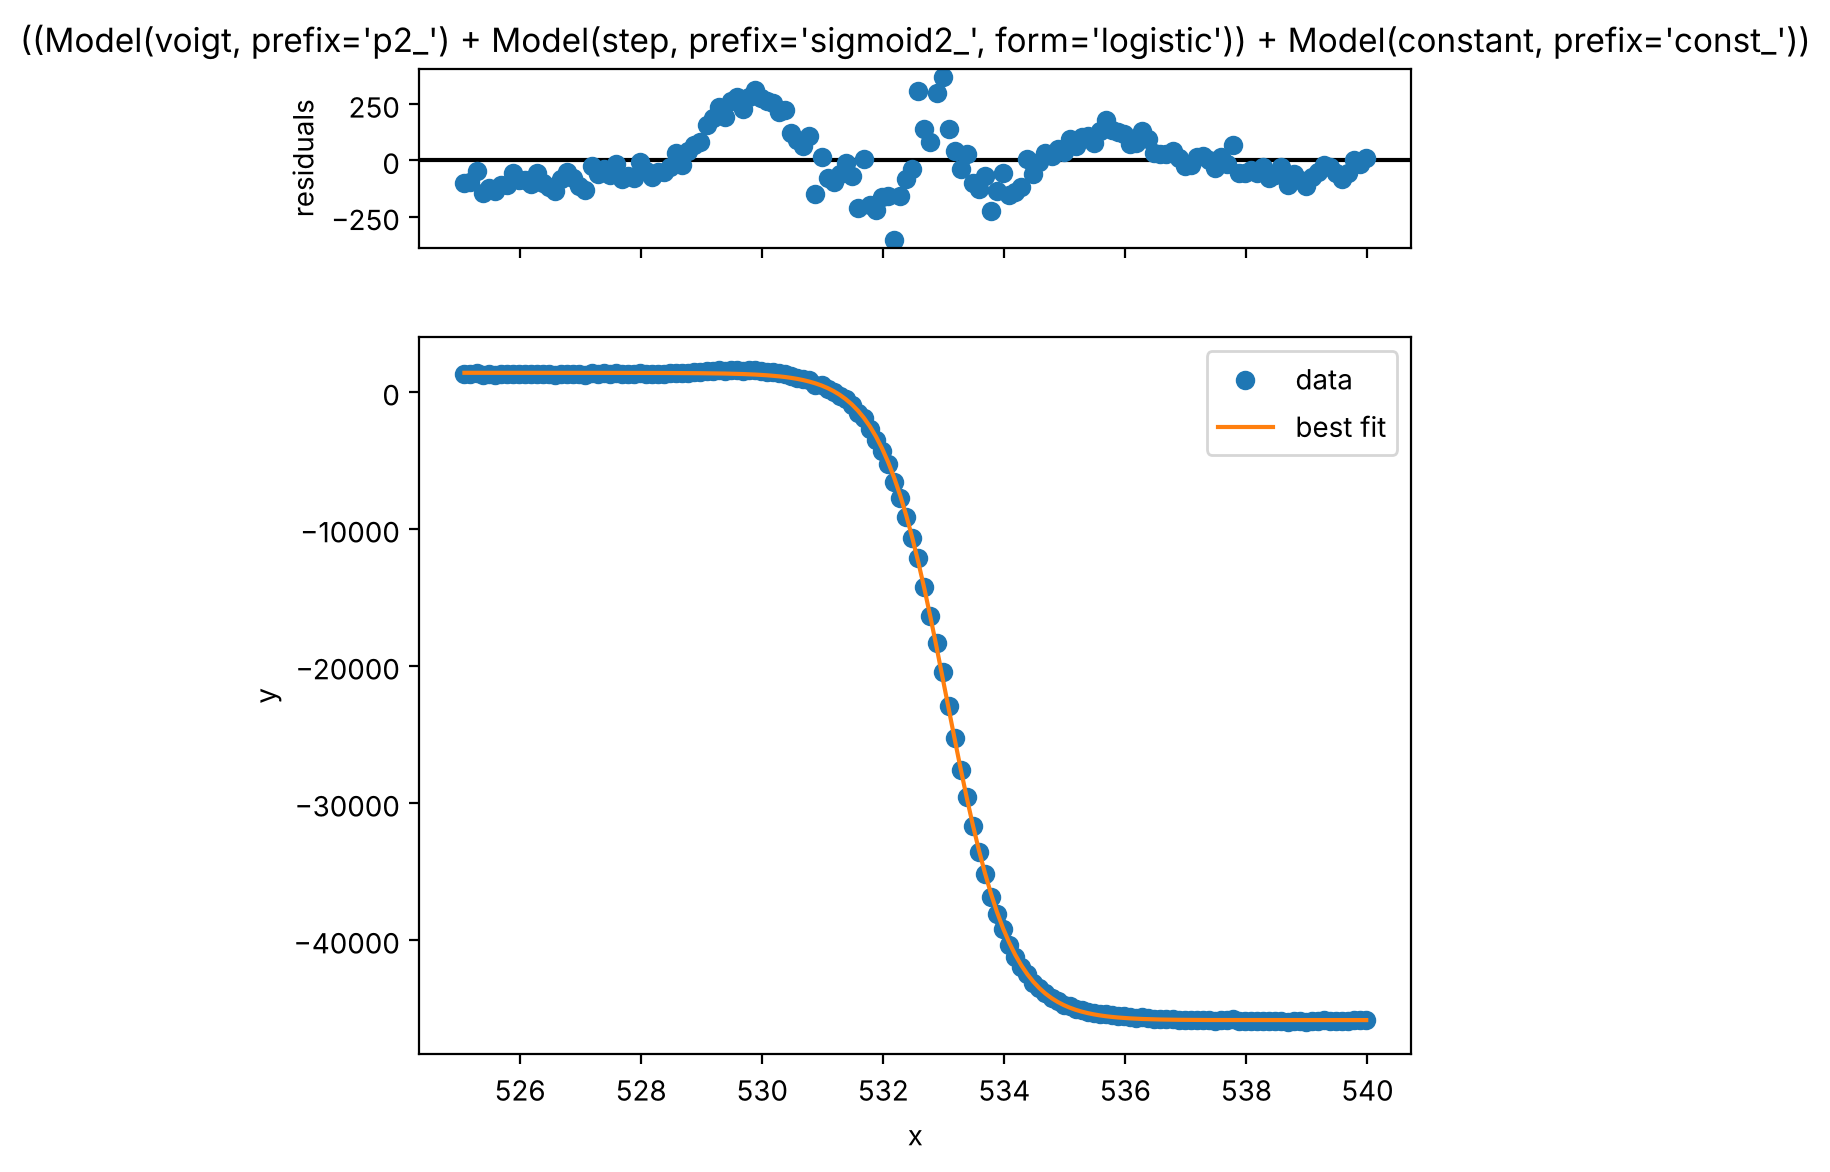

In [ ]:
resultado_fit = modelo_composto.fit(y_mod, params, x=dados_x)

print(resultado_fit.fit_report())

resultado_fit.plot();

Vejamos as componentes obtidas.

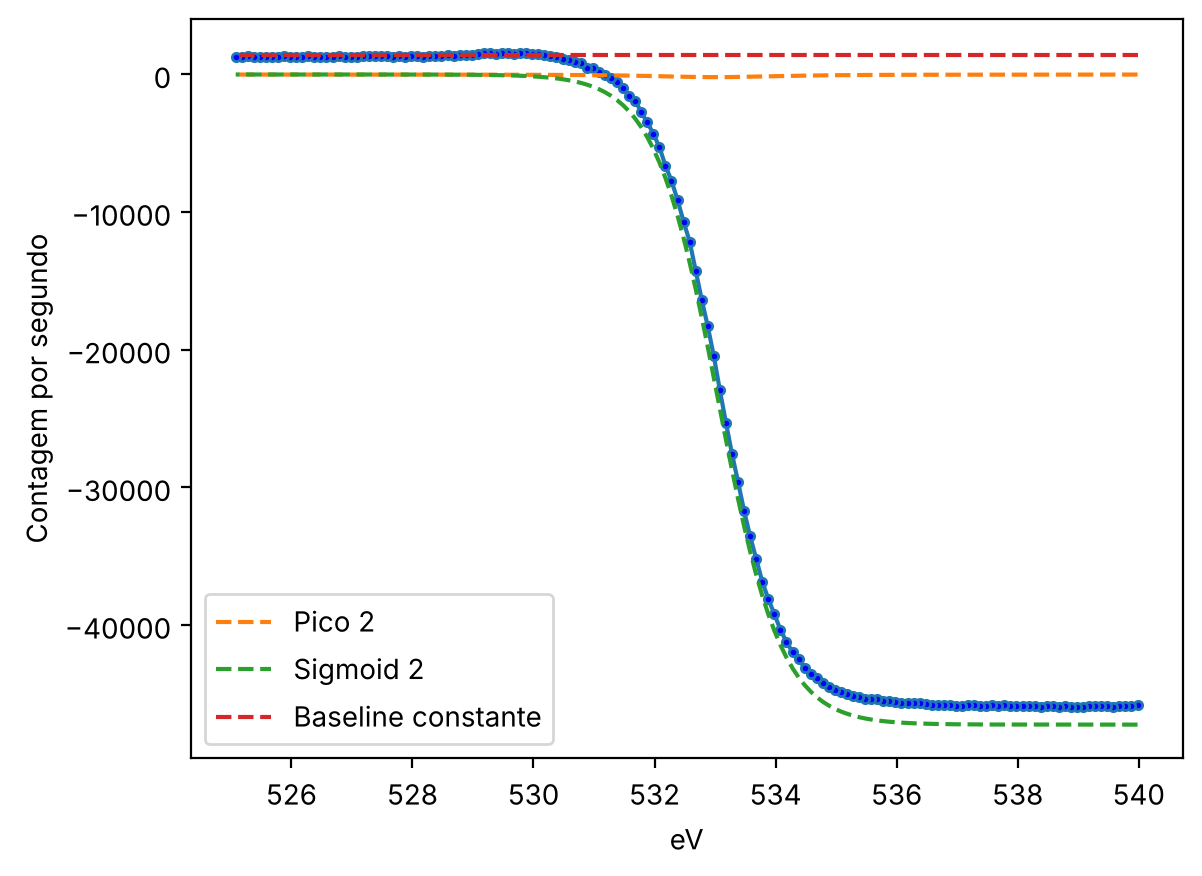

In [ ]:
componentes = resultado_fit.eval_components(x=dados_x)

fig, eixo = plt.subplots()
eixo.plot(dados_x, y_mod, marker="o", markerfacecolor="blue", markersize=3)
eixo.plot(dados_x, componentes["p2_"], "--", label="Pico 2")
eixo.plot(dados_x, componentes["sigmoid2_"], "--", label="Sigmoid 2")
eixo.plot(
    dados_x,
    np.ones(len(dados_x)) * componentes["const_"],
    "--",
    label="Baseline constante",
)
eixo.set(xlabel="eV", ylabel="Contagem por segundo")
eixo.legend();

> ⚠️ **O que aconteceu aqui com os meus dados** (teste feito com lmfit 1.3.4; em outra versão os números podem mudar um pouco)
>
> A área do pico 2 saiu **negativa** (≈ −700), ou seja, um "pico para baixo", com incerteza perto de 1000%.

Vamos guardar o objeto de parâmetros que obtivemos.

In [ ]:
params_pico2 = resultado_fit.params.copy()

#### Juntando os resultados

Vamos retornar aos dados originais e ao modelo original com 2 picos, agora Voigtianos.

In [ ]:
modelo_pico1 = VoigtModel(prefix="p1_")
modelo_pico2 = VoigtModel(prefix="p2_")

modelo_sigmoid1 = StepModel(
    prefix="sigmoid1_", form="logistic", independent_vars=["x"]
)
modelo_sigmoid2 = StepModel(
    prefix="sigmoid2_", form="logistic", independent_vars=["x"]
)

modelo_constante = ConstantModel(prefix="const_")

modelo_composto = (
    modelo_pico1
    + modelo_sigmoid1
    + modelo_pico2
    + modelo_sigmoid2
    + modelo_constante
)

Os parâmetros que usaremos serão os obtidos dos ajustes isolados.

In [ ]:
params = params_pico1

params.update(params_pico2)

params

name,value,standard error,relative error,initial value,min,max,vary,expression
p1_amplitude,611.642037,115.434708,(18.87%),834965.9752436484,-inf,inf,True,
p1_center,532.145341,0.00384270,(0.00%),536.0800539999999,-inf,inf,True,
p1_sigma,0.53093545,0.00121805,(0.23%),2.5349999999999855,0.00000000,inf,True,
p1_gamma,-0.52494427,0.05850282,(11.14%),2.5349999999999855,-inf,inf,True,
p1_fwhm,0.78106630,0.04290483,(5.49%),9.129271767806872,-inf,inf,False,1.0692*p1_gamma+sqrt(0.8664*p1_gamma**2+5.545083*p1_sigma**2)
p1_height,1256.67847,79.7334057,(6.34%),68743.64810733334,-inf,inf,False,"(p1_amplitude/(max(1e-15, p1_sigma*sqrt(2*pi))))*real(wofz((1j*p1_gamma)/(max(1e-15, p1_sigma*sqrt(2)))))"
sigmoid1_amplitude,47356.0445,20.4035065,(0.04%),1.0,-inf,inf,True,
sigmoid1_center,532.145341,0.00384270,(0.00%),536.0800539999999,-inf,inf,False,p1_center
sigmoid1_sigma,0.53093545,0.00121805,(0.23%),2.5349999999999855,-inf,inf,False,p1_sigma
const_c,1387.84734,21.8105871,(1.57%),-45963.35058654349,-inf,inf,True,


Vamos ajustar o modelo.

In [ ]:
resultado_fit = modelo_composto.fit(dados_y, params, x=dados_x)

print(resultado_fit.fit_report())

resultado_fit.plot();

ValueError: The model function generated NaN values and the fit aborted! Please check your model function and/or set boundaries on parameters where applicable. In cases like this, using "nan_policy='omit'" will probably not work.

> ⚠️ **O que aconteceu aqui com os meus dados** (teste feito com lmfit 1.3.4; em outra versão os números podem mudar um pouco)
>
> Esta célula dá **erro**: `ValueError: The model function generated NaN values`. Com os palpites ruins que vieram dos passos anteriores (gamma negativo, área negativa), a função Voigt gera valores inválidos e o ajuste para.
>
> **As duas células seguintes não valem.** A análise de resíduos usa o `resultado_fit` antigo (o do pico 2 isolado), e a célula das componentes dá `KeyError: 'p1_'` pelo mesmo motivo.

Vamos observar a análise dos resíduos.

p-valor de Shapiro-Wilk dos resíduos: 1.74e-15


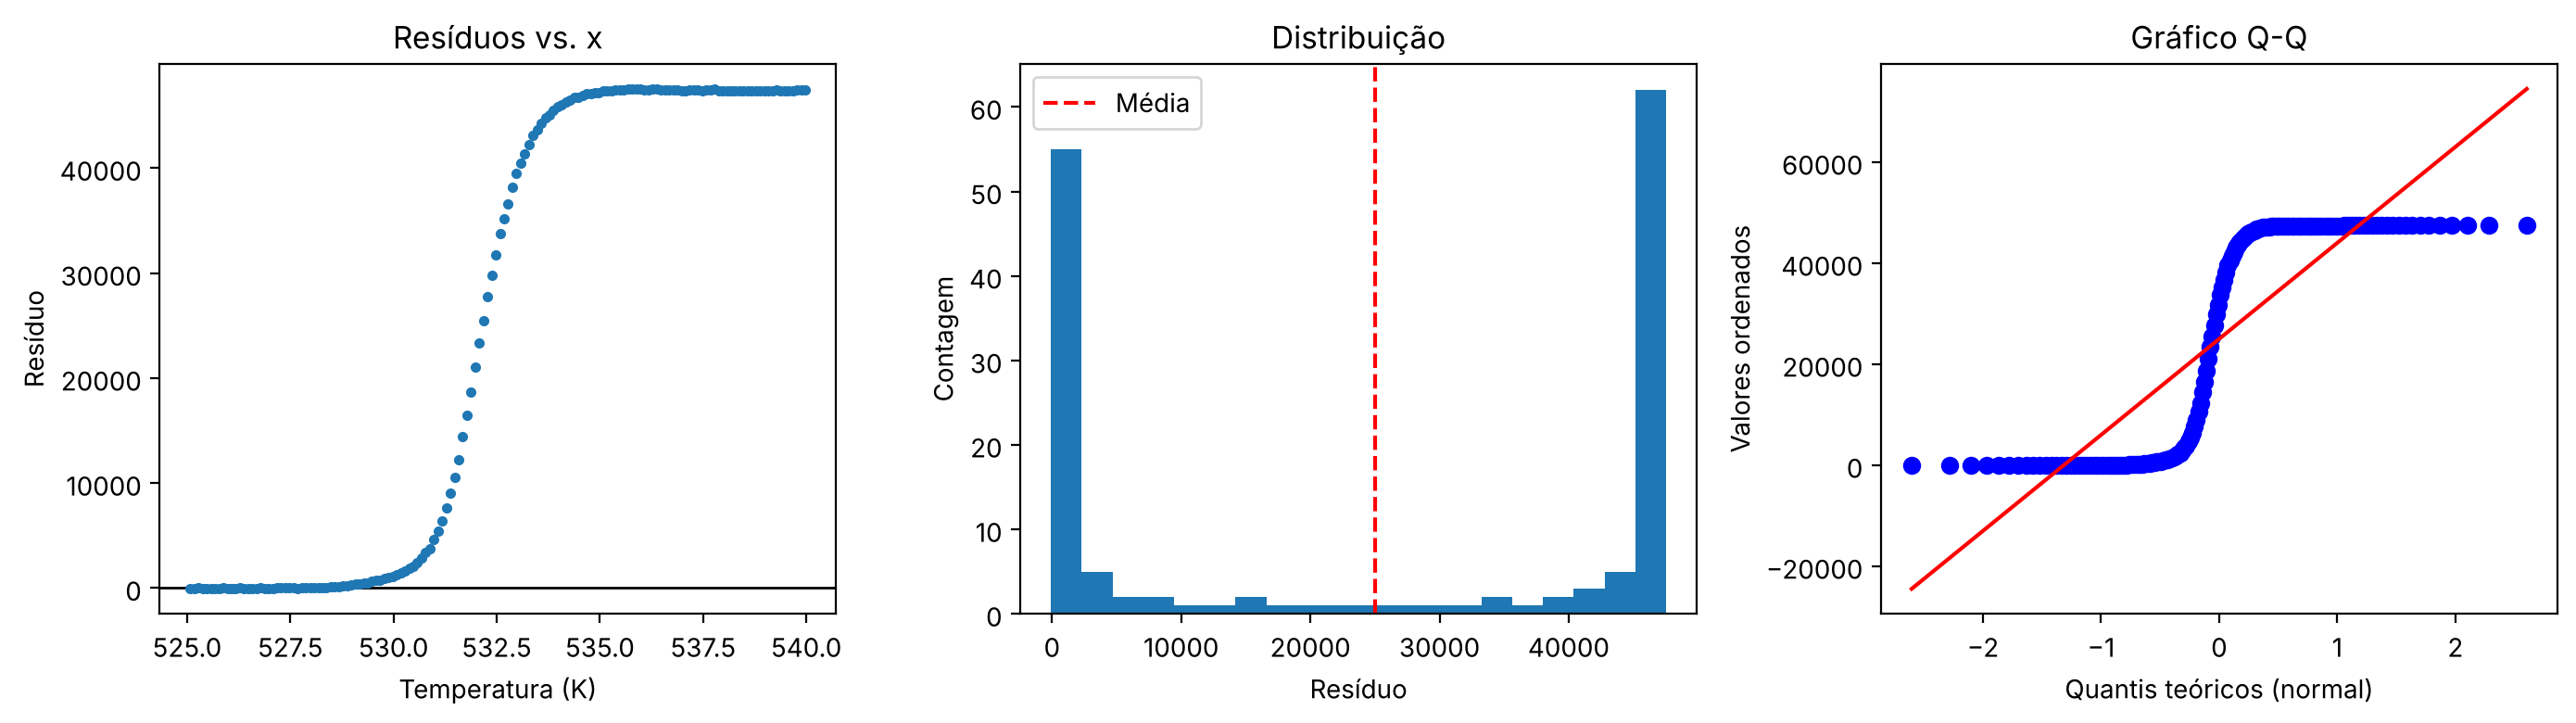

In [ ]:
analise_residuos(dados_x, dados_y, resultado_fit.best_fit)

Para encerrar, faremos a análise das componentes.

KeyError: 'p1_'

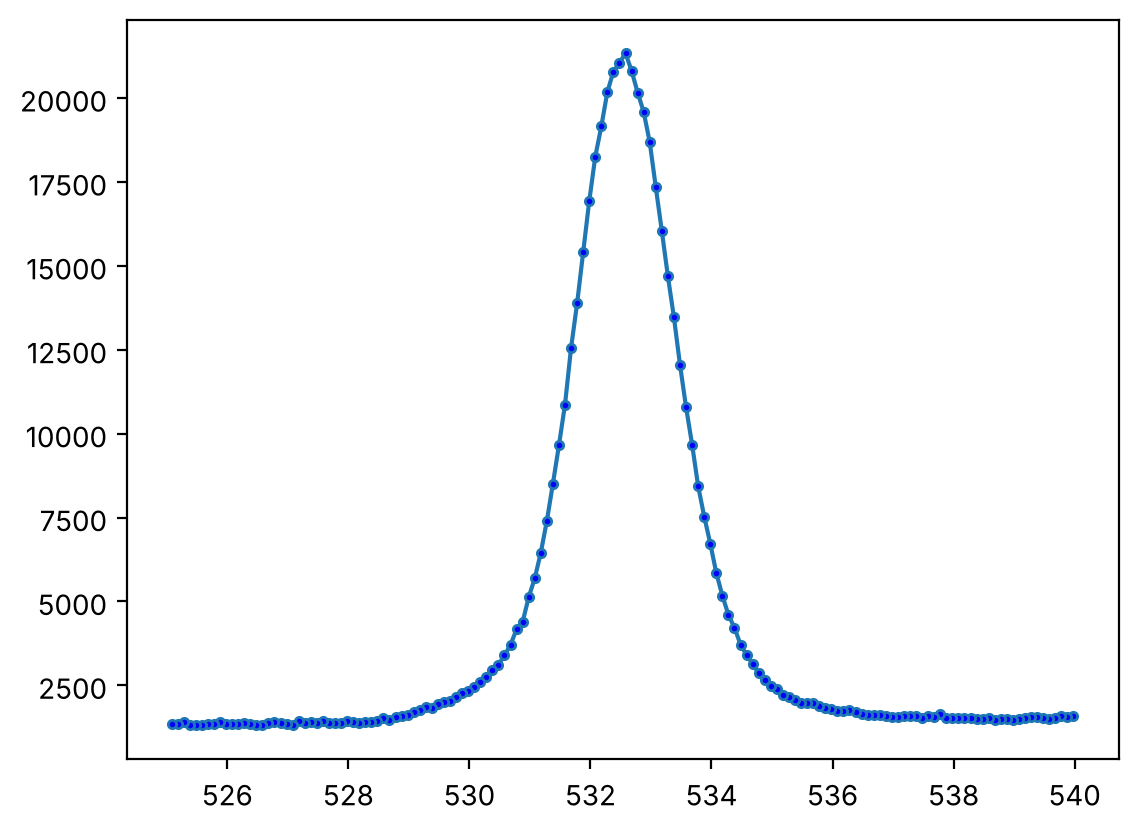

In [ ]:
componentes = resultado_fit.eval_components(x=dados_x)

fig, eixo = plt.subplots()
eixo.plot(dados_x, dados_y, marker="o", markerfacecolor="blue", markersize=3)
eixo.plot(dados_x, componentes["p1_"], "--", label="Pico 1")
eixo.plot(dados_x, componentes["p2_"], "--", label="Pico 2")
eixo.plot(dados_x, componentes["sigmoid1_"], "--", label="Sigmoid 1")
eixo.plot(dados_x, componentes["sigmoid2_"], "--", label="Sigmoid 2")
eixo.plot(
    dados_x,
    np.ones(len(dados_x)) * componentes["const_"],
    "--",
    label="Baseline constante",
)
eixo.set(xlabel="eV", ylabel="Contagem por segundo")
eixo.legend();

## C 1s – deconvolução de picos

Esta seção mostra uma forma de tratar os dados de XPS da região C 1s usando o `lmfit`, seguindo a aula.

### Carregando os dados

Os dados de XPS estão no arquivo `C1s_Scan.avg`. A função `le_arquivo_avg` (definida no início) faz o papel do `pd.read_excel` da aula.

In [ ]:
ARQUIVO_XPS = "C1s_Scan.avg"

df = le_arquivo_avg(ARQUIVO_XPS)

df = df.dropna()

Vamos ver os dados que temos.

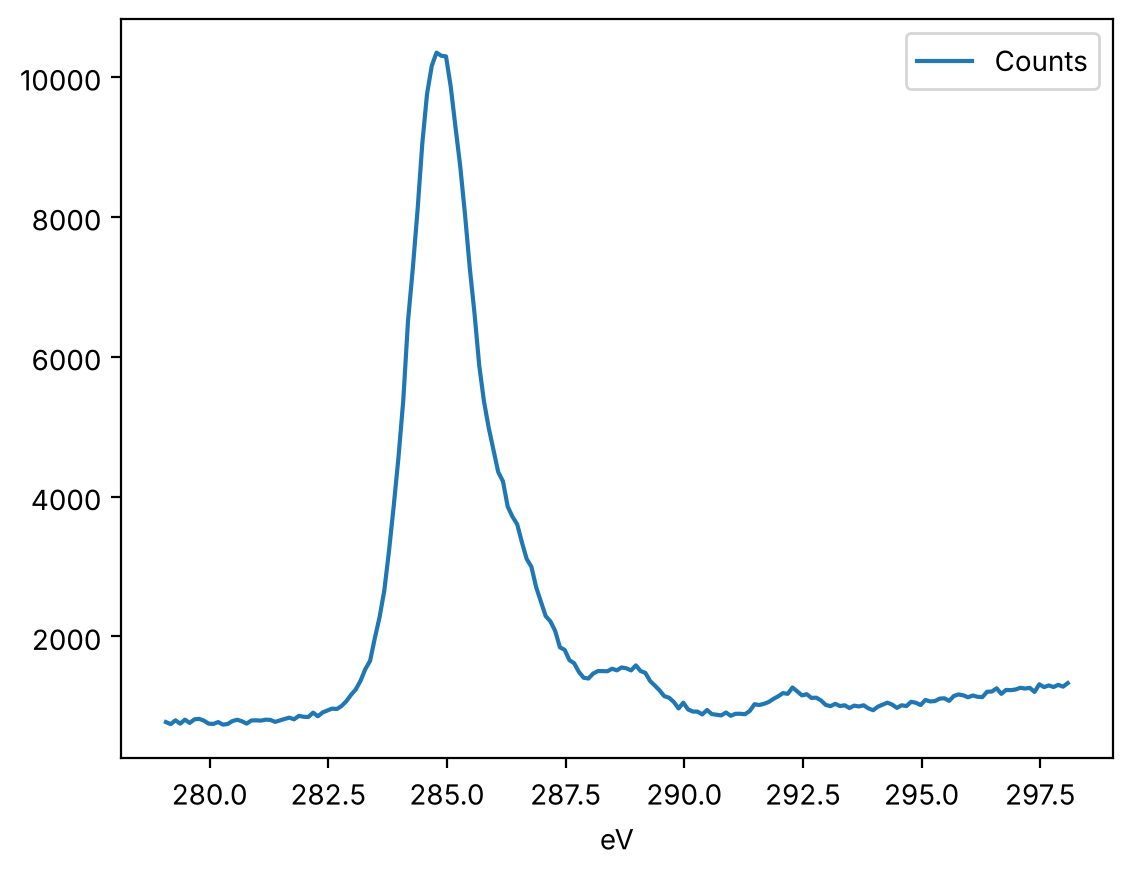

In [ ]:
df.plot("eV", "Counts");

Para este estudo em particular, não queremos dados com Binding Energy acima de 296 eV. Acima disso só há fundo subindo, sem picos.

In [ ]:
logic = df["eV"] <= 296
df = df.loc[logic]

Vamos checar os dados novamente.

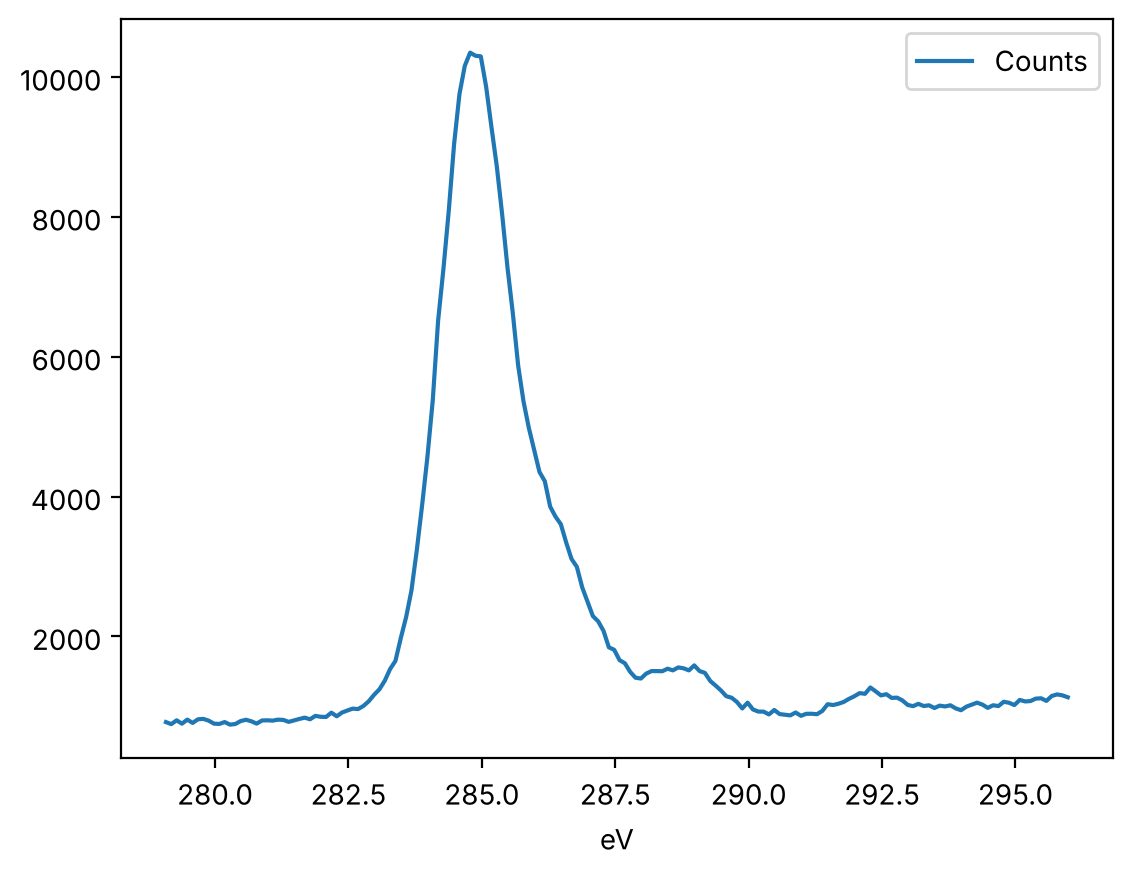

In [ ]:
df.plot("eV", "Counts");

Deste gráfico observamos um pico principal perto de 284,8 eV, um ombro perto de 286,3 eV, um pico pequeno perto de 288,8 eV e outro ainda menor perto de 292,3 eV. Também há uma linha de base, já que o sinal não chega a zero.

### Comentário sobre picos com base direita e esquerda com diferentes valores

Igual à aula: muitas vezes, picos obtidos por espectroscopia têm valores diferentes para as bases que estão à direita e à esquerda do pico. Apenas uma função de pico junto com uma linha de base constante *não* são capazes de descrever essa situação. A estratégia é adicionar uma curva sigmoidal.

### Definição do modelo

Assim como na aula, vamos modelar os picos como Lorentzianas.

In [ ]:
modelo_pico1 = LorentzianModel(prefix="p1_")
modelo_pico2 = LorentzianModel(prefix="p2_")
modelo_pico3 = LorentzianModel(prefix="p3_")
modelo_pico4 = LorentzianModel(prefix="p4_")

Vamos agora associar uma **linha de base sigmoidal** para cada pico, usando a função degrau (`StepModel`) com `form="logistic"` e `independent_vars=["x"]`, exatamente como na aula. Como temos 4 picos, criamos 4 sigmoides.

In [ ]:
modelo_sigmoid1 = StepModel(
    prefix="sigmoid1_", form="logistic", independent_vars=["x"]
)
modelo_sigmoid2 = StepModel(
    prefix="sigmoid2_", form="logistic", independent_vars=["x"]
)
modelo_sigmoid3 = StepModel(
    prefix="sigmoid3_", form="logistic", independent_vars=["x"]
)
modelo_sigmoid4 = StepModel(
    prefix="sigmoid4_", form="logistic", independent_vars=["x"]
)

A linha de base será um modelo constante.

In [ ]:
modelo_constante = ConstantModel(prefix="const_")

Finalmente, construímos o modelo composto pela combinação linear dos modelos individuais.

In [ ]:
modelo_composto = (
    modelo_pico1
    + modelo_sigmoid1
    + modelo_pico2
    + modelo_sigmoid2
    + modelo_pico3
    + modelo_sigmoid3
    + modelo_pico4
    + modelo_sigmoid4
    + modelo_constante
)

### Palpite inicial dos parâmetros

Vamos criar os parâmetros do modelo composto.

In [ ]:
params_pico1 = modelo_pico1.make_params()
params_pico2 = modelo_pico2.make_params()
params_pico3 = modelo_pico3.make_params()
params_pico4 = modelo_pico4.make_params()
params_sigmoid1 = modelo_sigmoid1.make_params()
params_sigmoid2 = modelo_sigmoid2.make_params()
params_sigmoid3 = modelo_sigmoid3.make_params()
params_sigmoid4 = modelo_sigmoid4.make_params()
params_constante = modelo_constante.make_params()

params = (
    params_pico1
    + params_sigmoid1
    + params_pico2
    + params_sigmoid2
    + params_pico3
    + params_sigmoid3
    + params_pico4
    + params_sigmoid4
    + params_constante
)

params

name,value,initial value,min,max,vary,expression
p1_amplitude,1.00000000,None,-inf,inf,True,
p1_center,0.00000000,None,-inf,inf,True,
p1_sigma,1.00000000,None,0.00000000,inf,True,
p1_fwhm,2.00000000,None,-inf,inf,False,2.0000000*p1_sigma
p1_height,0.31830990,None,-inf,inf,False,"0.3183099*p1_amplitude/max(1e-15, p1_sigma)"
sigmoid1_amplitude,1.00000000,None,-inf,inf,True,
sigmoid1_center,0.00000000,None,-inf,inf,True,
sigmoid1_sigma,1.00000000,None,-inf,inf,True,
p2_amplitude,1.00000000,None,-inf,inf,True,
p2_center,0.00000000,None,-inf,inf,True,


Agora iremos restringir os parâmetros. Assim como na aula, os valores abaixo foram obtidos olhando para os gráficos dos dados.

Pico principal (`p1`), perto de 284,8 eV (C–C/C–H). A altura parece estar perto de 10.000; usaremos 9.000 porque os dados não começam do 0.

In [ ]:
params["p1_center"].set(value=284.8, min=284.2, max=285.3)
params["p1_sigma"].set(value=0.6)

params["p1_height"].set(vary=True, value=9000, min=0, expr="")
params["p1_amplitude"].set(vary=False, expr="pi * p1_sigma * p1_height")

Ombro (`p2`), perto de 286,3 eV (C–O). Altura perto de 2.000.

In [ ]:
params["p2_center"].set(value=286.3, min=285.7, max=287.0)
params["p2_sigma"].set(value=0.8)

params["p2_height"].set(vary=True, value=2000, min=0, expr="")
params["p2_amplitude"].set(vary=False, expr="pi * p2_sigma * p2_height")

Pico pequeno (`p3`), perto de 288,8 eV (O–C=O). Altura perto de 600.

In [ ]:
params["p3_center"].set(value=288.8, min=288.0, max=289.5)
params["p3_sigma"].set(value=0.7)

params["p3_height"].set(vary=True, value=600, min=0, expr="")
params["p3_amplitude"].set(vary=False, expr="pi * p3_sigma * p3_height")

Pico menor (`p4`), perto de 292,3 eV (CF₂). Altura perto de 250.

In [ ]:
params["p4_center"].set(value=292.3, min=291.5, max=293.0)
params["p4_sigma"].set(value=0.5)

params["p4_height"].set(vary=True, value=250, min=0, expr="")
params["p4_amplitude"].set(vary=False, expr="pi * p4_sigma * p4_height")

Como na aula, vamos fixar o centro e o desvio padrão de cada sigmoide como iguais ao centro e ao desvio padrão do seu pico.

In [ ]:
params["sigmoid1_center"].set(vary=False, expr="p1_center")
params["sigmoid1_sigma"].set(vary=False, expr="p1_sigma")

params["sigmoid2_center"].set(vary=False, expr="p2_center")
params["sigmoid2_sigma"].set(vary=False, expr="p2_sigma")

params["sigmoid3_center"].set(vary=False, expr="p3_center")
params["sigmoid3_sigma"].set(vary=False, expr="p3_sigma")

params["sigmoid4_center"].set(vary=False, expr="p4_center")
params["sigmoid4_sigma"].set(vary=False, expr="p4_sigma")

Por fim, olhando para o gráfico podemos dar um palpite para a constante da linha de base.

In [ ]:
params["const_c"].set(value=800)

### Ajuste do modelo

O ajuste e a análise dos resultados seguem da mesma maneira.

In [ ]:
dados_x = df["eV"].values
dados_y = df["Counts"].values

resultado_fit = modelo_composto.fit(dados_y, params, x=dados_x)

print(resultado_fit.fit_report())

[[Model]]
    ((((((((Model(lorentzian, prefix='p1_') + Model(step, prefix='sigmoid1_', form='logistic')) + Model(lorentzian, prefix='p2_')) + Model(step, prefix='sigmoid2_', form='logistic')) + Model(lorentzian, prefix='p3_')) + Model(step, prefix='sigmoid3_', form='logistic')) + Model(lorentzian, prefix='p4_')) + Model(step, prefix='sigmoid4_', form='logistic')) + Model(constant, prefix='const_'))
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 36000
    # data points      = 170
    # variables        = 17
    chi-square         = 5891732.55
    reduced chi-square = 38508.0559
    Akaike info crit   = 1811.05458
    Bayesian info crit = 1864.36315
    R-squared          = 0.99363325
##  Warning: uncertainties could not be estimated:
[[Variables]]
    p1_amplitude:        16361.8917 == 'pi * p1_sigma * p1_height'
    p1_center:           284.789186 (init = 284.8)
    p1_sigma:            0.61882706 (init = 0.6)
    p1_fwhm:             1.23765412 == '2.000

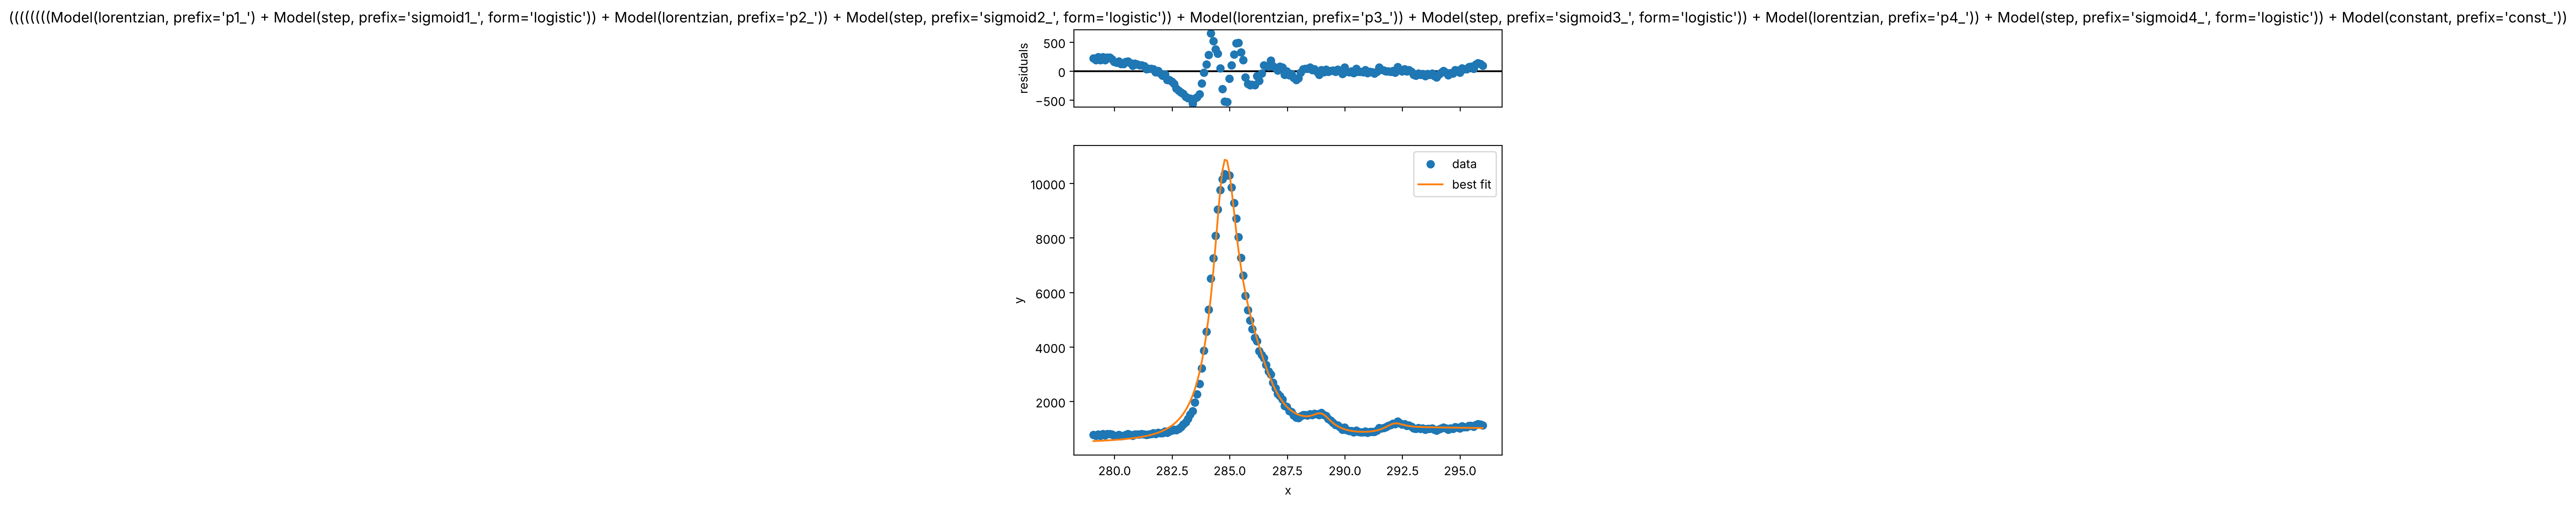

In [ ]:
resultado_fit.plot();

Vamos observar a análise dos resíduos.

p-valor de Shapiro-Wilk dos resíduos: 1.06e-07


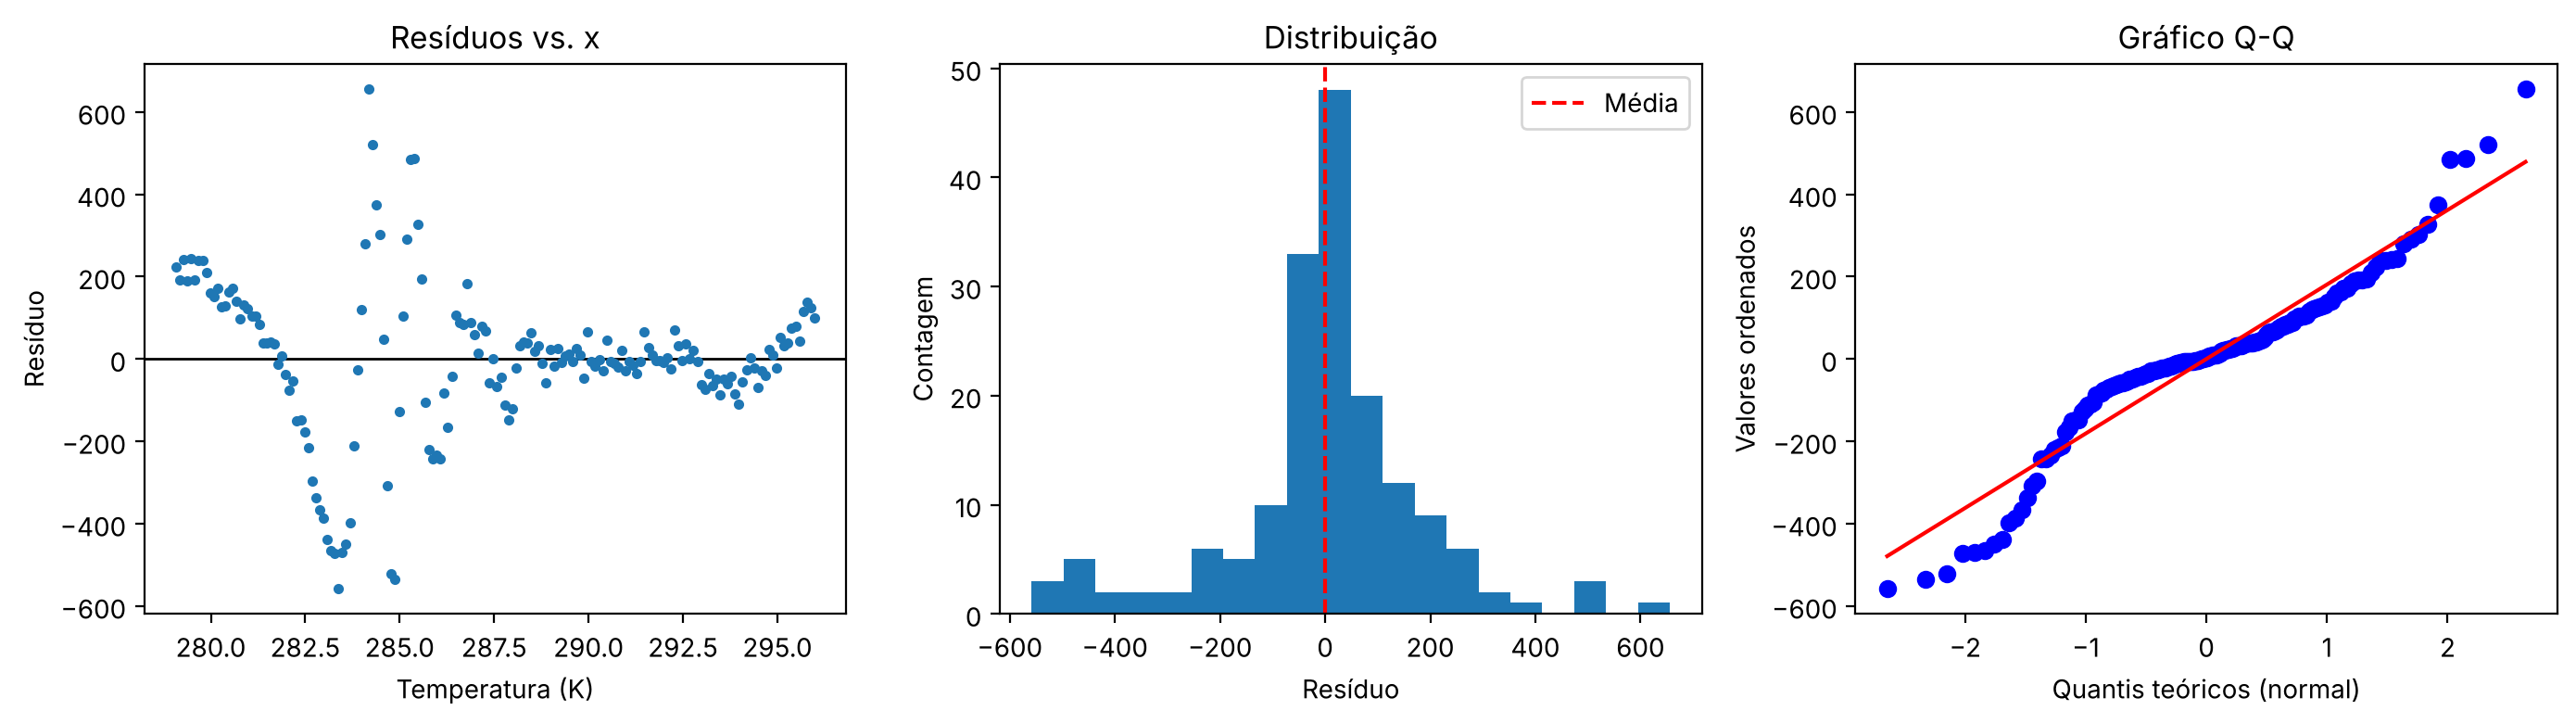

In [ ]:
analise_residuos(dados_x, dados_y, resultado_fit.best_fit)

### A contribuição de cada componente

Novamente, podemos investigar a contribuição de cada componente.

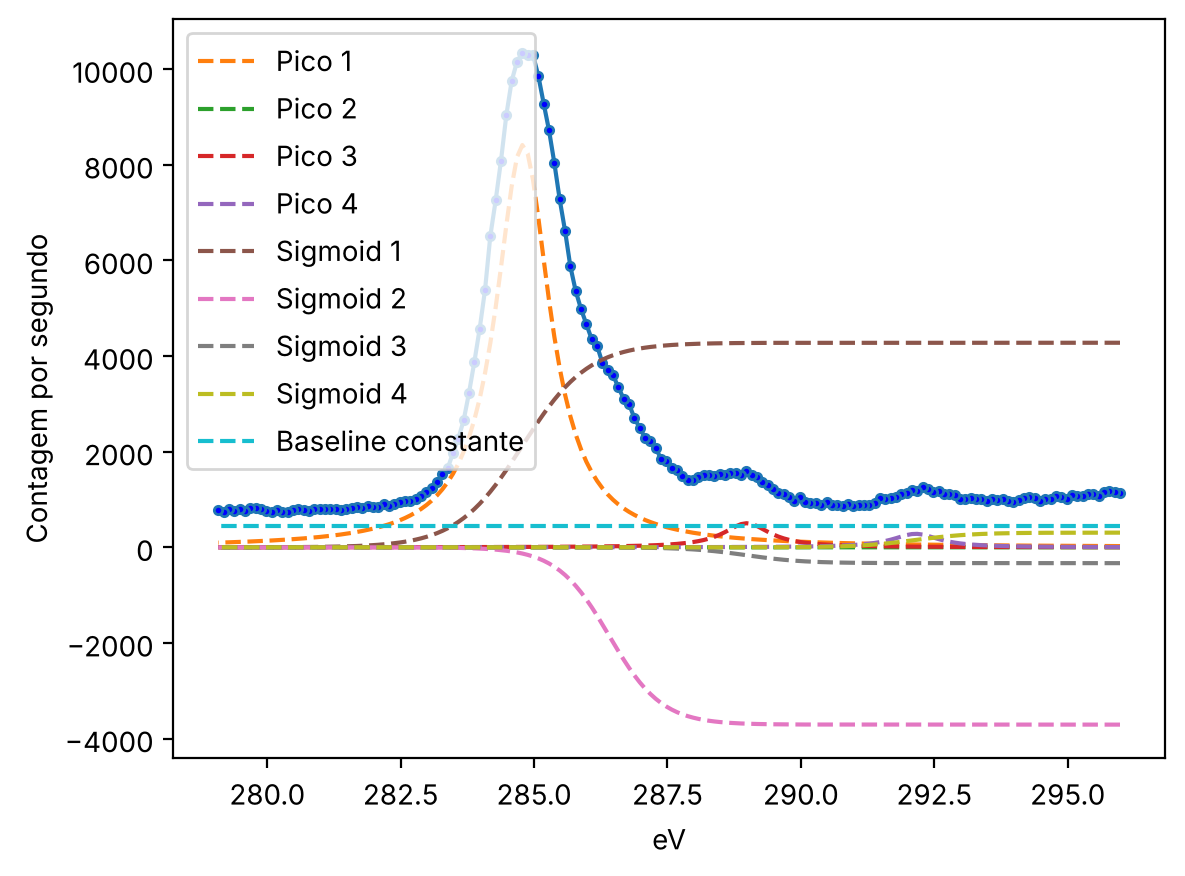

In [ ]:
componentes = resultado_fit.eval_components(x=dados_x)

fig, eixo = plt.subplots()
eixo.plot(dados_x, dados_y, marker="o", markerfacecolor="blue", markersize=3)
eixo.plot(dados_x, componentes["p1_"], "--", label="Pico 1")
eixo.plot(dados_x, componentes["p2_"], "--", label="Pico 2")
eixo.plot(dados_x, componentes["p3_"], "--", label="Pico 3")
eixo.plot(dados_x, componentes["p4_"], "--", label="Pico 4")
eixo.plot(dados_x, componentes["sigmoid1_"], "--", label="Sigmoid 1")
eixo.plot(dados_x, componentes["sigmoid2_"], "--", label="Sigmoid 2")
eixo.plot(dados_x, componentes["sigmoid3_"], "--", label="Sigmoid 3")
eixo.plot(dados_x, componentes["sigmoid4_"], "--", label="Sigmoid 4")
eixo.plot(
    dados_x,
    np.ones(len(dados_x)) * componentes["const_"],
    "--",
    label="Baseline constante",
)
eixo.set(xlabel="eV", ylabel="Contagem por segundo")
eixo.legend();

> ⚠️ **O que aconteceu aqui com os meus dados** (teste feito com lmfit 1.3.4; em outra versão os números podem mudar um pouco)
>
> O ajuste **não convergiu**: chegou ao limite de tentativas (36.000) e o relatório avisa que as incertezas não puderam ser calculadas. O pico 2 (C–O) praticamente sumiu (altura ≈ 0,04). No lugar dele aparecem duas sigmoides opostas (+4.300 e −3.700), o mesmo problema do O 1s.

### Estratégia avançada: estudando os picos isoladamente

Como na aula, vamos testar picos **Voigt** no lugar dos Lorentzianos. A Voigt tem um parâmetro a mais (`gamma`), o que dificulta o ajuste. Por isso, usamos o ajuste que já temos para conseguir os palpites iniciais: eliminamos as contribuições de tudo que não for o pico estudado.

**Adaptação necessária:** na aula há só 2 picos. Lá, o pico 2 é isolado usando as componentes do ajuste do pico 1 isolado. Com 4 picos, esse ajuste não tem as componentes dos picos 3 e 4. Por isso, guardamos as componentes do ajuste Lorentziano em `componentes_lorentz` e isolamos cada pico a partir delas.

In [ ]:
componentes_lorentz = componentes

#### Investigando o pico 1 isoladamente

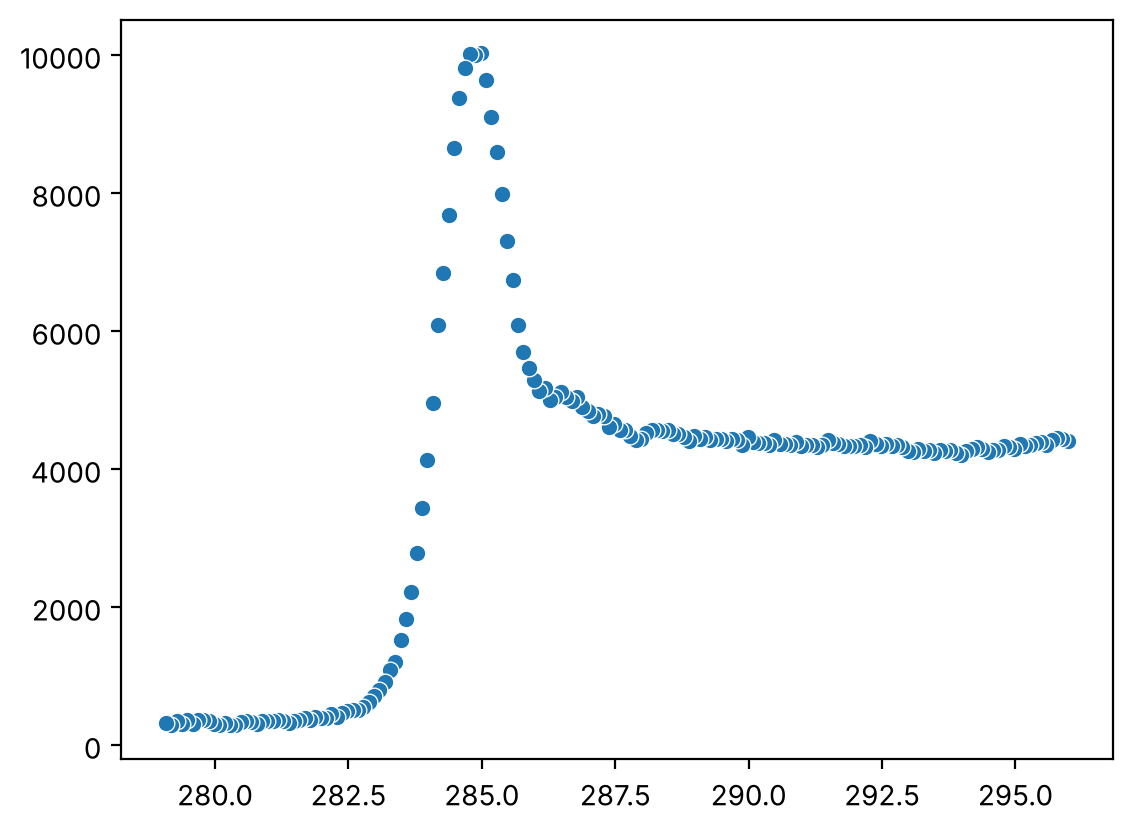

In [ ]:
eliminar = ["p2_", "p3_", "p4_", "sigmoid2_", "sigmoid3_", "sigmoid4_", "const_"]

y_mod = np.copy(dados_y)

for nome in eliminar:
   y_mod -= componentes_lorentz[nome]

sns.scatterplot(x=dados_x, y=y_mod);

Vamos criar um modelo apenas com um pico Voigtiano, sua sigmoide e uma linha de base constante.

In [ ]:
modelo_pico1 = VoigtModel(prefix="p1_")

modelo_sigmoid1 = StepModel(
    prefix="sigmoid1_", form="logistic", independent_vars=["x"]
)

modelo_constante = ConstantModel(prefix="const_")

modelo_composto = (
    modelo_pico1
    + modelo_sigmoid1
    + modelo_constante
)

Precisamos dos parâmetros. Como na aula, usamos o `guess` para a Voigtiana e deixamos o `gamma` livre.

In [ ]:
params_pico1 = modelo_pico1.guess(y_mod, x=dados_x)
params_sigmoid1 = modelo_sigmoid1.make_params()
params_constante = modelo_constante.make_params()

params = (
    params_pico1
    + params_sigmoid1
    + params_constante
)

params["p1_gamma"].set(vary=True)

params["sigmoid1_center"].set(vary=False, expr="p1_center")
params["sigmoid1_sigma"].set(vary=False, expr="p1_sigma")

params["const_c"].set(value=min(y_mod))

params

name,value,initial value,min,max,vary,expression
p1_amplitude,43826.7024,43826.70243873732,-inf,inf,True,
p1_center,285.135054,285.135054,-inf,inf,True,
p1_sigma,0.65000000,0.65,0.00000000,inf,True,
p1_gamma,0.65000000,None,-inf,inf,True,
p1_fwhm,2.34083891,None,-inf,inf,False,1.0692*p1_gamma+sqrt(0.8664*p1_gamma**2+5.545083*p1_sigma**2)
p1_height,14072.3685,None,-inf,inf,False,"(p1_amplitude/(max(1e-15, p1_sigma*sqrt(2*pi))))*real(wofz((1j*p1_gamma)/(max(1e-15, p1_sigma*sqrt(2)))))"
sigmoid1_amplitude,1.00000000,None,-inf,inf,True,
sigmoid1_center,285.135054,None,-inf,inf,False,p1_center
sigmoid1_sigma,0.65000000,None,-inf,inf,False,p1_sigma
const_c,285.573831,285.5738312539069,-inf,inf,True,


Vejamos o resultado.

[[Model]]
    ((Model(voigt, prefix='p1_') + Model(step, prefix='sigmoid1_', form='logistic')) + Model(constant, prefix='const_'))
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 78
    # data points      = 170
    # variables        = 6
    chi-square         = 1383024.61
    reduced chi-square = 8433.07689
    Akaike info crit   = 1542.67744
    Bayesian info crit = 1561.49224
    R-squared          = 0.99852007
[[Variables]]
    p1_amplitude:        13782.3200 +/- 130.802015 (0.95%) (init = 43826.7)
    p1_center:           284.739313 +/- 0.00525819 (0.00%) (init = 285.1351)
    p1_sigma:            0.40339301 +/- 0.01202065 (2.98%) (init = 0.65)
    p1_gamma:            0.33706659 +/- 0.01586561 (4.71%) (init = 0.65)
    p1_fwhm:             1.36077343 +/- 0.01023542 (0.75%) == '1.0692*p1_gamma+sqrt(0.8664*p1_gamma**2+5.545083*p1_sigma**2)'
    p1_height:           7795.45886 +/- 38.0633432 (0.49%) == '(p1_amplitude/(max(1e-15, p1_sigma*sqrt(2*pi))))*re

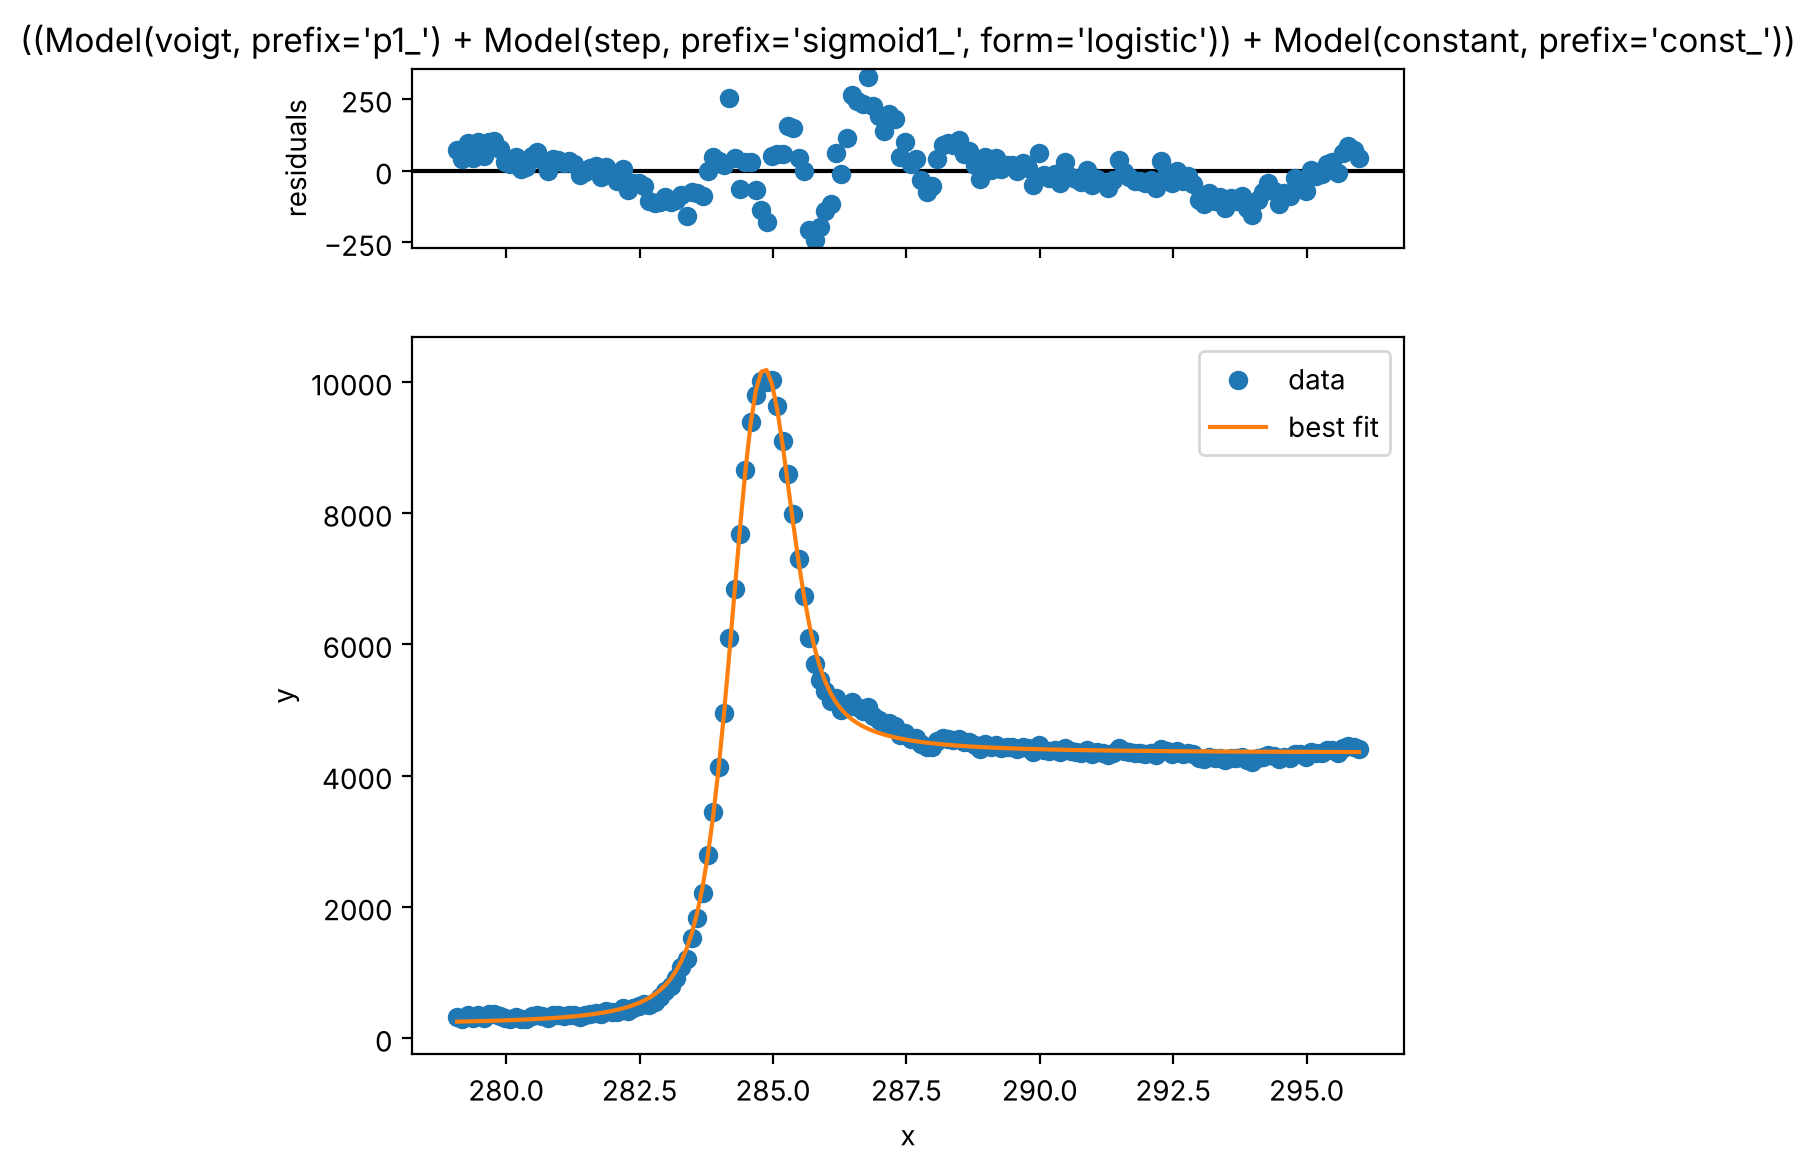

In [ ]:
resultado_fit = modelo_composto.fit(y_mod, params, x=dados_x)

print(resultado_fit.fit_report())

resultado_fit.plot();

Vejamos as componentes obtidas.

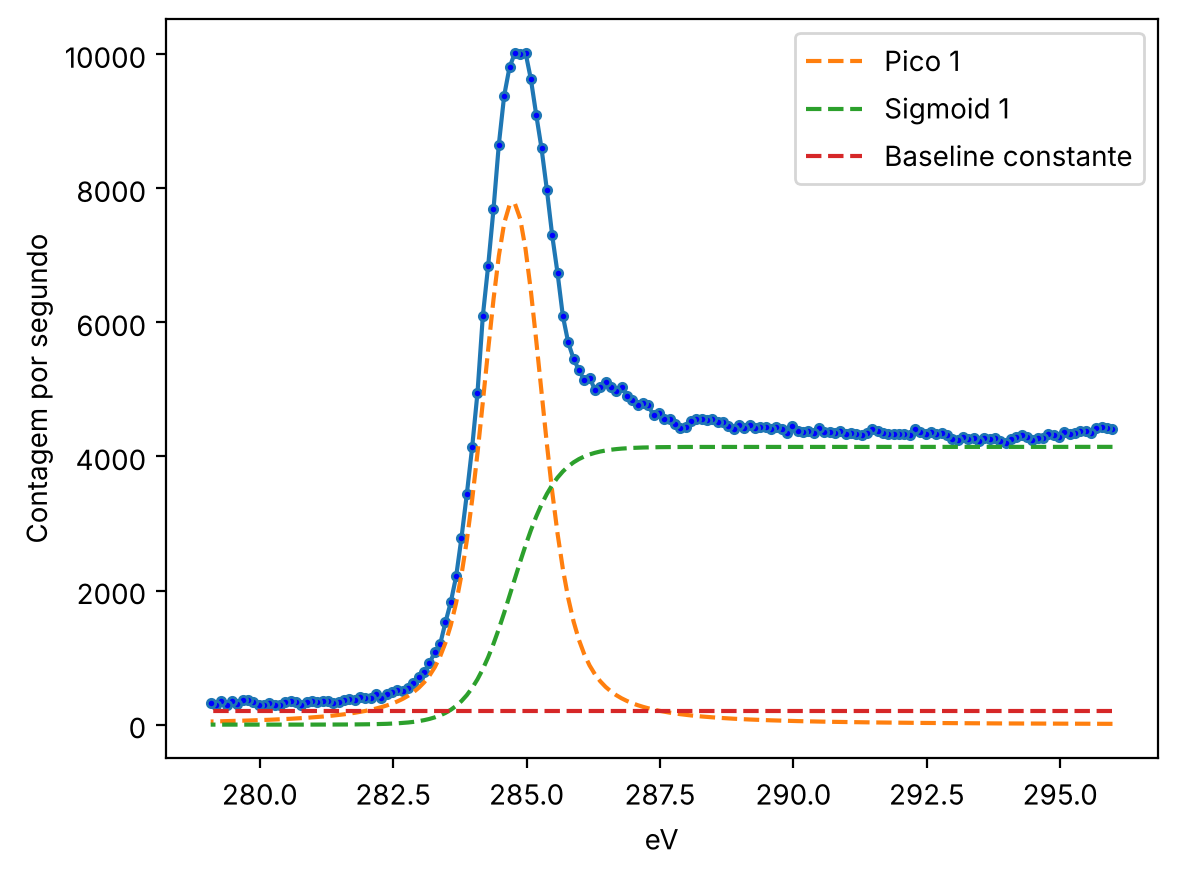

In [ ]:
componentes = resultado_fit.eval_components(x=dados_x)

fig, eixo = plt.subplots()
eixo.plot(dados_x, y_mod, marker="o", markerfacecolor="blue", markersize=3)
eixo.plot(dados_x, componentes["p1_"], "--", label="Pico 1")
eixo.plot(dados_x, componentes["sigmoid1_"], "--", label="Sigmoid 1")
eixo.plot(
    dados_x,
    np.ones(len(dados_x)) * componentes["const_"],
    "--",
    label="Baseline constante",
)
eixo.set(xlabel="eV", ylabel="Contagem por segundo")
eixo.legend();

Vamos guardar o objeto de parâmetros que obtivemos.

In [ ]:
params_pico1 = resultado_fit.params.copy()

#### Investigando o pico 2 isoladamente

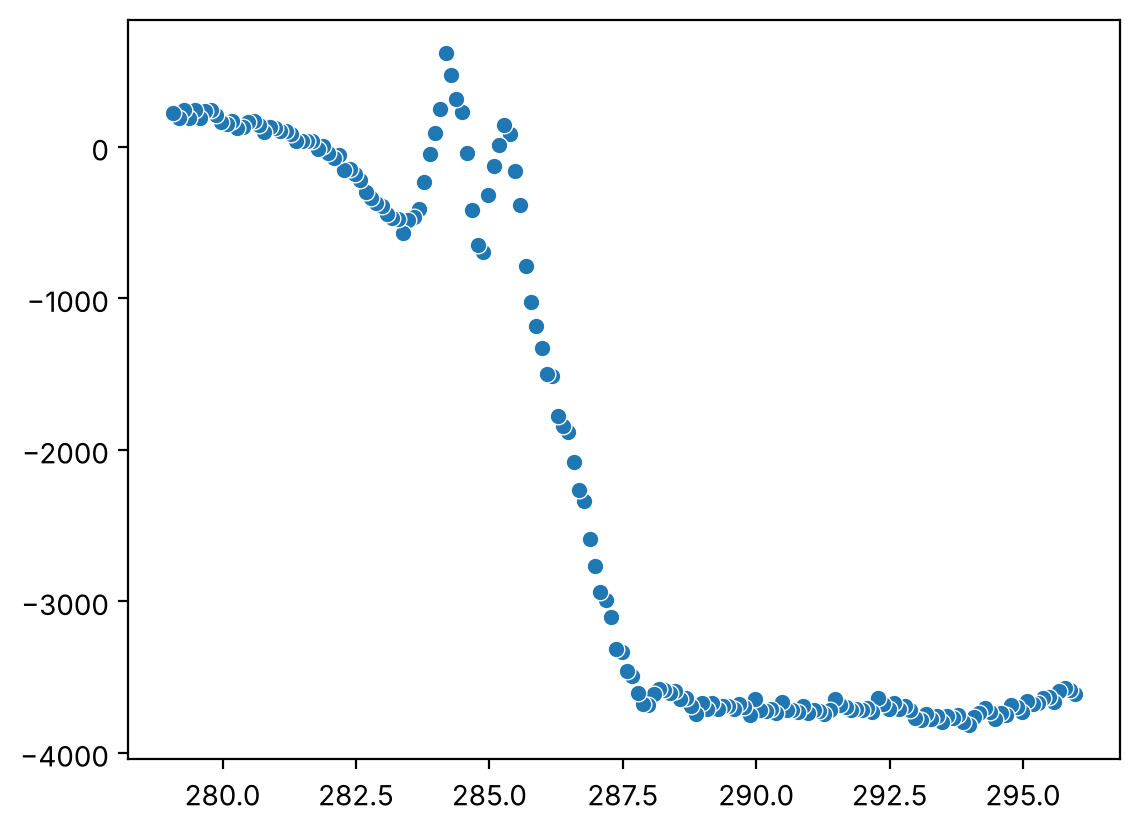

In [ ]:
eliminar = ["p1_", "p3_", "p4_", "sigmoid1_", "sigmoid3_", "sigmoid4_", "const_"]

y_mod = np.copy(dados_y)

for nome in eliminar:
   y_mod -= componentes_lorentz[nome]

sns.scatterplot(x=dados_x, y=y_mod);

Vamos criar um modelo apenas com um pico Voigtiano, sua sigmoide e uma linha de base constante.

In [ ]:
modelo_pico2 = VoigtModel(prefix="p2_")

modelo_sigmoid2 = StepModel(
    prefix="sigmoid2_", form="logistic", independent_vars=["x"]
)

modelo_constante = ConstantModel(prefix="const_")

modelo_composto = (
    modelo_pico2
    + modelo_sigmoid2
    + modelo_constante
)

Precisamos dos parâmetros. Como na aula, usamos o `guess` para a Voigtiana e deixamos o `gamma` livre.

In [ ]:
params_pico2 = modelo_pico2.guess(y_mod, x=dados_x)
params_sigmoid2 = modelo_sigmoid2.make_params()
params_constante = modelo_constante.make_params()

params = (
    params_pico2
    + params_sigmoid2
    + params_constante
)

params["p2_gamma"].set(vary=True)

params["sigmoid2_center"].set(vary=False, expr="p2_center")
params["sigmoid2_sigma"].set(vary=False, expr="p2_sigma")

params["const_c"].set(value=min(y_mod))

params

name,value,initial value,min,max,vary,expression
p2_amplitude,70839.9862,70839.98618186242,-inf,inf,True,
p2_center,282.630054,282.630054,-inf,inf,True,
p2_sigma,2.30750000,2.3074999999999704,0.00000000,inf,True,
p2_gamma,2.30750000,None,-inf,inf,True,
p2_fwhm,8.30997815,None,-inf,inf,False,1.0692*p2_gamma+sqrt(0.8664*p2_gamma**2+5.545083*p2_sigma**2)
p2_height,6407.35105,None,-inf,inf,False,"(p2_amplitude/(max(1e-15, p2_sigma*sqrt(2*pi))))*real(wofz((1j*p2_gamma)/(max(1e-15, p2_sigma*sqrt(2)))))"
sigmoid2_amplitude,1.00000000,None,-inf,inf,True,
sigmoid2_center,282.630054,None,-inf,inf,False,p2_center
sigmoid2_sigma,2.30750000,None,-inf,inf,False,p2_sigma
const_c,-3817.56951,-3817.5695054246994,-inf,inf,True,


Vejamos o resultado.

[[Model]]
    ((Model(voigt, prefix='p2_') + Model(step, prefix='sigmoid2_', form='logistic')) + Model(constant, prefix='const_'))
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 199
    # data points      = 170
    # variables        = 6
    chi-square         = 3791652.99
    reduced chi-square = 23119.8353
    Akaike info crit   = 1714.12741
    Bayesian info crit = 1732.94220
    R-squared          = 0.99261092
[[Variables]]
    p2_amplitude:        2804.94793 +/- 214.066782 (7.63%) (init = 70839.99)
    p2_center:           285.197409 +/- 0.03880929 (0.01%) (init = 282.6301)
    p2_sigma:            1.23673886 +/- 0.05679110 (4.59%) (init = 2.3075)
    p2_gamma:           -0.76354466 +/- 0.14758241 (19.33%) (init = 2.3075)
    p2_fwhm:             2.18135780 +/- 0.06053010 (2.77%) == '1.0692*p2_gamma+sqrt(0.8664*p2_gamma**2+5.545083*p2_sigma**2)'
    p2_height:           1601.68049 +/- 45.9604023 (2.87%) == '(p2_amplitude/(max(1e-15, p2_sigma*sqrt(2*pi

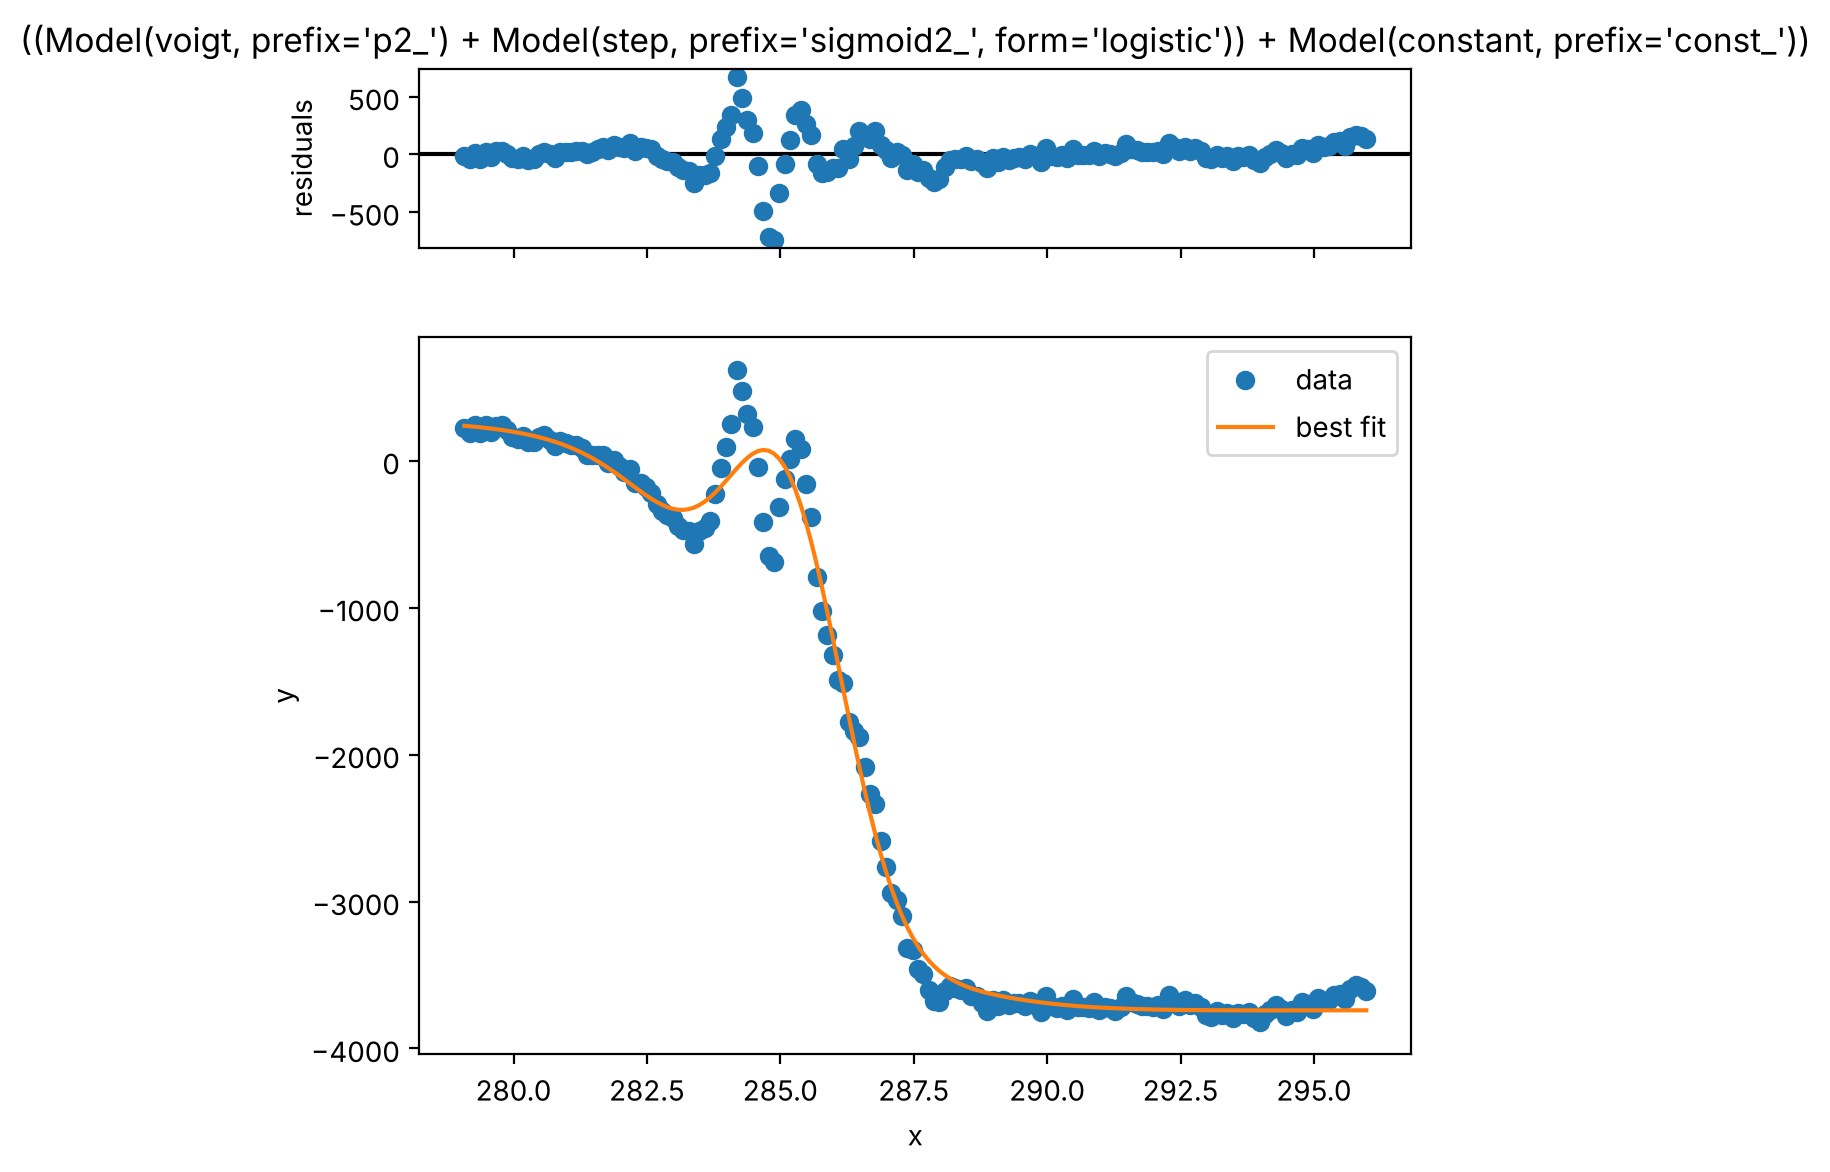

In [ ]:
resultado_fit = modelo_composto.fit(y_mod, params, x=dados_x)

print(resultado_fit.fit_report())

resultado_fit.plot();

Vejamos as componentes obtidas.

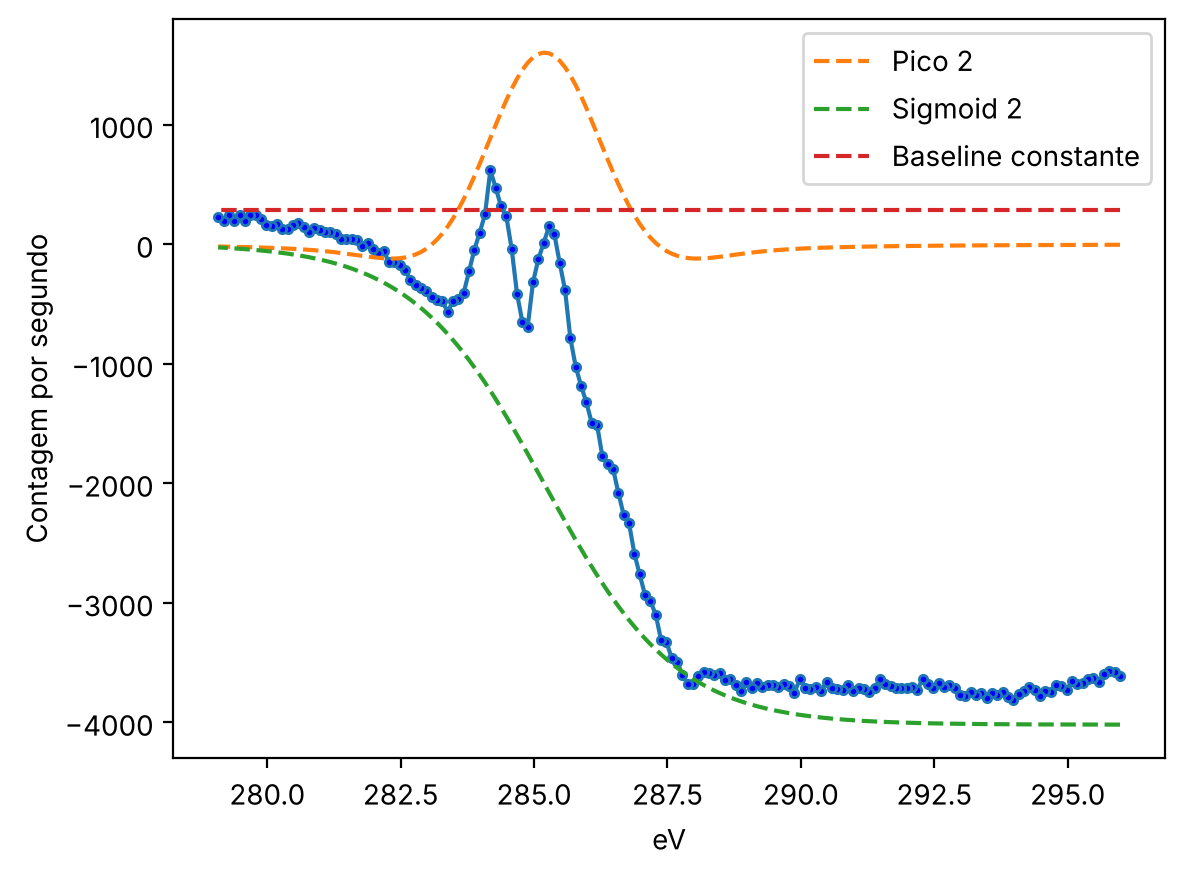

In [ ]:
componentes = resultado_fit.eval_components(x=dados_x)

fig, eixo = plt.subplots()
eixo.plot(dados_x, y_mod, marker="o", markerfacecolor="blue", markersize=3)
eixo.plot(dados_x, componentes["p2_"], "--", label="Pico 2")
eixo.plot(dados_x, componentes["sigmoid2_"], "--", label="Sigmoid 2")
eixo.plot(
    dados_x,
    np.ones(len(dados_x)) * componentes["const_"],
    "--",
    label="Baseline constante",
)
eixo.set(xlabel="eV", ylabel="Contagem por segundo")
eixo.legend();

> ⚠️ **O que aconteceu aqui com os meus dados** (teste feito com lmfit 1.3.4; em outra versão os números podem mudar um pouco)
>
> O `gamma` saiu **negativo** (−0,76), e o centro foi para 285,2 eV, em direção ao pico 1, em vez de ficar perto de 286,3 eV.

Vamos guardar o objeto de parâmetros que obtivemos.

In [ ]:
params_pico2 = resultado_fit.params.copy()

#### Investigando o pico 3 isoladamente

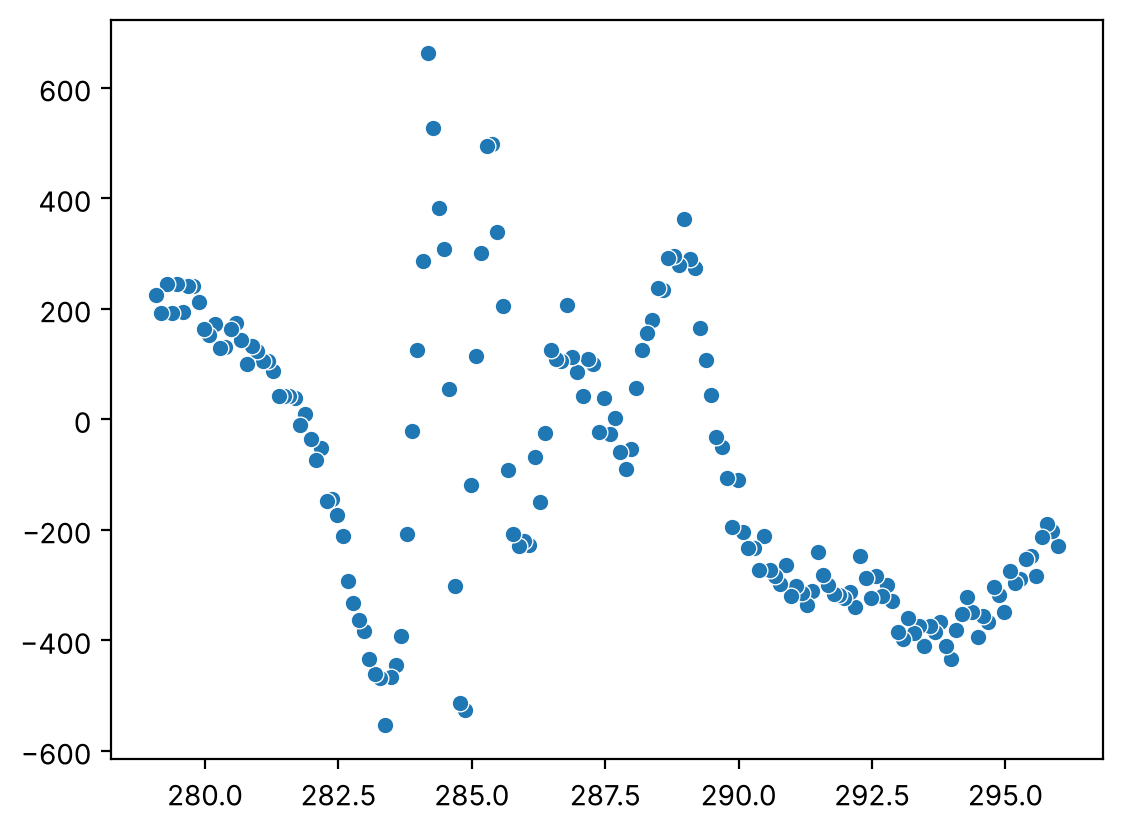

In [ ]:
eliminar = ["p1_", "p2_", "p4_", "sigmoid1_", "sigmoid2_", "sigmoid4_", "const_"]

y_mod = np.copy(dados_y)

for nome in eliminar:
   y_mod -= componentes_lorentz[nome]

sns.scatterplot(x=dados_x, y=y_mod);

Vamos criar um modelo apenas com um pico Voigtiano, sua sigmoide e uma linha de base constante.

In [ ]:
modelo_pico3 = VoigtModel(prefix="p3_")

modelo_sigmoid3 = StepModel(
    prefix="sigmoid3_", form="logistic", independent_vars=["x"]
)

modelo_constante = ConstantModel(prefix="const_")

modelo_composto = (
    modelo_pico3
    + modelo_sigmoid3
    + modelo_constante
)

Precisamos dos parâmetros. Como na aula, usamos o `guess` para a Voigtiana e deixamos o `gamma` livre.

In [ ]:
params_pico3 = modelo_pico3.guess(y_mod, x=dados_x)
params_sigmoid3 = modelo_sigmoid3.make_params()
params_constante = modelo_constante.make_params()

params = (
    params_pico3
    + params_sigmoid3
    + params_constante
)

params["p3_gamma"].set(vary=True)

params["sigmoid3_center"].set(vary=False, expr="p3_center")
params["sigmoid3_sigma"].set(vary=False, expr="p3_sigma")

params["const_c"].set(value=min(y_mod))

params

name,value,initial value,min,max,vary,expression
p3_amplitude,28182.2748,28182.27483646059,-inf,inf,True,
p3_center,284.192123,284.1921229655173,-inf,inf,True,
p3_sigma,3.34750000,3.3474999999999855,0.00000000,inf,True,
p3_gamma,3.34750000,None,-inf,inf,True,
p3_fwhm,12.0553204,None,-inf,inf,False,1.0692*p3_gamma+sqrt(0.8664*p3_gamma**2+5.545083*p3_sigma**2)
p3_height,1757.10300,None,-inf,inf,False,"(p3_amplitude/(max(1e-15, p3_sigma*sqrt(2*pi))))*real(wofz((1j*p3_gamma)/(max(1e-15, p3_sigma*sqrt(2)))))"
sigmoid3_amplitude,1.00000000,None,-inf,inf,True,
sigmoid3_center,284.192123,None,-inf,inf,False,p3_center
sigmoid3_sigma,3.34750000,None,-inf,inf,False,p3_sigma
const_c,-553.909788,-553.9097878558815,-inf,inf,True,


Vejamos o resultado.

[[Model]]
    ((Model(voigt, prefix='p3_') + Model(step, prefix='sigmoid3_', form='logistic')) + Model(constant, prefix='const_'))
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 282
    # data points      = 170
    # variables        = 6
    chi-square         = 5879860.69
    reduced chi-square = 35852.8091
    Akaike info crit   = 1788.71168
    Bayesian info crit = 1807.52647
    R-squared          = 0.47196434
[[Variables]]
    p3_amplitude:        645.264445 +/- 213.358369 (33.07%) (init = 28182.27)
    p3_center:           289.004412 +/- 0.14126040 (0.05%) (init = 284.1921)
    p3_sigma:            0.46226744 +/- 0.29656090 (64.15%) (init = 3.3475)
    p3_gamma:            0.11448629 +/- 0.47481628 (414.74%) (init = 3.3475)
    p3_fwhm:             1.21615980 +/- 0.28168785 (23.16%) == '1.0692*p3_gamma+sqrt(0.8664*p3_gamma**2+5.545083*p3_sigma**2)'
    p3_height:           461.895003 +/- 78.7052521 (17.04%) == '(p3_amplitude/(max(1e-15, p3_sigma*sqrt

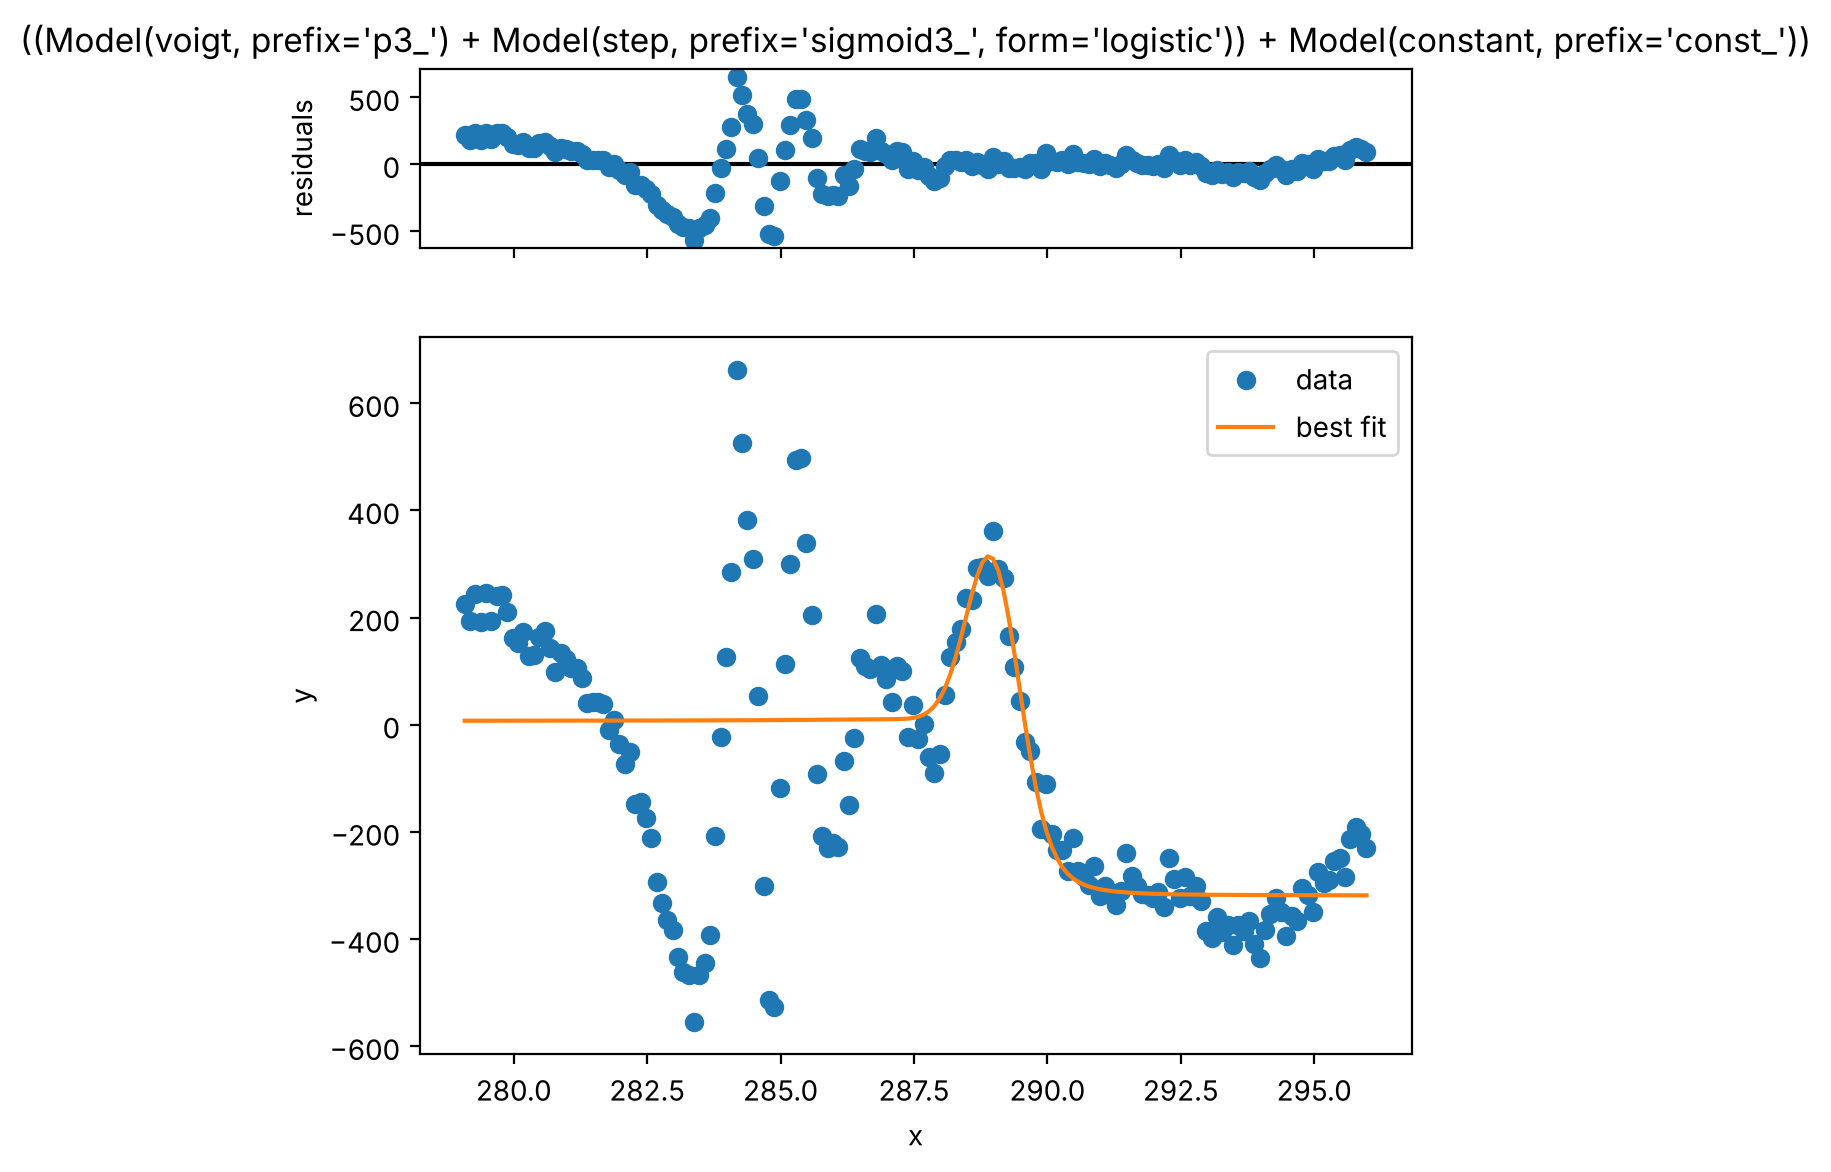

In [ ]:
resultado_fit = modelo_composto.fit(y_mod, params, x=dados_x)

print(resultado_fit.fit_report())

resultado_fit.plot();

Vejamos as componentes obtidas.

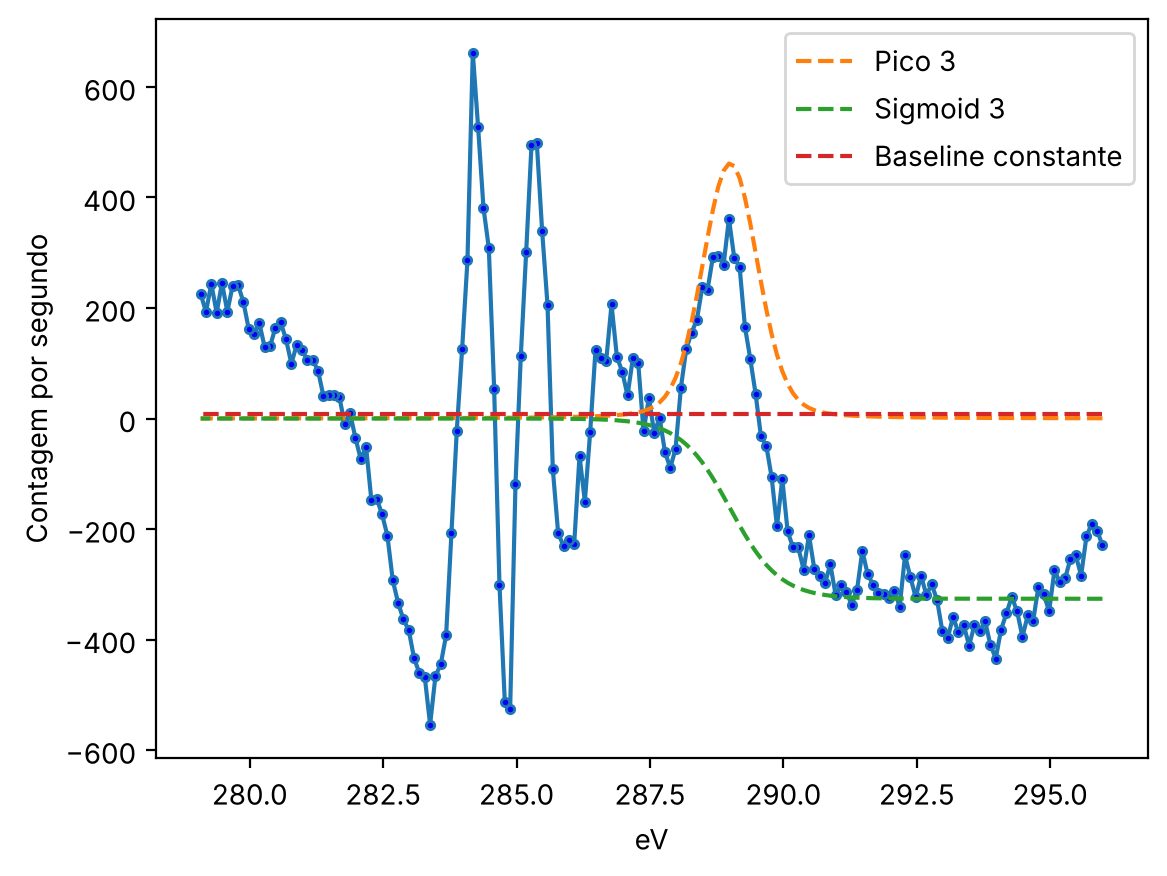

In [ ]:
componentes = resultado_fit.eval_components(x=dados_x)

fig, eixo = plt.subplots()
eixo.plot(dados_x, y_mod, marker="o", markerfacecolor="blue", markersize=3)
eixo.plot(dados_x, componentes["p3_"], "--", label="Pico 3")
eixo.plot(dados_x, componentes["sigmoid3_"], "--", label="Sigmoid 3")
eixo.plot(
    dados_x,
    np.ones(len(dados_x)) * componentes["const_"],
    "--",
    label="Baseline constante",
)
eixo.set(xlabel="eV", ylabel="Contagem por segundo")
eixo.legend();

> ⚠️ **O que aconteceu aqui com os meus dados** (teste feito com lmfit 1.3.4; em outra versão os números podem mudar um pouco)
>
> Ajuste fraco: R² ≈ 0,47. O pico 3 é pequeno, e o `y_mod` tem muito "resto" dos outros picos.

Vamos guardar o objeto de parâmetros que obtivemos.

In [ ]:
params_pico3 = resultado_fit.params.copy()

#### Investigando o pico 4 isoladamente

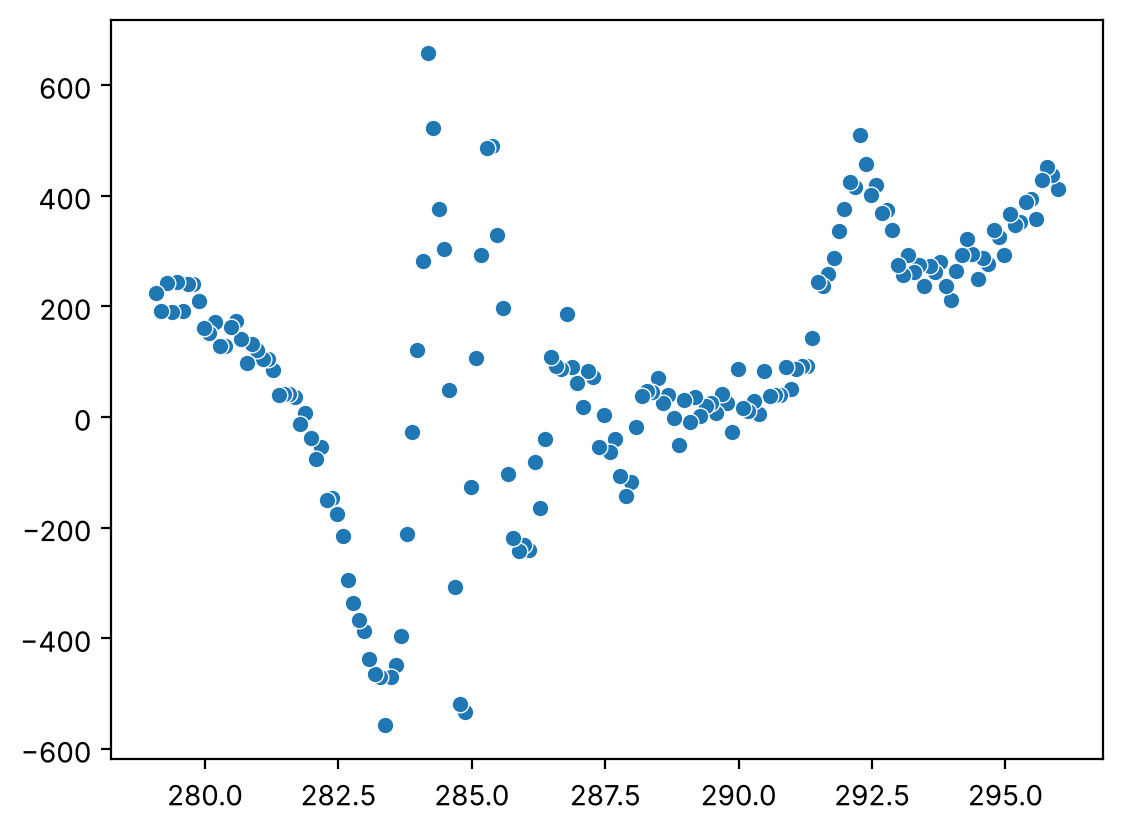

In [ ]:
eliminar = ["p1_", "p2_", "p3_", "sigmoid1_", "sigmoid2_", "sigmoid3_", "const_"]

y_mod = np.copy(dados_y)

for nome in eliminar:
   y_mod -= componentes_lorentz[nome]

sns.scatterplot(x=dados_x, y=y_mod);

Vamos criar um modelo apenas com um pico Voigtiano, sua sigmoide e uma linha de base constante.

In [ ]:
modelo_pico4 = VoigtModel(prefix="p4_")

modelo_sigmoid4 = StepModel(
    prefix="sigmoid4_", form="logistic", independent_vars=["x"]
)

modelo_constante = ConstantModel(prefix="const_")

modelo_composto = (
    modelo_pico4
    + modelo_sigmoid4
    + modelo_constante
)

Precisamos dos parâmetros. Como na aula, usamos o `guess` para a Voigtiana e deixamos o `gamma` livre.

In [ ]:
params_pico4 = modelo_pico4.guess(y_mod, x=dados_x)
params_sigmoid4 = modelo_sigmoid4.make_params()
params_constante = modelo_constante.make_params()

params = (
    params_pico4
    + params_sigmoid4
    + params_constante
)

params["p4_gamma"].set(vary=True)

params["sigmoid4_center"].set(vary=False, expr="p4_center")
params["sigmoid4_sigma"].set(vary=False, expr="p4_sigma")

params["const_c"].set(value=min(y_mod))

params

name,value,initial value,min,max,vary,expression
p4_amplitude,46189.3690,46189.36898741553,-inf,inf,True,
p4_center,288.608625,288.60862542857143,-inf,inf,True,
p4_sigma,5.49250000,5.49250000000003,0.00000000,inf,True,
p4_gamma,5.49250000,None,-inf,inf,True,
p4_fwhm,19.7800888,None,-inf,inf,False,1.0692*p4_gamma+sqrt(0.8664*p4_gamma**2+5.545083*p4_sigma**2)
p4_height,1755.14792,None,-inf,inf,False,"(p4_amplitude/(max(1e-15, p4_sigma*sqrt(2*pi))))*real(wofz((1j*p4_gamma)/(max(1e-15, p4_sigma*sqrt(2)))))"
sigmoid4_amplitude,1.00000000,None,-inf,inf,True,
sigmoid4_center,288.608625,None,-inf,inf,False,p4_center
sigmoid4_sigma,5.49250000,None,-inf,inf,False,p4_sigma
const_c,-557.354529,-557.3545286828147,-inf,inf,True,


Vejamos o resultado.

[[Model]]
    ((Model(voigt, prefix='p4_') + Model(step, prefix='sigmoid4_', form='logistic')) + Model(constant, prefix='const_'))
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 470
    # data points      = 170
    # variables        = 6
    chi-square         = 5132552.06
    reduced chi-square = 31296.0492
    Akaike info crit   = 1765.60357
    Bayesian info crit = 1784.41836
    R-squared          = 0.45798180
[[Variables]]
    p4_amplitude:       -65107.3397 +/- 60111.0740 (92.33%) (init = 46189.37)
    p4_center:           281.589402 +/- 0.27333783 (0.10%) (init = 288.6086)
    p4_sigma:            0.27268015 +/- 0.23288629 (85.41%) (init = 5.4925)
    p4_gamma:            16.4492048 +/- 6.99946418 (42.55%) (init = 5.4925)
    p4_fwhm:             32.9119683 +/- 13.9894559 (42.51%) == '1.0692*p4_gamma+sqrt(0.8664*p4_gamma**2+5.545083*p4_sigma**2)'
    p4_height:          -1259.55144 +/- 632.381015 (50.21%) == '(p4_amplitude/(max(1e-15, p4_sigma*sqrt(

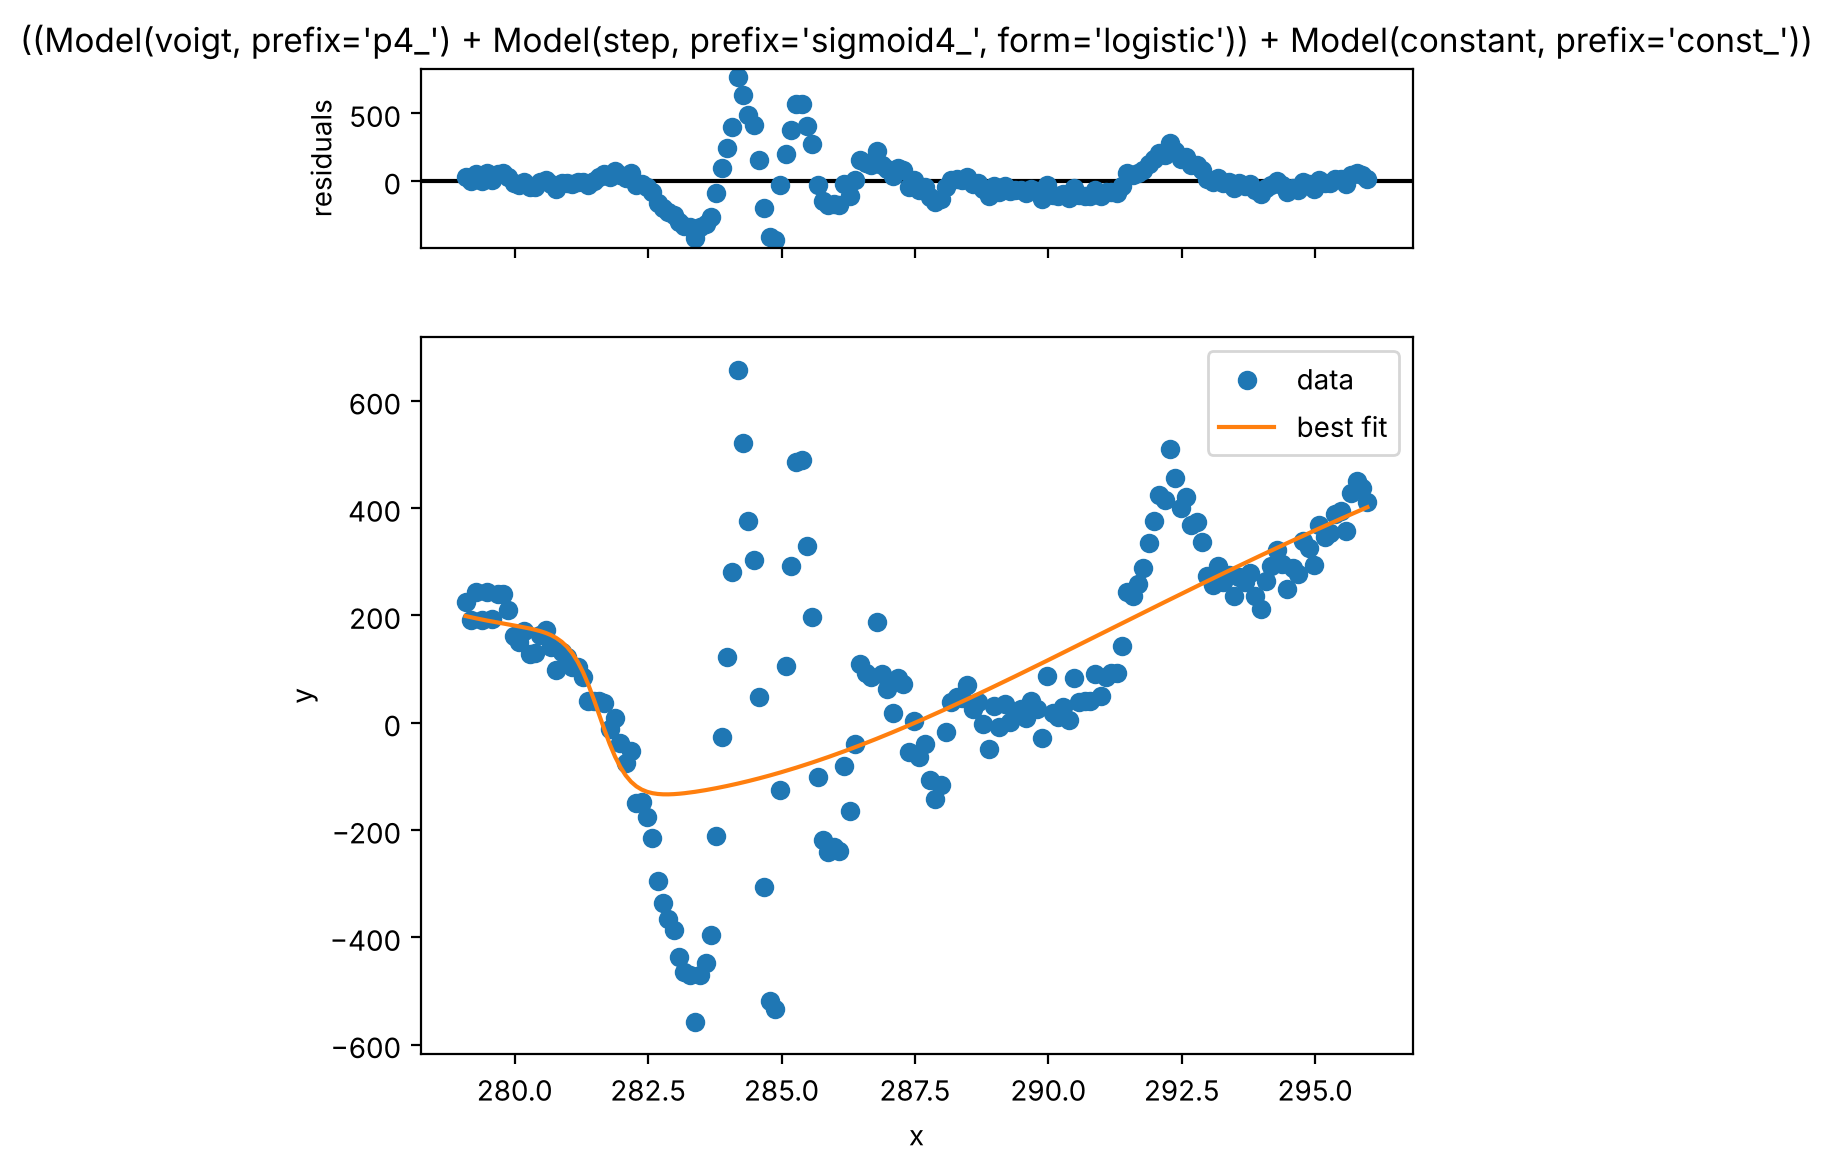

In [ ]:
resultado_fit = modelo_composto.fit(y_mod, params, x=dados_x)

print(resultado_fit.fit_report())

resultado_fit.plot();

Vejamos as componentes obtidas.

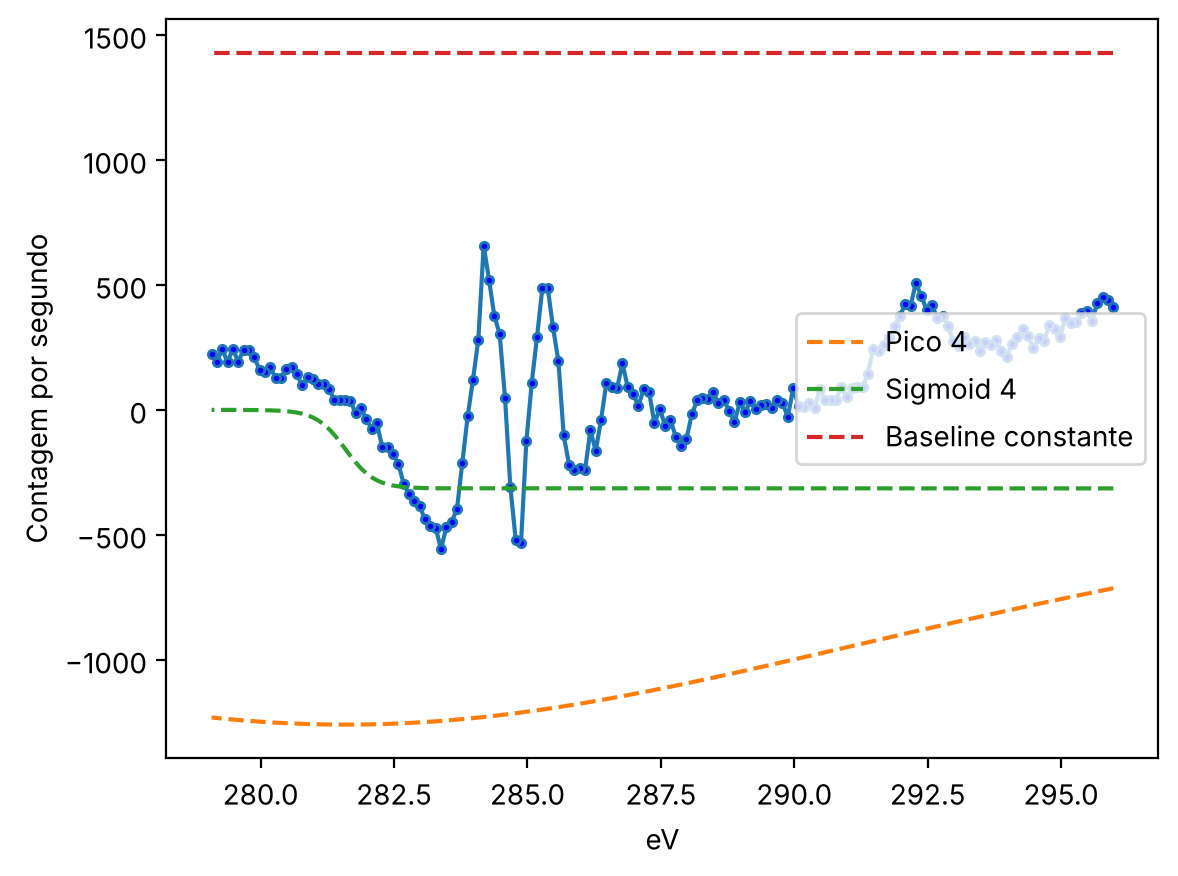

In [ ]:
componentes = resultado_fit.eval_components(x=dados_x)

fig, eixo = plt.subplots()
eixo.plot(dados_x, y_mod, marker="o", markerfacecolor="blue", markersize=3)
eixo.plot(dados_x, componentes["p4_"], "--", label="Pico 4")
eixo.plot(dados_x, componentes["sigmoid4_"], "--", label="Sigmoid 4")
eixo.plot(
    dados_x,
    np.ones(len(dados_x)) * componentes["const_"],
    "--",
    label="Baseline constante",
)
eixo.set(xlabel="eV", ylabel="Contagem por segundo")
eixo.legend();

> ⚠️ **O que aconteceu aqui com os meus dados** (teste feito com lmfit 1.3.4; em outra versão os números podem mudar um pouco)
>
> Aqui o ajuste falhou: o `guess` começou em ~288,6 eV, e o pico 4 terminou em **281,6 eV** (o CF₂ está perto de 292 eV), com área **negativa** e R² ≈ 0,46. O `guess` só funciona bem com dados "bem comportados", como a própria aula avisa, e um pico tão pequeno não é o caso.

Vamos guardar o objeto de parâmetros que obtivemos.

In [ ]:
params_pico4 = resultado_fit.params.copy()

#### Juntando os resultados

Vamos retornar aos dados originais e ao modelo original com 4 picos, agora Voigtianos.

In [ ]:
modelo_pico1 = VoigtModel(prefix="p1_")
modelo_pico2 = VoigtModel(prefix="p2_")
modelo_pico3 = VoigtModel(prefix="p3_")
modelo_pico4 = VoigtModel(prefix="p4_")

modelo_sigmoid1 = StepModel(
    prefix="sigmoid1_", form="logistic", independent_vars=["x"]
)
modelo_sigmoid2 = StepModel(
    prefix="sigmoid2_", form="logistic", independent_vars=["x"]
)
modelo_sigmoid3 = StepModel(
    prefix="sigmoid3_", form="logistic", independent_vars=["x"]
)
modelo_sigmoid4 = StepModel(
    prefix="sigmoid4_", form="logistic", independent_vars=["x"]
)

modelo_constante = ConstantModel(prefix="const_")

modelo_composto = (
    modelo_pico1
    + modelo_sigmoid1
    + modelo_pico2
    + modelo_sigmoid2
    + modelo_pico3
    + modelo_sigmoid3
    + modelo_pico4
    + modelo_sigmoid4
    + modelo_constante
)

Os parâmetros que usaremos serão os obtidos dos ajustes isolados.

In [ ]:
params = params_pico1

params.update(params_pico2)
params.update(params_pico3)
params.update(params_pico4)

params

name,value,standard error,relative error,initial value,min,max,vary,expression
p1_amplitude,13782.3200,130.802015,(0.95%),43826.70243873732,-inf,inf,True,
p1_center,284.739313,0.00525819,(0.00%),285.135054,-inf,inf,True,
p1_sigma,0.40339301,0.01202065,(2.98%),0.65,0.00000000,inf,True,
p1_gamma,0.33706659,0.01586561,(4.71%),0.65,-inf,inf,True,
p1_fwhm,1.36077343,0.01023542,(0.75%),2.340838914822288,-inf,inf,False,1.0692*p1_gamma+sqrt(0.8664*p1_gamma**2+5.545083*p1_sigma**2)
p1_height,7795.45886,38.0633432,(0.49%),14072.368513183244,-inf,inf,False,"(p1_amplitude/(max(1e-15, p1_sigma*sqrt(2*pi))))*real(wofz((1j*p1_gamma)/(max(1e-15, p1_sigma*sqrt(2)))))"
sigmoid1_amplitude,4143.68989,17.2105587,(0.42%),1.0,-inf,inf,True,
sigmoid1_center,284.739313,0.00525819,(0.00%),285.135054,-inf,inf,False,p1_center
sigmoid1_sigma,0.40339301,0.01202065,(2.98%),0.65,-inf,inf,False,p1_sigma
const_c,1429.69175,639.868454,(44.76%),-557.3545286828147,-inf,inf,True,


Vamos ajustar o modelo.

[[Model]]
    ((((((((Model(voigt, prefix='p1_') + Model(step, prefix='sigmoid1_', form='logistic')) + Model(voigt, prefix='p2_')) + Model(step, prefix='sigmoid2_', form='logistic')) + Model(voigt, prefix='p3_')) + Model(step, prefix='sigmoid3_', form='logistic')) + Model(voigt, prefix='p4_')) + Model(step, prefix='sigmoid4_', form='logistic')) + Model(constant, prefix='const_'))
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 7150
    # data points      = 170
    # variables        = 21
    chi-square         = 307376.680
    reduced chi-square = 2062.93074
    Akaike info crit   = 1317.00524
    Bayesian info crit = 1382.85700
    R-squared          = 0.99966784
[[Variables]]
    p1_amplitude:        8754.12228 +/- 11103.5687 (126.84%) (init = 13782.32)
    p1_center:           284.796038 +/- 0.01566616 (0.01%) (init = 284.7393)
    p1_sigma:            0.65353078 +/- 0.21255367 (32.52%) (init = 0.403393)
    p1_gamma:           -0.25686313 +/- 0.91355958

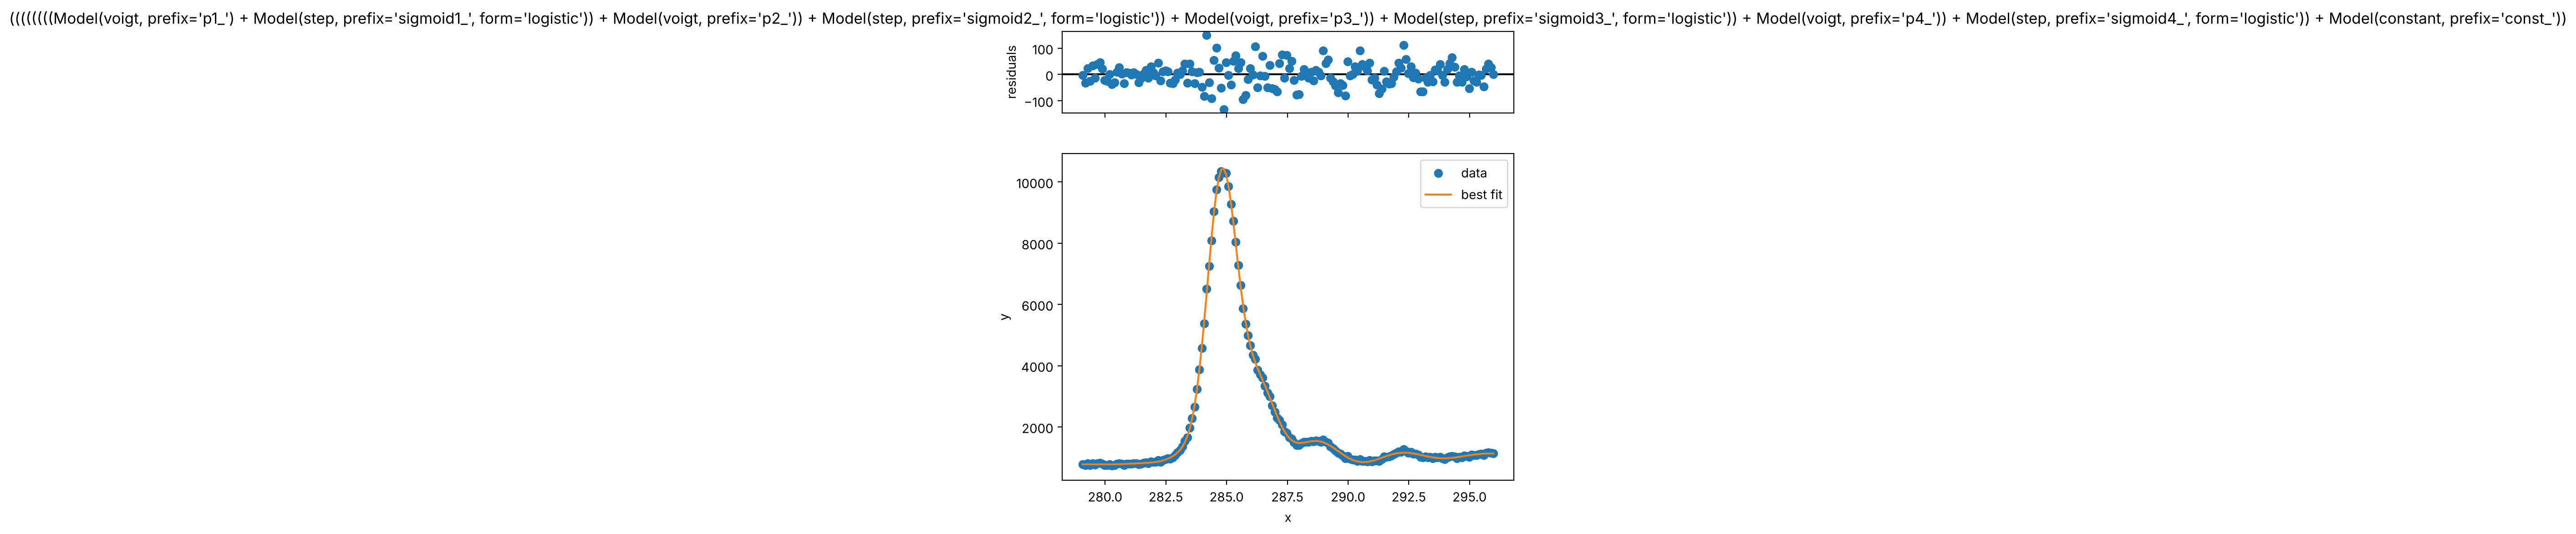

In [ ]:
resultado_fit = modelo_composto.fit(dados_y, params, x=dados_x)

print(resultado_fit.fit_report())

resultado_fit.plot();

> ⚠️ **O que aconteceu aqui com os meus dados** (teste feito com lmfit 1.3.4; em outra versão os números podem mudar um pouco)
>
> O R² é alto (0,9997), mas os resultados **não fazem sentido**:
>
> - o pico 3 (O–C=O) sumiu (área ≈ 0);
> - o pico 4 foi parar em 283,1 eV, com `gamma` = 23;
> - o pico 2, o pico 3 e o resultado final do pico 1 têm `gamma` negativo;
> - a constante da linha de base ficou negativa (−270);
> - várias incertezas passam de 1000%.
>
> Na figura das componentes, isso aparece como picos ondulados e negativos.

Vamos observar a análise dos resíduos.

p-valor de Shapiro-Wilk dos resíduos: 0.267


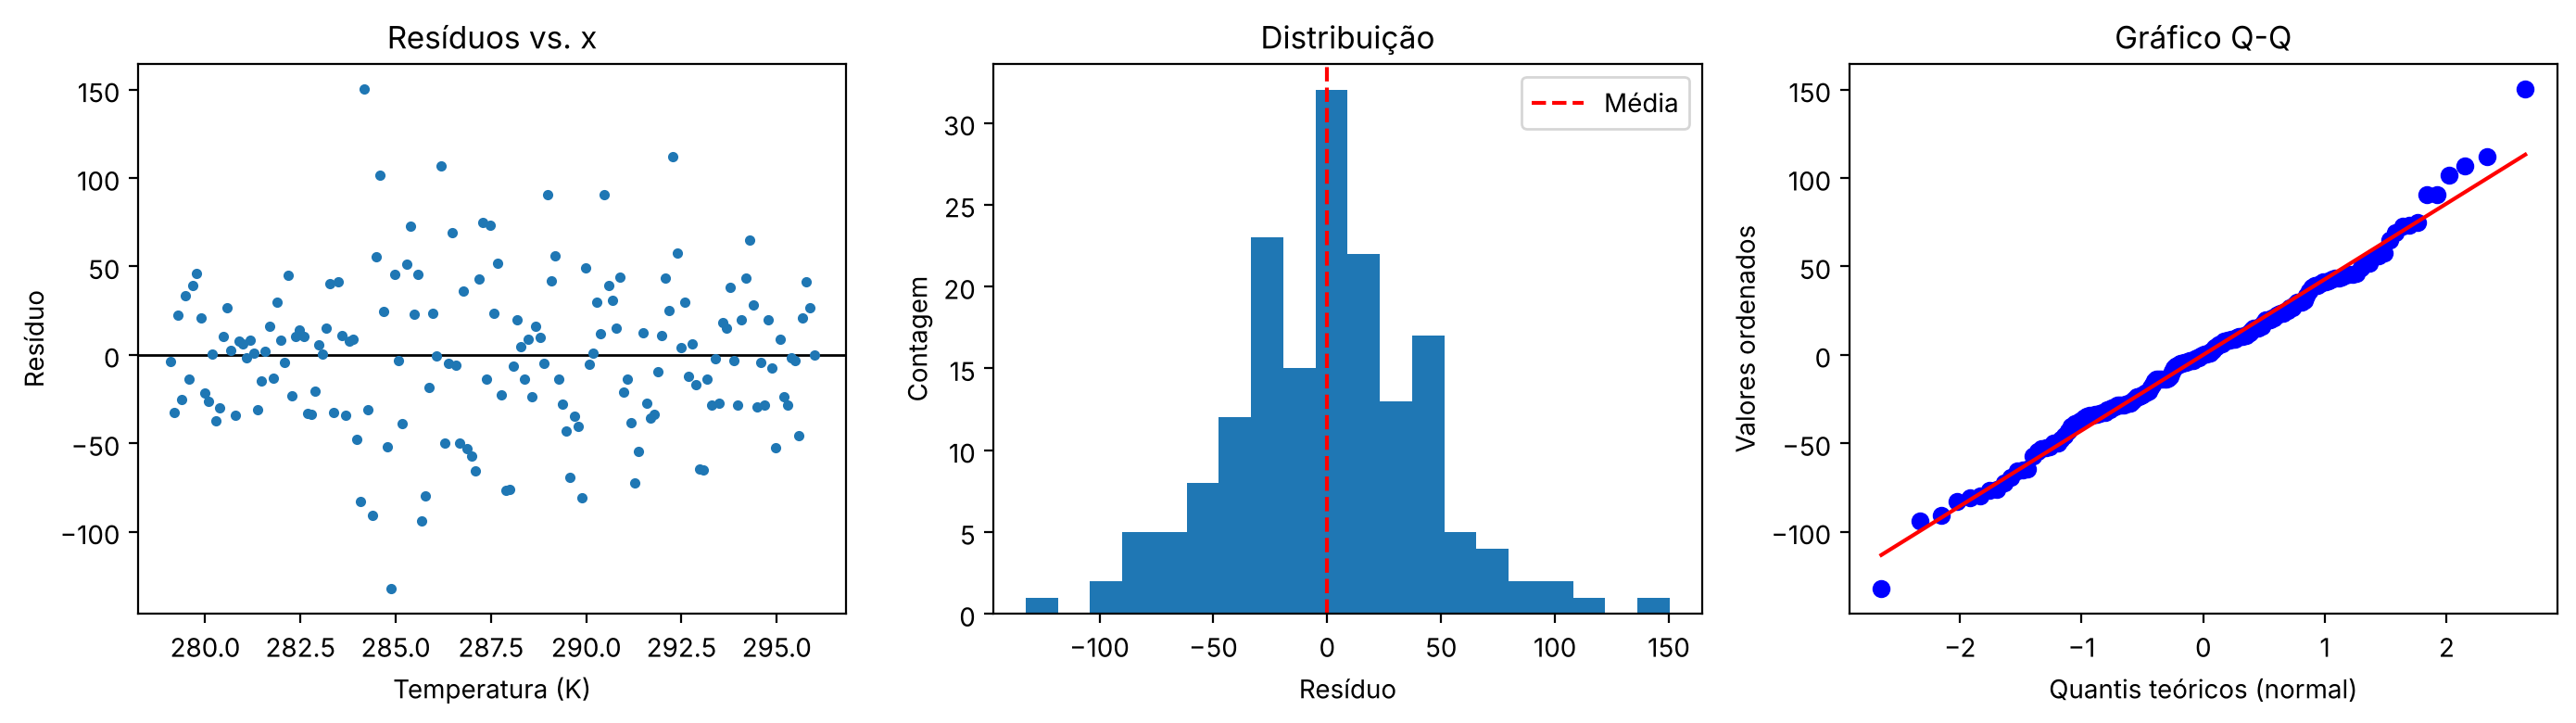

In [ ]:
analise_residuos(dados_x, dados_y, resultado_fit.best_fit)

Para encerrar, faremos a análise das componentes.

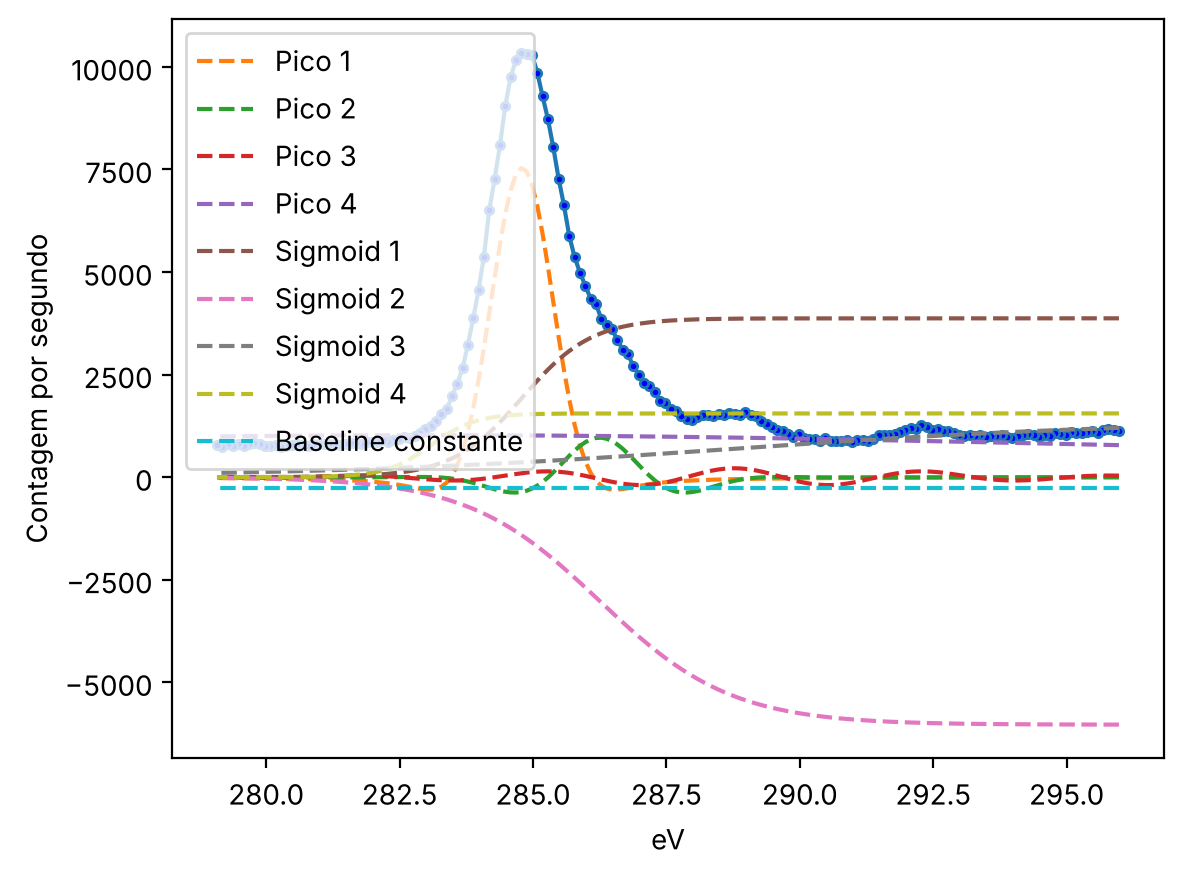

In [ ]:
componentes = resultado_fit.eval_components(x=dados_x)

fig, eixo = plt.subplots()
eixo.plot(dados_x, dados_y, marker="o", markerfacecolor="blue", markersize=3)
eixo.plot(dados_x, componentes["p1_"], "--", label="Pico 1")
eixo.plot(dados_x, componentes["p2_"], "--", label="Pico 2")
eixo.plot(dados_x, componentes["p3_"], "--", label="Pico 3")
eixo.plot(dados_x, componentes["p4_"], "--", label="Pico 4")
eixo.plot(dados_x, componentes["sigmoid1_"], "--", label="Sigmoid 1")
eixo.plot(dados_x, componentes["sigmoid2_"], "--", label="Sigmoid 2")
eixo.plot(dados_x, componentes["sigmoid3_"], "--", label="Sigmoid 3")
eixo.plot(dados_x, componentes["sigmoid4_"], "--", label="Sigmoid 4")
eixo.plot(
    dados_x,
    np.ones(len(dados_x)) * componentes["const_"],
    "--",
    label="Baseline constante",
)
eixo.set(xlabel="eV", ylabel="Contagem por segundo")
eixo.legend();

## Si 2p – deconvolução de picos

Esta seção mostra uma forma de tratar os dados de XPS da região Si 2p usando o `lmfit`, seguindo a aula.

### Carregando os dados

Os dados de XPS estão no arquivo `Si2p_Scan.avg`. A função `le_arquivo_avg` (definida no início) faz o papel do `pd.read_excel` da aula.

In [ ]:
ARQUIVO_XPS = "Si2p_Scan.avg"

df = le_arquivo_avg(ARQUIVO_XPS)

df = df.dropna()

Vamos ver os dados que temos.

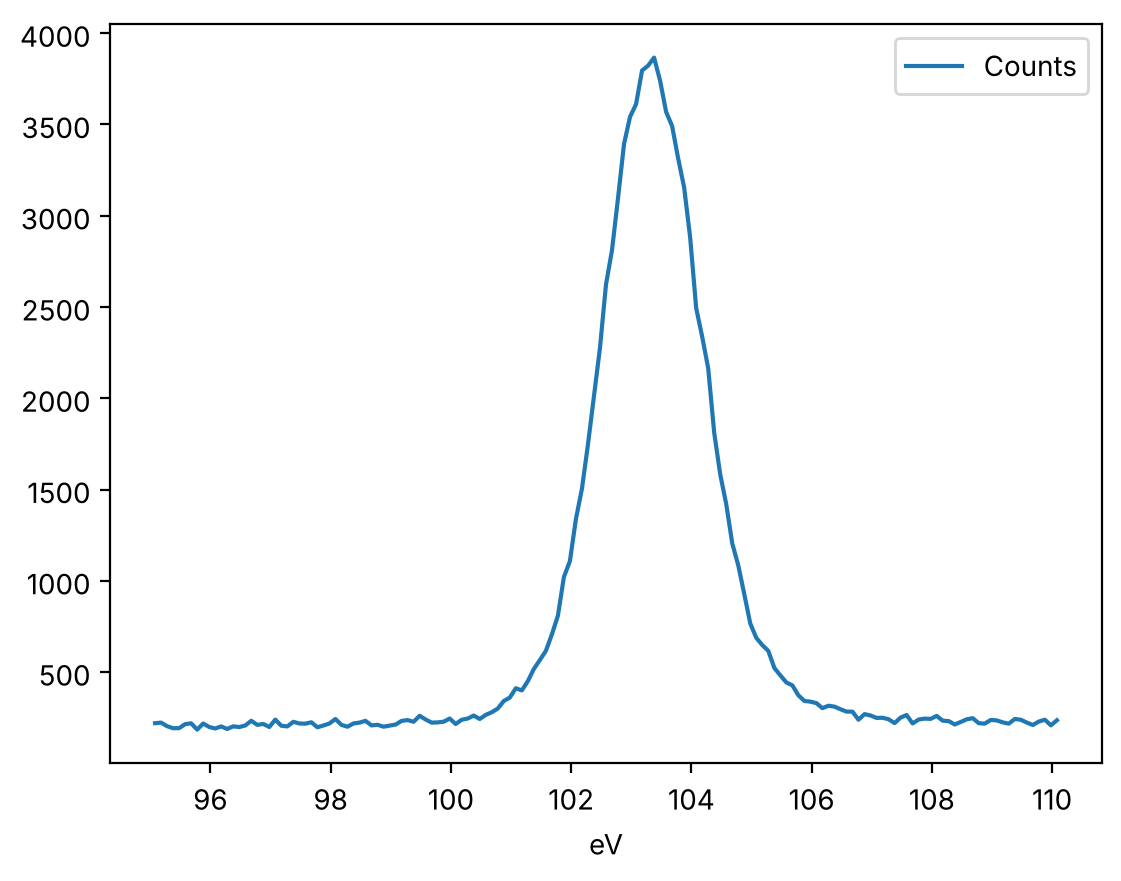

In [ ]:
df.plot("eV", "Counts");

Para este estudo em particular, não queremos dados com Binding Energy acima de 108 eV. Acima disso só há fundo.

In [ ]:
logic = df["eV"] <= 108
df = df.loc[logic]

Vamos checar os dados novamente.

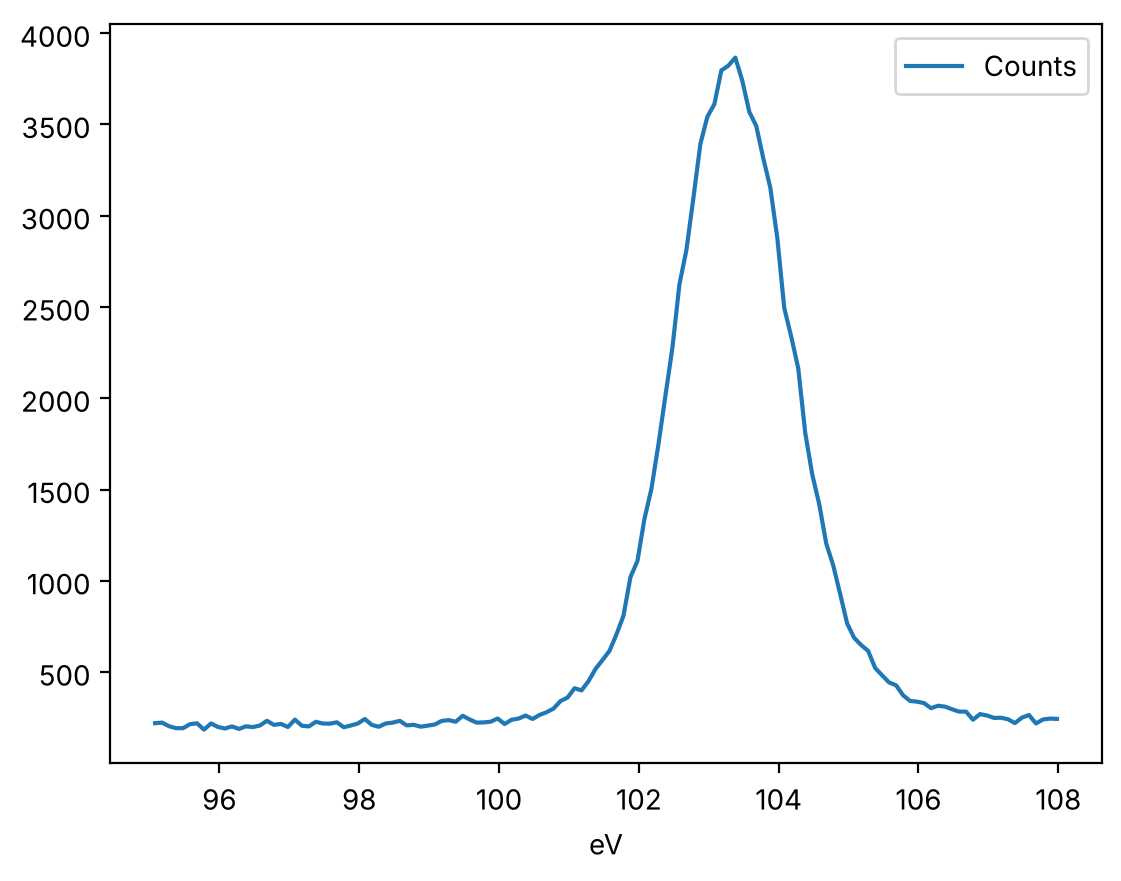

In [ ]:
df.plot("eV", "Counts");

Deste gráfico observamos um único pico perto de 103,3 eV e uma linha de base perto de 210 contagens.

### Comentário sobre picos com base direita e esquerda com diferentes valores

Igual à aula: muitas vezes, picos obtidos por espectroscopia têm valores diferentes para as bases que estão à direita e à esquerda do pico. Apenas uma função de pico junto com uma linha de base constante *não* são capazes de descrever essa situação. A estratégia é adicionar uma curva sigmoidal.

### Definição do modelo

Assim como na aula, vamos modelar os picos como Lorentzianas.

In [ ]:
modelo_pico1 = LorentzianModel(prefix="p1_")

Vamos agora associar uma **linha de base sigmoidal** para cada pico, usando a função degrau (`StepModel`) com `form="logistic"` e `independent_vars=["x"]`, exatamente como na aula. Como temos 1 pico, criamos 1 sigmoide.

In [ ]:
modelo_sigmoid1 = StepModel(
    prefix="sigmoid1_", form="logistic", independent_vars=["x"]
)

A linha de base será um modelo constante.

In [ ]:
modelo_constante = ConstantModel(prefix="const_")

Finalmente, construímos o modelo composto pela combinação linear dos modelos individuais.

In [ ]:
modelo_composto = (
    modelo_pico1
    + modelo_sigmoid1
    + modelo_constante
)

### Palpite inicial dos parâmetros

Vamos criar os parâmetros do modelo composto.

In [ ]:
params_pico1 = modelo_pico1.make_params()
params_sigmoid1 = modelo_sigmoid1.make_params()
params_constante = modelo_constante.make_params()

params = (
    params_pico1
    + params_sigmoid1
    + params_constante
)

params

name,value,initial value,min,max,vary,expression
p1_amplitude,1.00000000,None,-inf,inf,True,
p1_center,0.00000000,None,-inf,inf,True,
p1_sigma,1.00000000,None,0.00000000,inf,True,
p1_fwhm,2.00000000,None,-inf,inf,False,2.0000000*p1_sigma
p1_height,0.31830990,None,-inf,inf,False,"0.3183099*p1_amplitude/max(1e-15, p1_sigma)"
sigmoid1_amplitude,1.00000000,None,-inf,inf,True,
sigmoid1_center,0.00000000,None,-inf,inf,True,
sigmoid1_sigma,1.00000000,None,-inf,inf,True,
const_c,0.00000000,None,-inf,inf,True,


Agora iremos restringir os parâmetros. Assim como na aula, os valores abaixo foram obtidos olhando para os gráficos dos dados.

Um único pico (`p1`), perto de 103,3 eV (SiO₂). A altura parece estar perto de 3.800; usaremos 3.000 porque os dados não começam do 0.

In [ ]:
params["p1_center"].set(value=103.3, min=102.8, max=103.9)
params["p1_sigma"].set(value=0.9)

params["p1_height"].set(vary=True, value=3000, min=0, expr="")
params["p1_amplitude"].set(vary=False, expr="pi * p1_sigma * p1_height")

Como na aula, vamos fixar o centro e o desvio padrão de cada sigmoide como iguais ao centro e ao desvio padrão do seu pico.

In [ ]:
params["sigmoid1_center"].set(vary=False, expr="p1_center")
params["sigmoid1_sigma"].set(vary=False, expr="p1_sigma")

Por fim, olhando para o gráfico podemos dar um palpite para a constante da linha de base.

In [ ]:
params["const_c"].set(value=210)

### Ajuste do modelo

O ajuste e a análise dos resultados seguem da mesma maneira.

In [ ]:
dados_x = df["eV"].values
dados_y = df["Counts"].values

resultado_fit = modelo_composto.fit(dados_y, params, x=dados_x)

print(resultado_fit.fit_report())

[[Model]]
    ((Model(lorentzian, prefix='p1_') + Model(step, prefix='sigmoid1_', form='logistic')) + Model(constant, prefix='const_'))
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 43
    # data points      = 130
    # variables        = 5
    chi-square         = 1759944.91
    reduced chi-square = 14079.5592
    Akaike info crit   = 1246.72362
    Bayesian info crit = 1261.06129
    R-squared          = 0.98780064
[[Variables]]
    p1_amplitude:        11144.4459 +/- 207.159932 (1.86%) == 'pi * p1_sigma * p1_height'
    p1_center:           103.346047 +/- 0.01069348 (0.01%) (init = 103.3)
    p1_sigma:            0.88722039 +/- 0.01831564 (2.06%) (init = 0.9)
    p1_fwhm:             1.77444077 +/- 0.03663128 (2.06%) == '2.0000000*p1_sigma'
    p1_height:           3998.31581 +/- 45.5635421 (1.14%) (init = 3000)
    sigmoid1_amplitude: -58.3231782 +/- 29.3191466 (50.27%) (init = 1)
    sigmoid1_center:     103.346047 +/- 0.01069348 (0.01%) == 'p1_cente

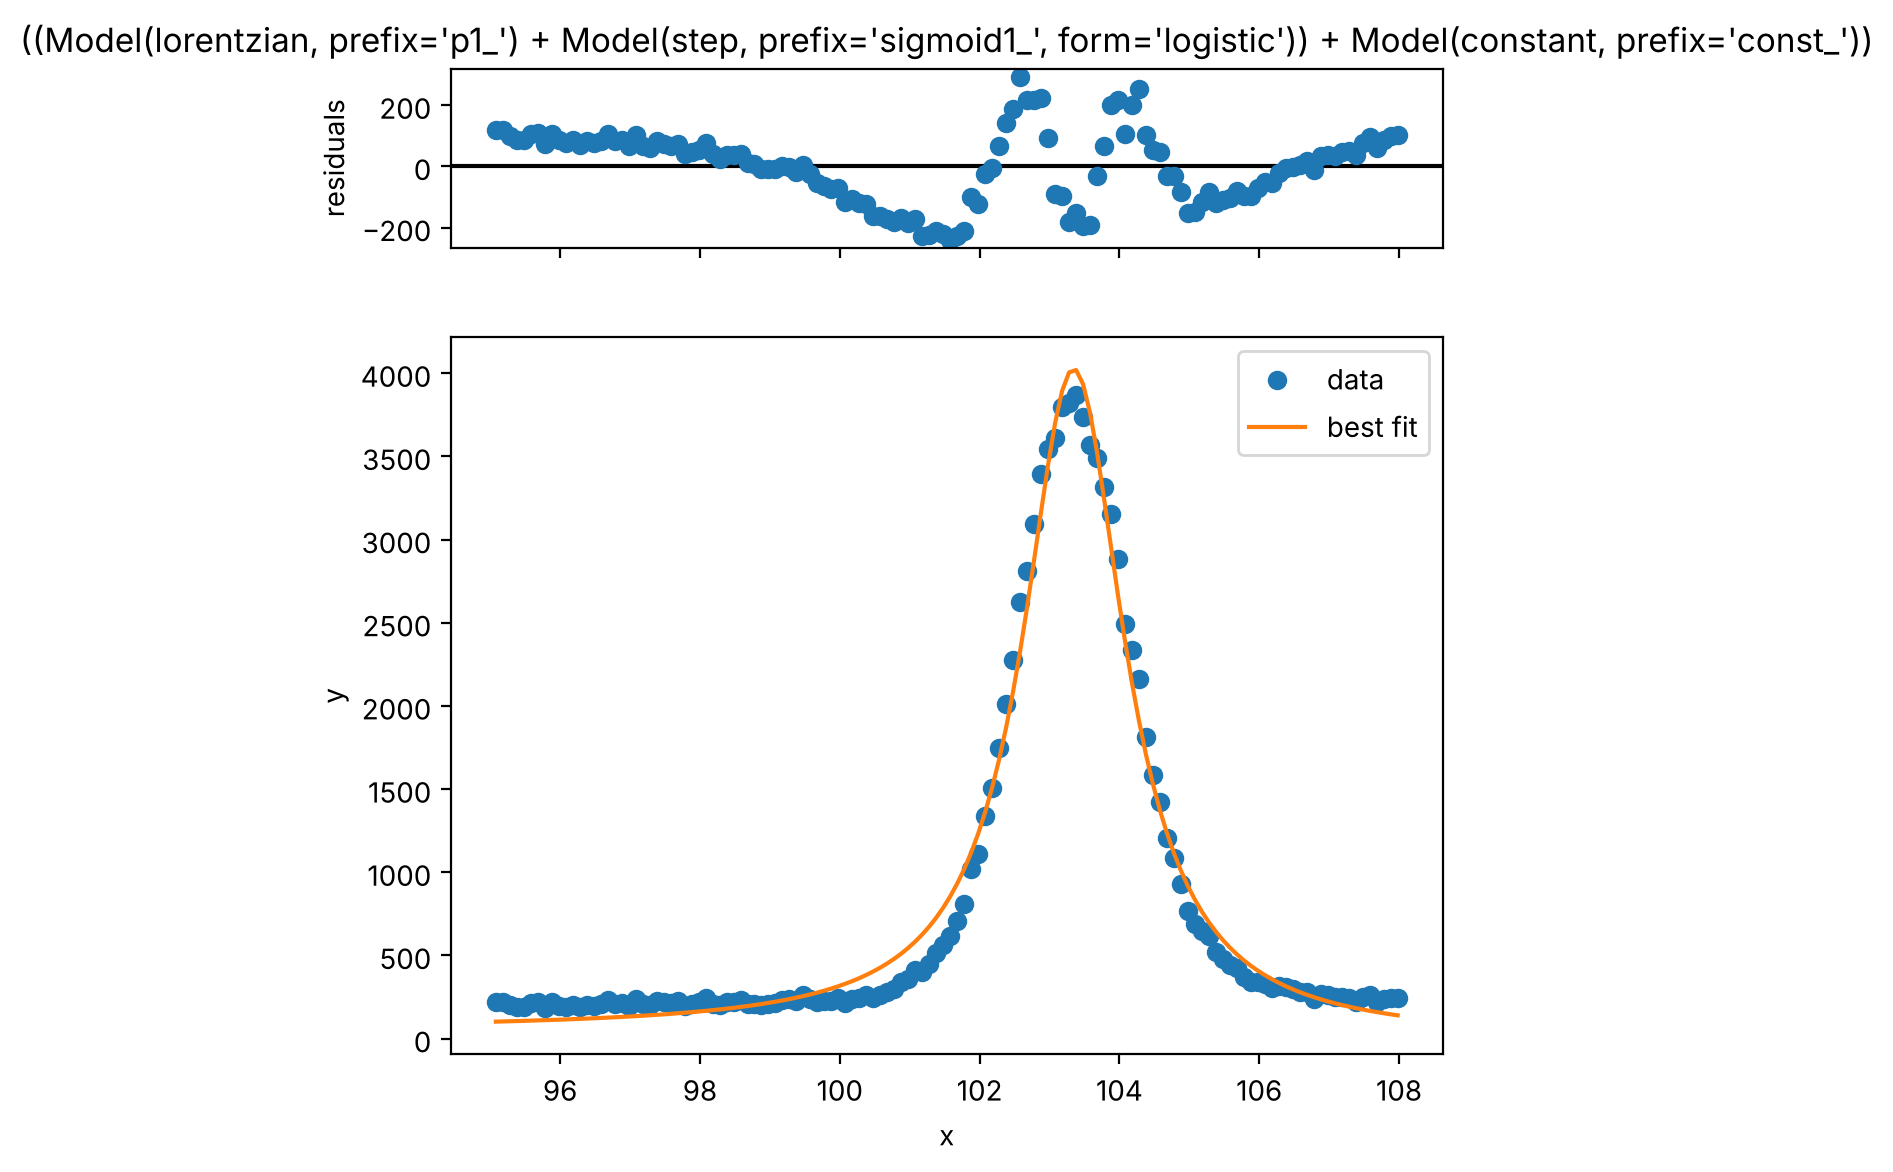

In [ ]:
resultado_fit.plot();

Vamos observar a análise dos resíduos.

p-valor de Shapiro-Wilk dos resíduos: 0.00489


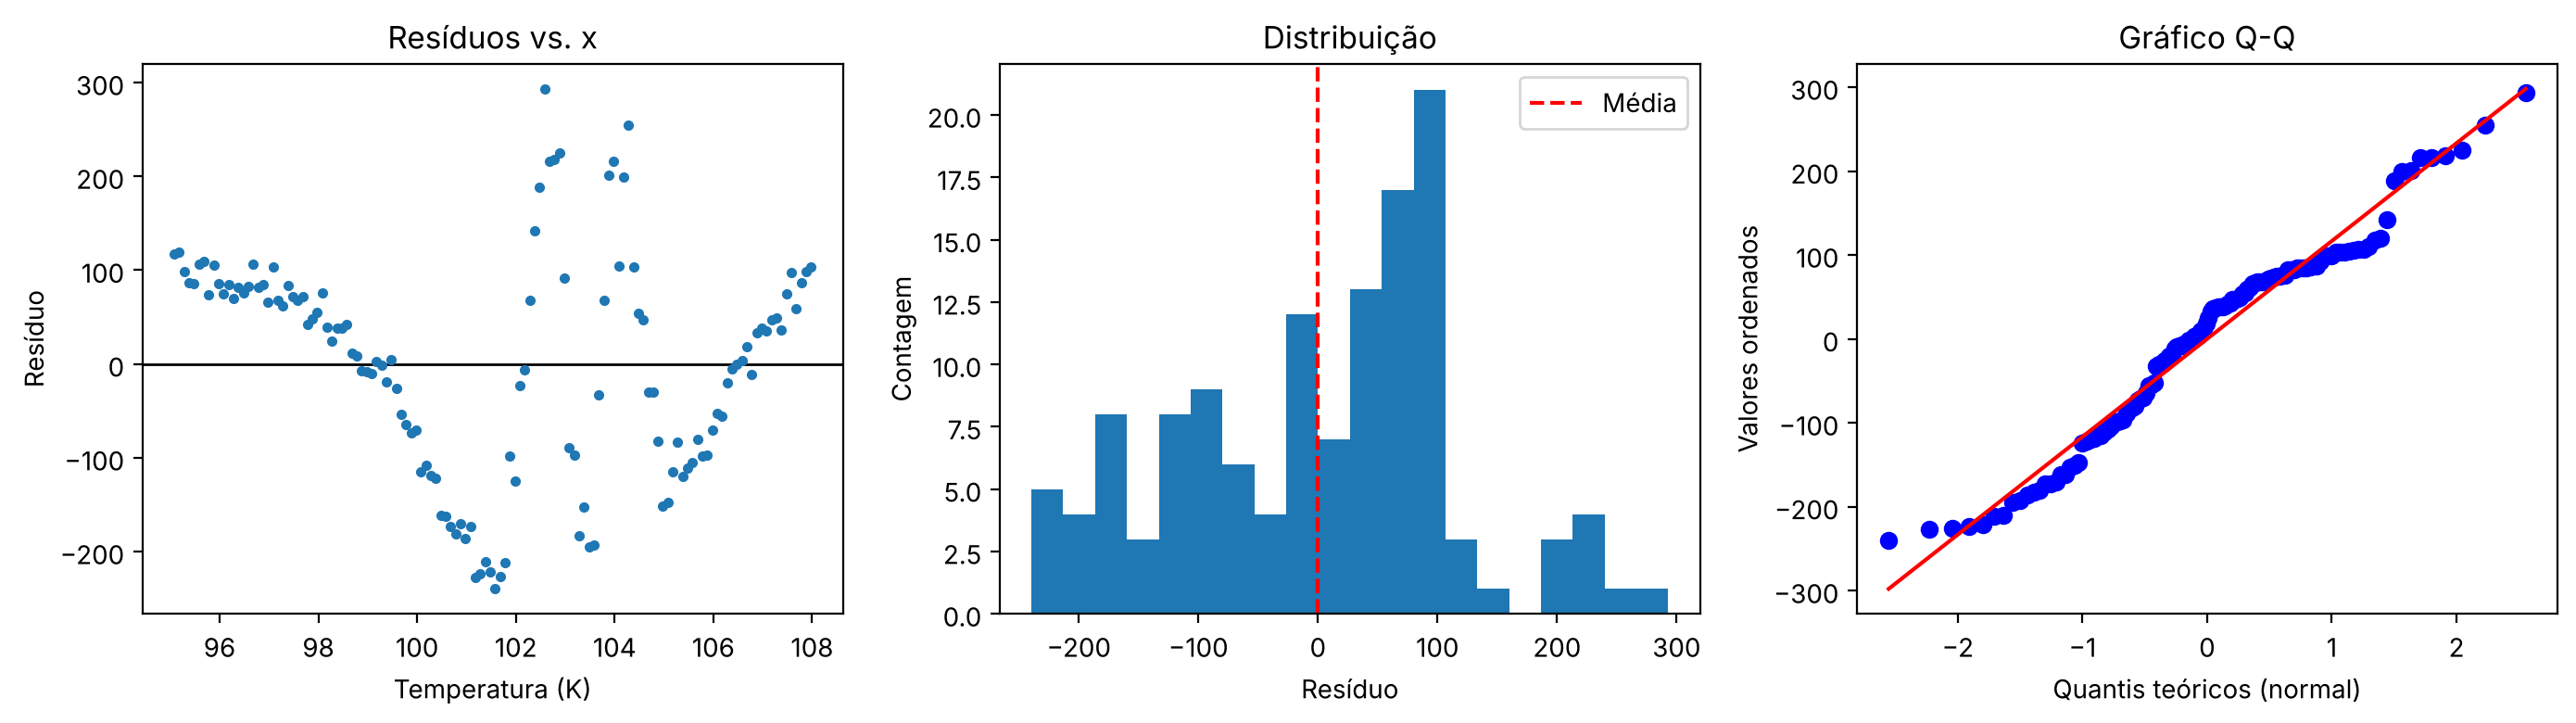

In [ ]:
analise_residuos(dados_x, dados_y, resultado_fit.best_fit)

### A contribuição de cada componente

Novamente, podemos investigar a contribuição de cada componente.

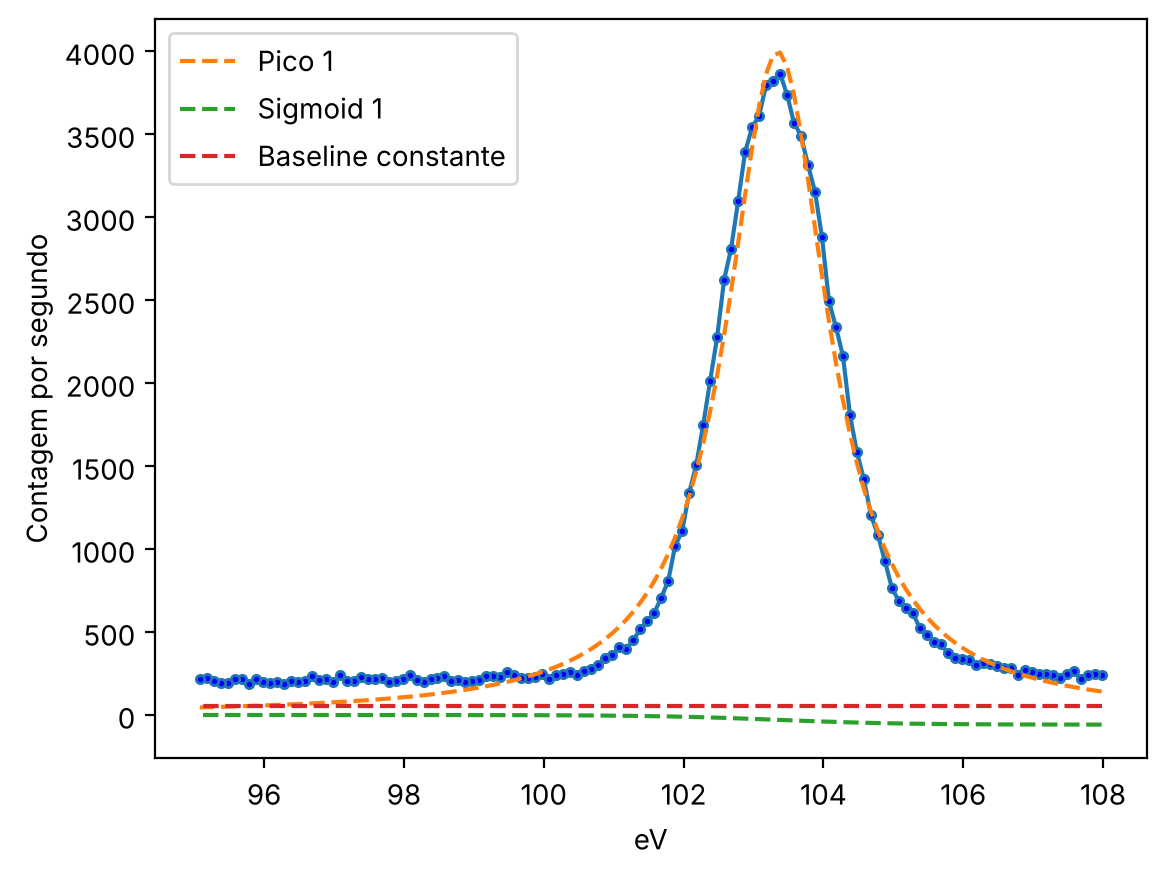

In [ ]:
componentes = resultado_fit.eval_components(x=dados_x)

fig, eixo = plt.subplots()
eixo.plot(dados_x, dados_y, marker="o", markerfacecolor="blue", markersize=3)
eixo.plot(dados_x, componentes["p1_"], "--", label="Pico 1")
eixo.plot(dados_x, componentes["sigmoid1_"], "--", label="Sigmoid 1")
eixo.plot(
    dados_x,
    np.ones(len(dados_x)) * componentes["const_"],
    "--",
    label="Baseline constante",
)
eixo.set(xlabel="eV", ylabel="Contagem por segundo")
eixo.legend();

> ⚠️ **O que aconteceu aqui com os meus dados** (teste feito com lmfit 1.3.4; em outra versão os números podem mudar um pouco)
>
> R² = 0,988, menor que nas outras abordagens. As "caudas" da Lorentziana são longas demais: a linha de base caiu para ~57 (o fundo real é ~210), e a sigmoide ficou negativa, descendo para o lado de maior energia, que é o contrário do esperado.

### Estratégia avançada: estudando os picos isoladamente

Como na aula, vamos testar picos **Voigt** no lugar dos Lorentzianos. A Voigt tem um parâmetro a mais (`gamma`), o que dificulta o ajuste. Por isso, usamos o ajuste que já temos para conseguir os palpites iniciais: eliminamos as contribuições de tudo que não for o pico estudado.

#### Investigando o pico 1 isoladamente

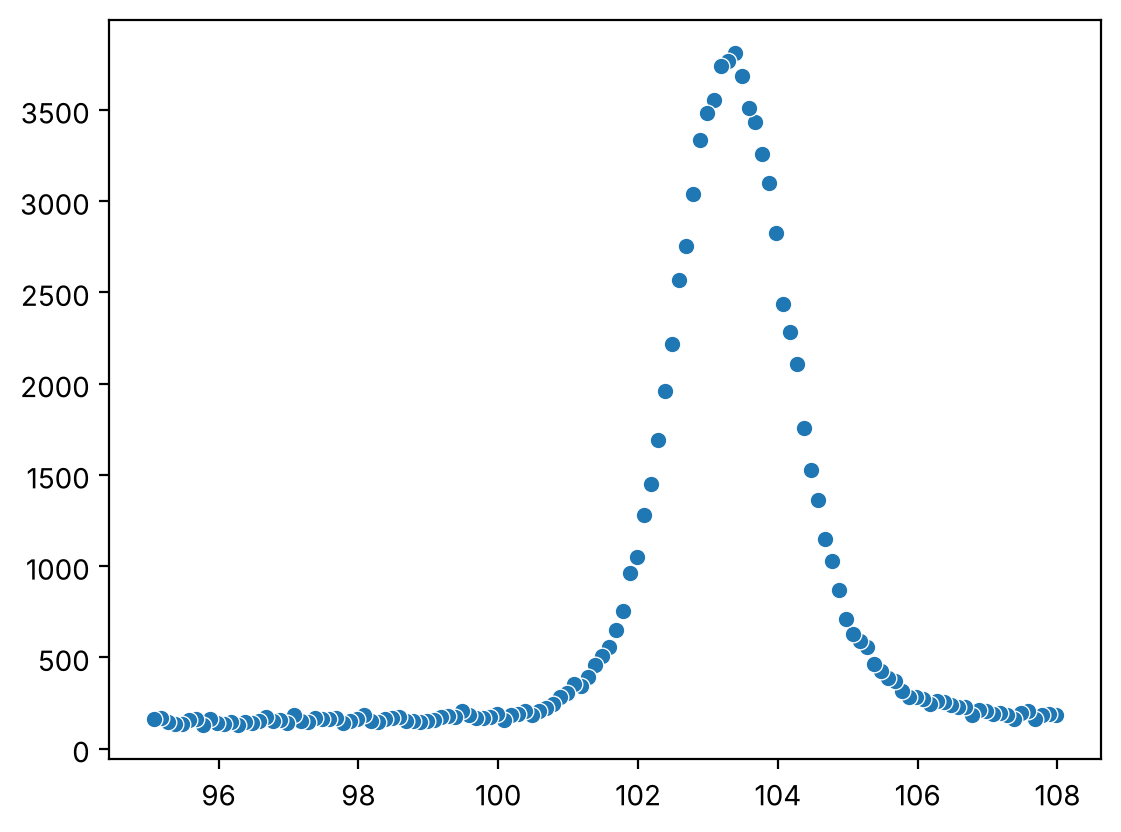

In [ ]:
eliminar = ["const_"]

y_mod = np.copy(dados_y)

for nome in eliminar:
   y_mod -= componentes[nome]

sns.scatterplot(x=dados_x, y=y_mod);

Vamos criar um modelo apenas com um pico Voigtiano, sua sigmoide e uma linha de base constante.

In [ ]:
modelo_pico1 = VoigtModel(prefix="p1_")

modelo_sigmoid1 = StepModel(
    prefix="sigmoid1_", form="logistic", independent_vars=["x"]
)

modelo_constante = ConstantModel(prefix="const_")

modelo_composto = (
    modelo_pico1
    + modelo_sigmoid1
    + modelo_constante
)

Precisamos dos parâmetros. Como na aula, usamos o `guess` para a Voigtiana e deixamos o `gamma` livre.

In [ ]:
params_pico1 = modelo_pico1.guess(y_mod, x=dados_x)
params_sigmoid1 = modelo_sigmoid1.make_params()
params_constante = modelo_constante.make_params()

params = (
    params_pico1
    + params_sigmoid1
    + params_constante
)

params["p1_gamma"].set(vary=True)

params["sigmoid1_center"].set(vary=False, expr="p1_center")
params["sigmoid1_sigma"].set(vary=False, expr="p1_sigma")

params["const_c"].set(value=min(y_mod))

params

name,value,initial value,min,max,vary,expression
p1_amplitude,14912.4110,14912.411048099624,-inf,inf,True,
p1_center,103.380054,103.38005400000002,-inf,inf,True,
p1_sigma,0.58500000,0.5849999999999852,0.00000000,inf,True,
p1_gamma,0.58500000,None,-inf,inf,True,
p1_fwhm,2.10675502,None,-inf,inf,False,1.0692*p1_gamma+sqrt(0.8664*p1_gamma**2+5.545083*p1_sigma**2)
p1_height,5320.27108,None,-inf,inf,False,"(p1_amplitude/(max(1e-15, p1_sigma*sqrt(2*pi))))*real(wofz((1j*p1_gamma)/(max(1e-15, p1_sigma*sqrt(2)))))"
sigmoid1_amplitude,1.00000000,None,-inf,inf,True,
sigmoid1_center,103.380054,None,-inf,inf,False,p1_center
sigmoid1_sigma,0.58500000,None,-inf,inf,False,p1_sigma
const_c,127.702149,127.70214860683589,-inf,inf,True,


Vejamos o resultado.

[[Model]]
    ((Model(voigt, prefix='p1_') + Model(step, prefix='sigmoid1_', form='logistic')) + Model(constant, prefix='const_'))
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 36
    # data points      = 130
    # variables        = 6
    chi-square         = 108781.903
    reduced chi-square = 877.273409
    Akaike info crit   = 886.843556
    Bayesian info crit = 904.048762
    R-squared          = 0.99924596
[[Variables]]
    p1_amplitude:        8113.68750 +/- 78.5676854 (0.97%) (init = 14912.41)
    p1_center:           103.335092 +/- 0.00277868 (0.00%) (init = 103.3801)
    p1_sigma:            0.71818166 +/- 0.01077564 (1.50%) (init = 0.585)
    p1_gamma:            0.20844698 +/- 0.01891720 (9.08%) (init = 0.585)
    p1_fwhm:             1.92513920 +/- 0.00737528 (0.38%) == '1.0692*p1_gamma+sqrt(0.8664*p1_gamma**2+5.545083*p1_sigma**2)'
    p1_height:           3627.40562 +/- 12.7162940 (0.35%) == '(p1_amplitude/(max(1e-15, p1_sigma*sqrt(2*pi))))

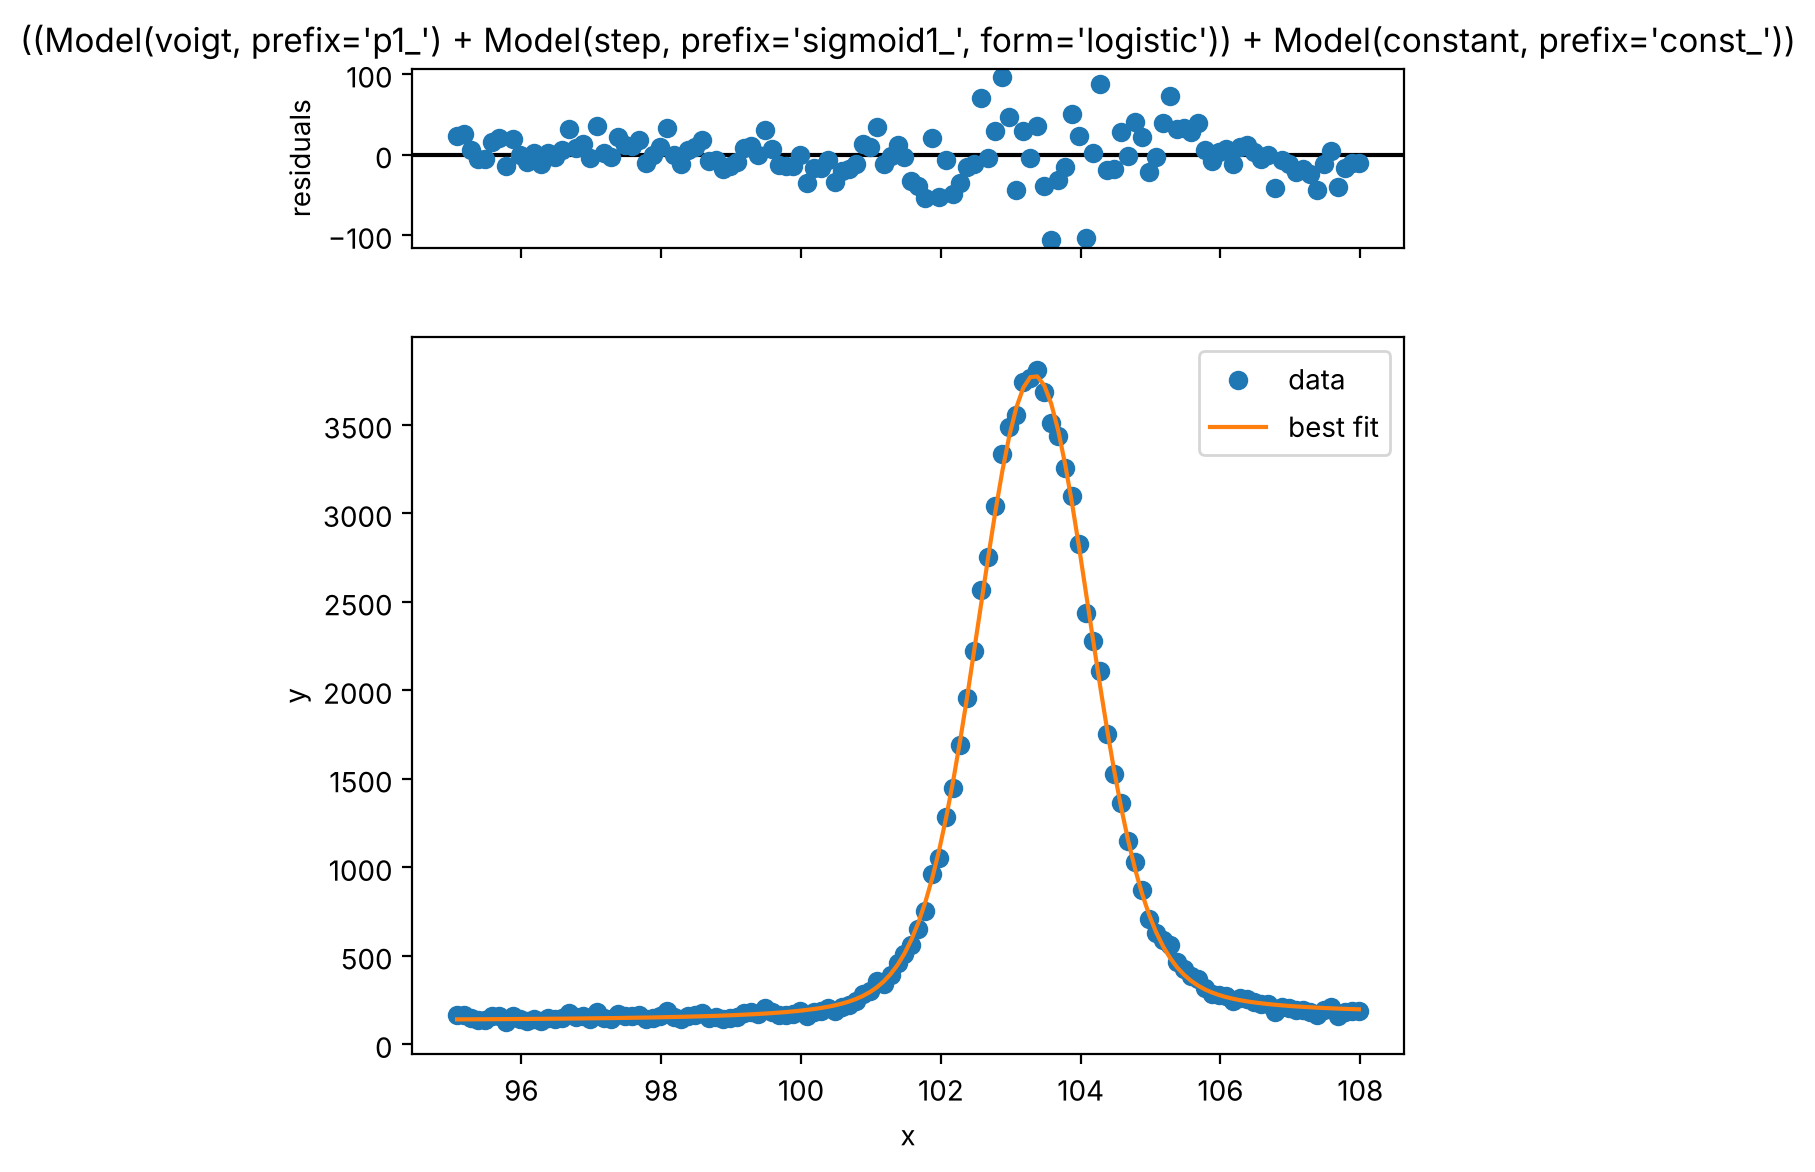

In [ ]:
resultado_fit = modelo_composto.fit(y_mod, params, x=dados_x)

print(resultado_fit.fit_report())

resultado_fit.plot();

Vejamos as componentes obtidas.

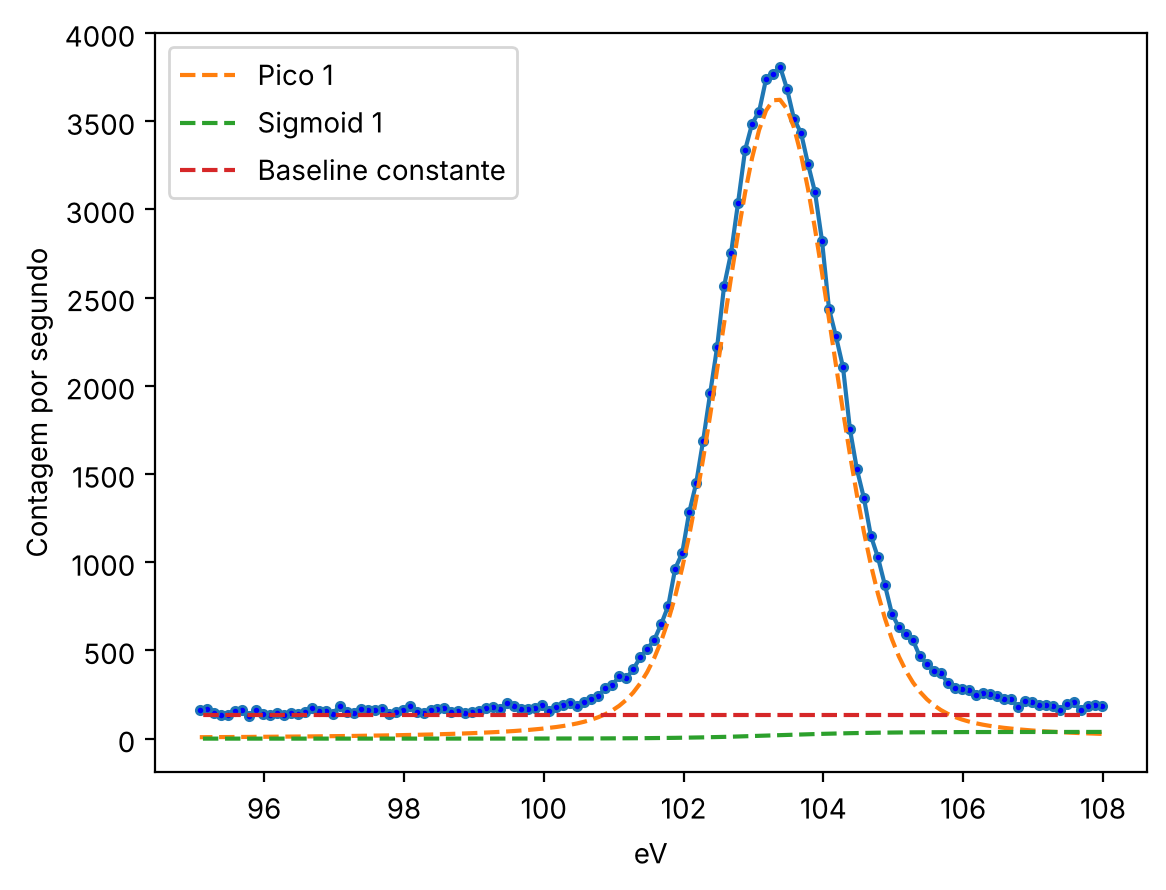

In [ ]:
componentes = resultado_fit.eval_components(x=dados_x)

fig, eixo = plt.subplots()
eixo.plot(dados_x, y_mod, marker="o", markerfacecolor="blue", markersize=3)
eixo.plot(dados_x, componentes["p1_"], "--", label="Pico 1")
eixo.plot(dados_x, componentes["sigmoid1_"], "--", label="Sigmoid 1")
eixo.plot(
    dados_x,
    np.ones(len(dados_x)) * componentes["const_"],
    "--",
    label="Baseline constante",
)
eixo.set(xlabel="eV", ylabel="Contagem por segundo")
eixo.legend();

Vamos guardar o objeto de parâmetros que obtivemos.

In [ ]:
params_pico1 = resultado_fit.params.copy()

#### Juntando os resultados

Vamos retornar aos dados originais e ao modelo original com 1 pico, agora Voigtianos.

In [ ]:
modelo_pico1 = VoigtModel(prefix="p1_")

modelo_sigmoid1 = StepModel(
    prefix="sigmoid1_", form="logistic", independent_vars=["x"]
)

modelo_constante = ConstantModel(prefix="const_")

modelo_composto = (
    modelo_pico1
    + modelo_sigmoid1
    + modelo_constante
)

Os parâmetros que usaremos serão os obtidos dos ajustes isolados.

In [ ]:
params = params_pico1


params

name,value,standard error,relative error,initial value,min,max,vary,expression
p1_amplitude,8113.68750,78.5676854,(0.97%),14912.411048099624,-inf,inf,True,
p1_center,103.335092,0.00277868,(0.00%),103.38005400000002,-inf,inf,True,
p1_sigma,0.71818166,0.01077564,(1.50%),0.5849999999999852,0.00000000,inf,True,
p1_gamma,0.20844698,0.01891720,(9.08%),0.5849999999999852,-inf,inf,True,
p1_fwhm,1.92513920,0.00737528,(0.38%),2.106755023340006,-inf,inf,False,1.0692*p1_gamma+sqrt(0.8664*p1_gamma**2+5.545083*p1_sigma**2)
p1_height,3627.40562,12.7162940,(0.35%),5320.271078073391,-inf,inf,False,"(p1_amplitude/(max(1e-15, p1_sigma*sqrt(2*pi))))*real(wofz((1j*p1_gamma)/(max(1e-15, p1_sigma*sqrt(2)))))"
sigmoid1_amplitude,38.0551089,7.40238058,(19.45%),1.0,-inf,inf,True,
sigmoid1_center,103.335092,0.00277868,(0.00%),103.38005400000002,-inf,inf,False,p1_center
sigmoid1_sigma,0.71818166,0.01077564,(1.50%),0.5849999999999852,-inf,inf,False,p1_sigma
const_c,132.331450,5.04696589,(3.81%),127.70214860683589,-inf,inf,True,


Vamos ajustar o modelo.

[[Model]]
    ((Model(voigt, prefix='p1_') + Model(step, prefix='sigmoid1_', form='logistic')) + Model(constant, prefix='const_'))
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 15
    # data points      = 130
    # variables        = 6
    chi-square         = 108781.903
    reduced chi-square = 877.273409
    Akaike info crit   = 886.843556
    Bayesian info crit = 904.048762
    R-squared          = 0.99924596
[[Variables]]
    p1_amplitude:        8113.68644 +/- 78.5678711 (0.97%) (init = 8113.688)
    p1_center:           103.335092 +/- 0.00277868 (0.00%) (init = 103.3351)
    p1_sigma:            0.71818193 +/- 0.01077565 (1.50%) (init = 0.7181817)
    p1_gamma:            0.20844661 +/- 0.01891725 (9.08%) (init = 0.208447)
    p1_fwhm:             1.92513939 +/- 0.00737528 (0.38%) == '1.0692*p1_gamma+sqrt(0.8664*p1_gamma**2+5.545083*p1_sigma**2)'
    p1_height:           3627.40537 +/- 12.7162922 (0.35%) == '(p1_amplitude/(max(1e-15, p1_sigma*sqrt(2

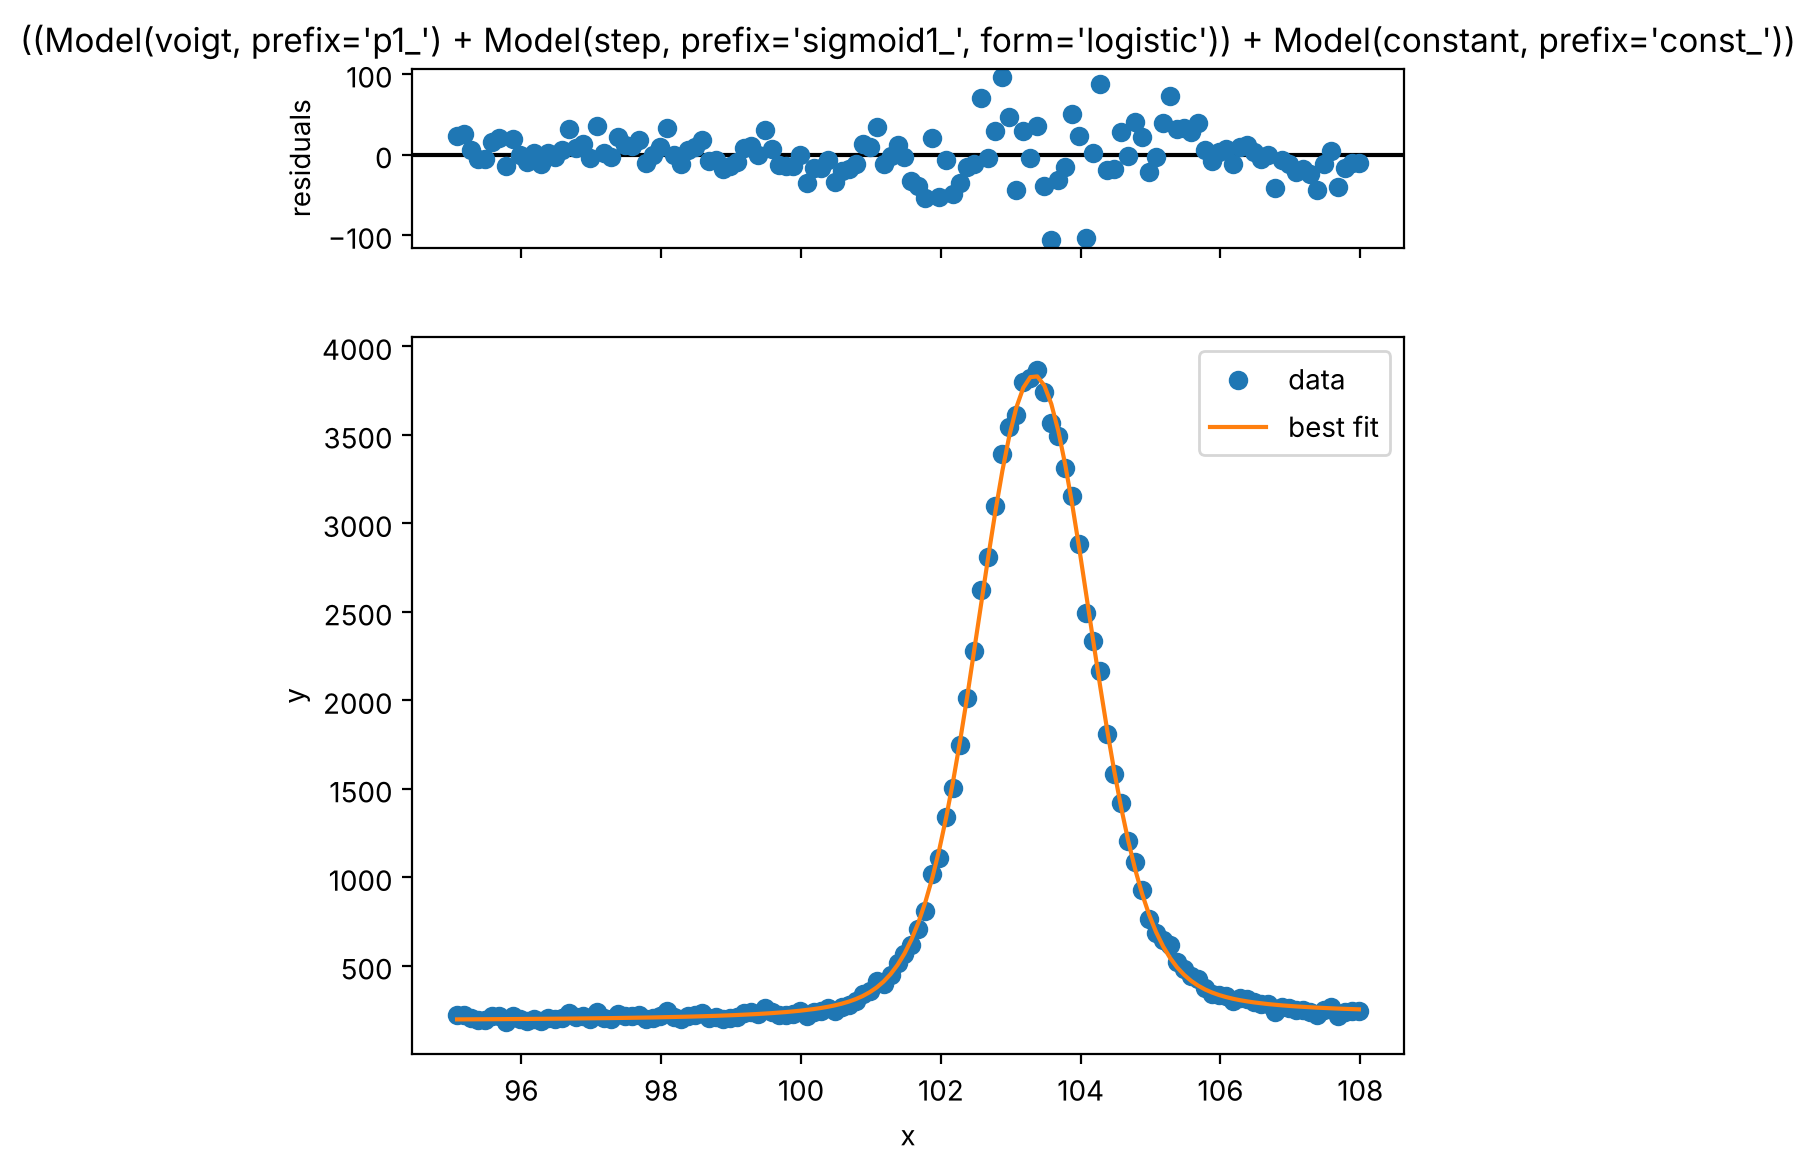

In [ ]:
resultado_fit = modelo_composto.fit(dados_y, params, x=dados_x)

print(resultado_fit.fit_report())

resultado_fit.plot();

> ⚠️ **O que aconteceu aqui com os meus dados** (teste feito com lmfit 1.3.4; em outra versão os números podem mudar um pouco)
>
> Aqui a receita da aula **funciona**: R² = 0,9992 e pico em 103,34 eV, o mesmo resultado do outro notebook. Com um pico só e um fundo quase plano, não há sigmoides vizinhas para se cancelar.

Vamos observar a análise dos resíduos.

p-valor de Shapiro-Wilk dos resíduos: 0.000116


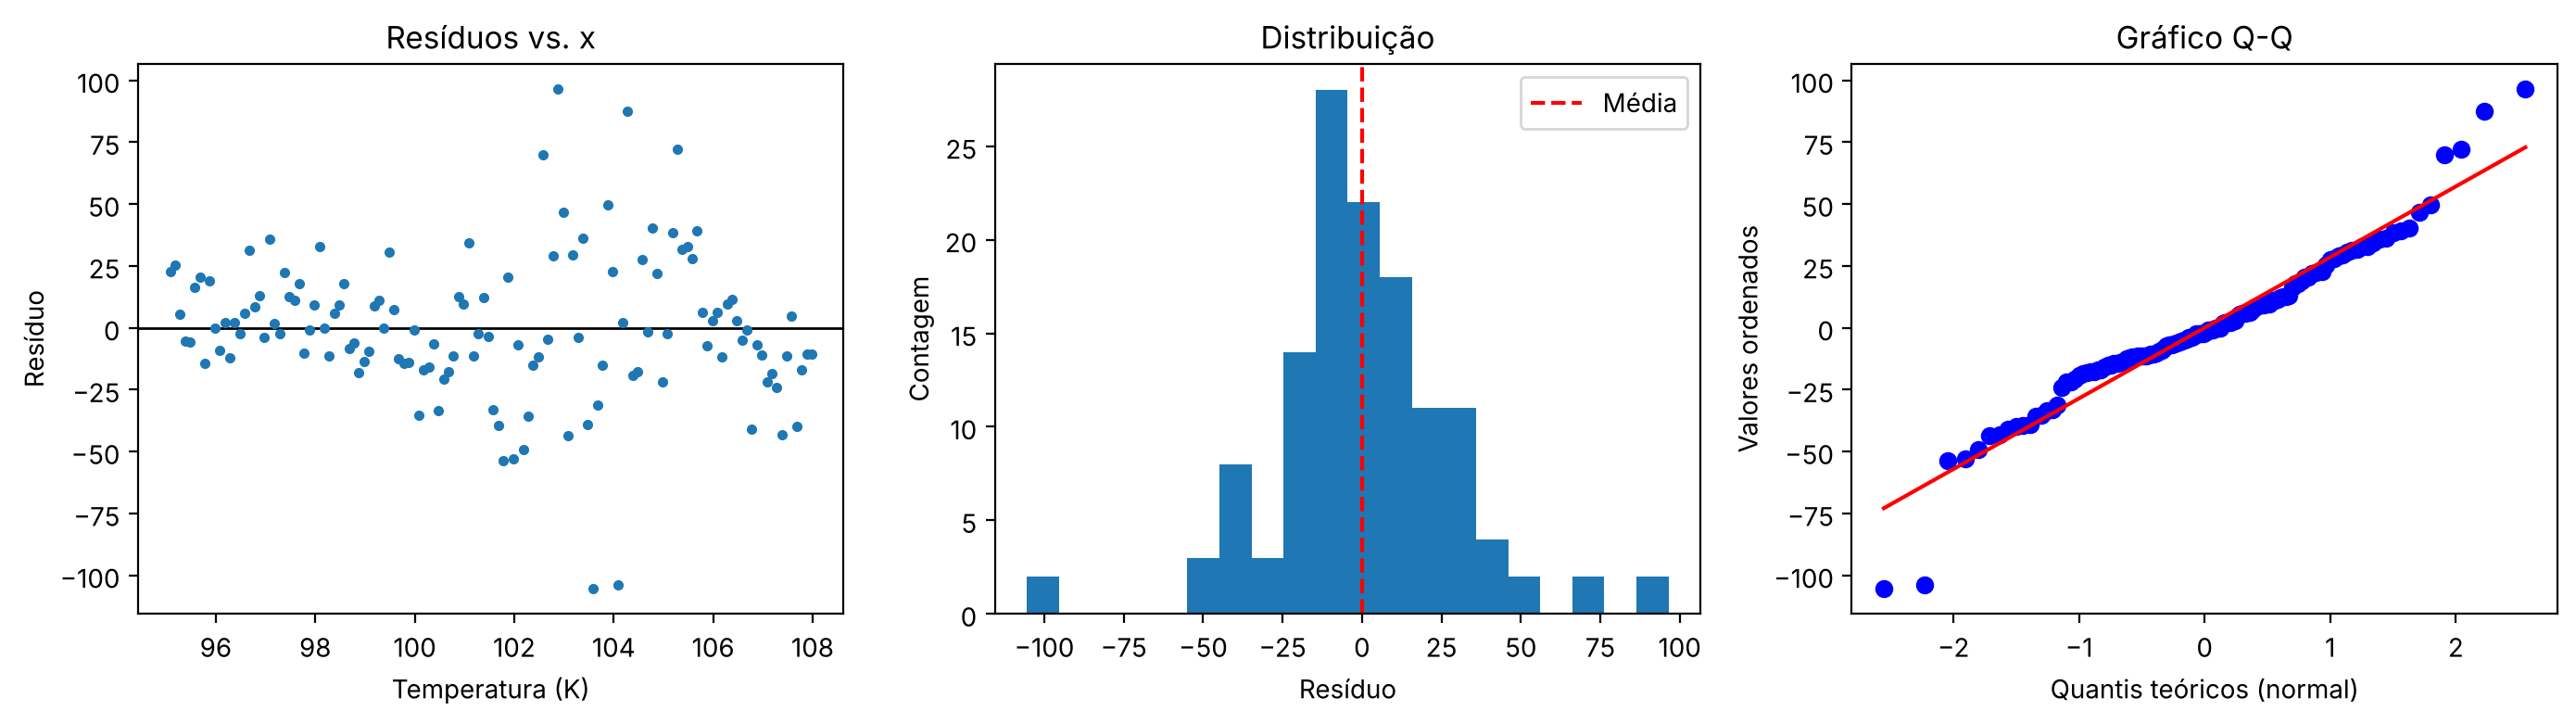

In [ ]:
analise_residuos(dados_x, dados_y, resultado_fit.best_fit)

Para encerrar, faremos a análise das componentes.

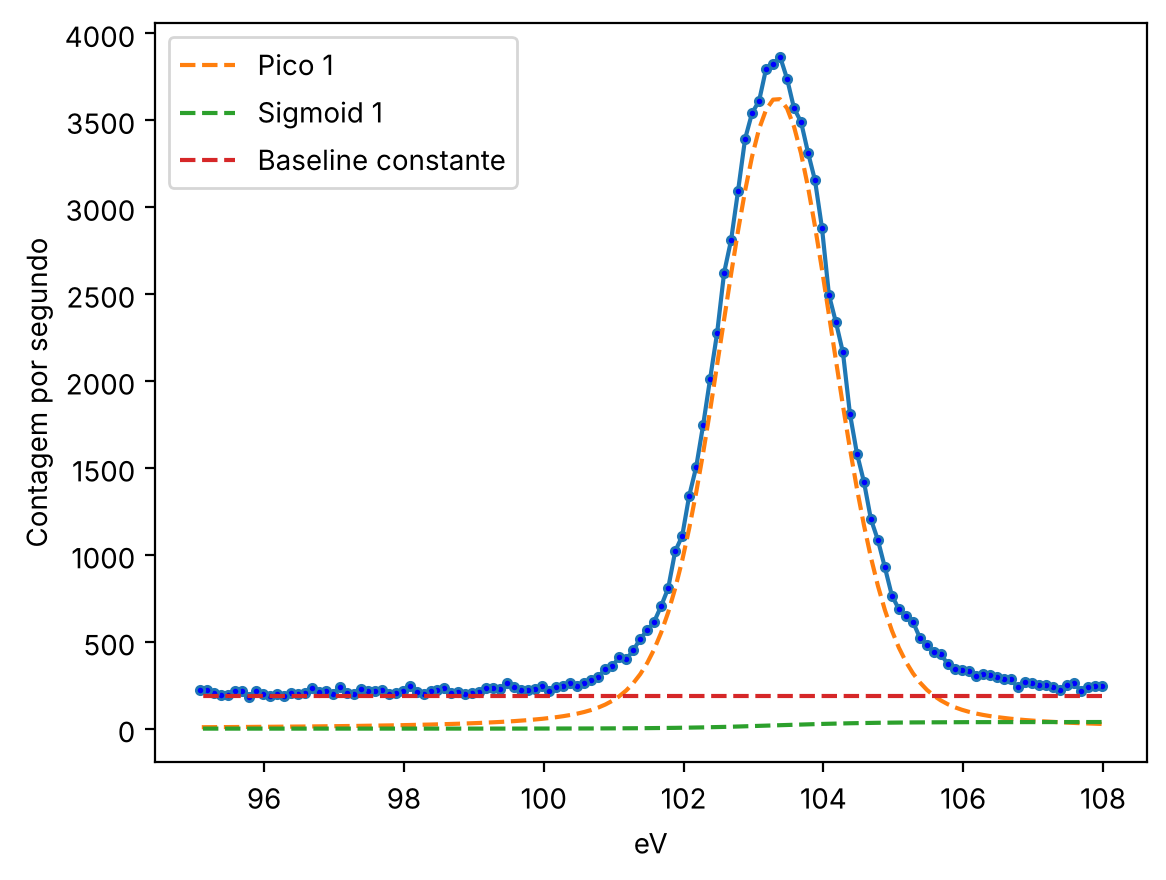

In [ ]:
componentes = resultado_fit.eval_components(x=dados_x)

fig, eixo = plt.subplots()
eixo.plot(dados_x, dados_y, marker="o", markerfacecolor="blue", markersize=3)
eixo.plot(dados_x, componentes["p1_"], "--", label="Pico 1")
eixo.plot(dados_x, componentes["sigmoid1_"], "--", label="Sigmoid 1")
eixo.plot(
    dados_x,
    np.ones(len(dados_x)) * componentes["const_"],
    "--",
    label="Baseline constante",
)
eixo.set(xlabel="eV", ylabel="Contagem por segundo")
eixo.legend();